# 04 · Web 后端基础（基础知识）


来源：[飞书讲义《04-Web后端基础(基础知识)》](https://heuqqdmbyk.feishu.cn/wiki/MQ95wDTtji6ob6kiRkyc9jamnwg)。整理日期：2026-09-28。

本章用 Spring Boot 建立 Java Web 服务，学习 HTTP 请求与响应，再把用户列表案例拆成 Controller、Service、Dao 三层，使用 Spring IOC/DI 管理对象与依赖。按原讲义顺序完整保留正文、24 段原代码、50 张配图，以及 3 张普通表格和 2 张嵌入知识表格。

只在影响理解和跟练的位置加入“补充”或“勘误”。第 4.6 节合并出完整用户列表工程，并将效果图中的数据转成可复制文本、补齐前端页面。图片已内嵌，可离线阅读；首次下载依赖及使用公共前端脚本地址仍需要网络。


## 本章学习路线（补充）

上一章的 Maven 解决项目结构、依赖和构建；本章把 Java 程序变成能接收浏览器请求的服务，再让第二章的 Vue 页面调用自己编写的接口。

| 学习顺序 | 要能回答的问题 | 对应小节 |
| --- | --- | --- |
| 跑通入口 | 浏览器的 `/hello` 为什么能执行一个 Java 方法？ | 1 SpringBootWeb入门 |
| 看懂通信 | 参数、状态码、响应内容分别放在 HTTP 的哪里？ | 2 HTTP协议 |
| 串起案例 | `user.txt` 怎样变成网页中的用户表格？ | 3 SpringBootWeb案例 |
| 拆分职责 | Controller、Service、Dao 为什么要分开？对象由谁创建和注入？ | 4 分层解耦 |
| 独立跟练 | 能否只看文件路径和完整代码，启动 `/list` 与 `/user.html`？ | 4.6 完整用户列表案例 |

原讲义包含逐步改造的同名类，阅读时按顺序理解变化；动手时以第 4.6 节的一套完整文件为准。Java、XML、HTML 示例保留在 Markdown 代码块中，应复制到对应工程文件，不在本笔记的 Python 内核中执行。


> 课程内容：
> 
> - SpringBootWeb 入门
> - Http协议
> - SpringBootWeb案例
> - 分层解耦

那在前面讲解Web前端开发的时候，我们学习了前端网页开发的三剑客HTML、CSS、JS，通过这三项技术，我们就可以制作前端页面了。 那最终，这些个页面资料，我们就可以部署在服务器上，然后打开浏览器就可以直接访问服务器上部署的前端页面了。

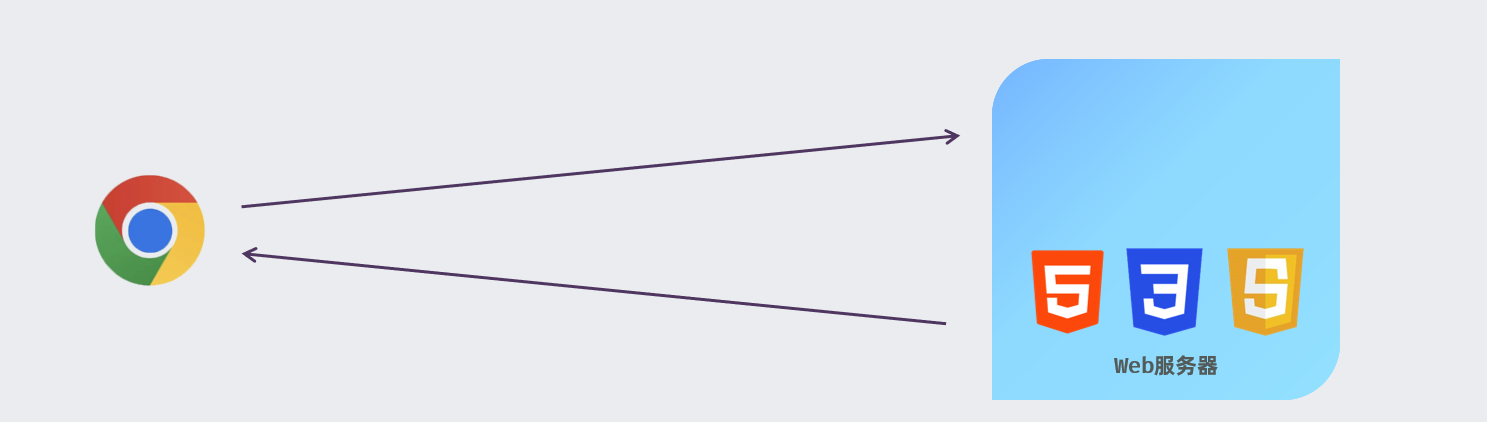

而像HTML、CSS、JS 以及图片、音频、视频等这些资源，我们都称为<strong>静态资源</strong>。 所谓静态资源，就是指在服务器上存储的不会改变的数据，通常不会根据用户的请求而变化。

> **补充：**静态资源指服务器通常直接按文件提供的资源，不代表文件永远不能修改。一个静态 HTML/JS 页面也可以在浏览器中执行脚本、发起 Ajax 请求并动态更新界面。“页面会动”和“服务端按请求生成响应”是不同角度。

那与静态资源对应的还有一类资源，就是动态资源。那所谓<strong>动态资源</strong>，就是指在服务器端上存储的，会根据用户请求和其他数据动态生成的，内容可能会在每次请求时都发生变化。比如：Servlet、JSP等(负责逻辑处理)。而Servlet、JSP这些技术现在早都被企业淘汰了，现在在企业项目开发中，都是直接基于Spring框架来构建动态资源。

> **勘误：**“Servlet、JSP 早已被企业淘汰”过于绝对。JSP 在很多新项目中使用减少，但 Servlet 仍是本章 Spring MVC + Tomcat 的底层基础：Spring MVC 的 `DispatcherServlet` 就是 Servlet。学习 Spring Boot 是减少手工配置和重复代码，并不意味着底层没有 Servlet。

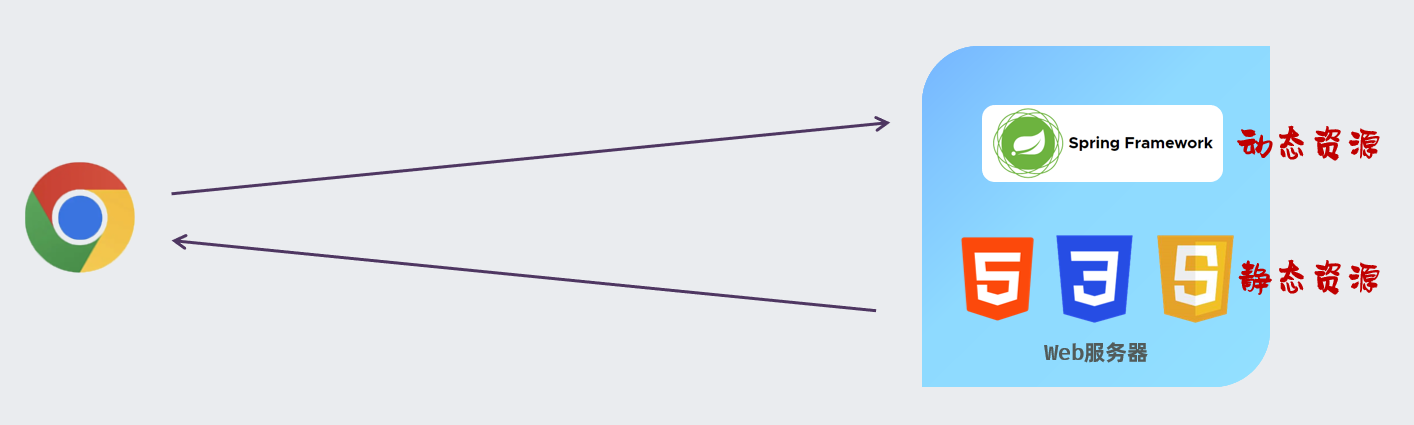

而对于我们java程序开发的动态资源来说，我们通常会将这些动态资源部署在<strong>Tomcat</strong>，这样的Web服务器中运行。 而浏览器与服务器在通信的时候，基本都是基于HTTP协议的。

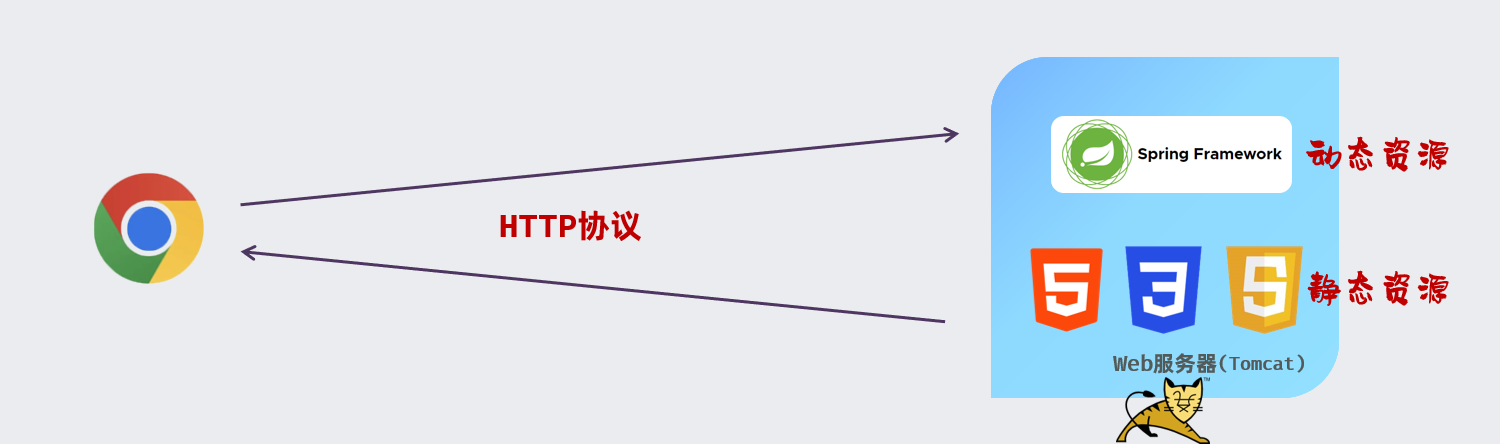

那上述所描述的这种浏览器/服务器的架构模式呢，我们称之为：<strong>BS架构</strong>。

- BS架构：Browser/Server，浏览器/服务器架构模式。客户端只需要浏览器，应用程序的逻辑和数据都存储在服务端。

    - 优点：维护方便
    - 缺点：体验一般
- CS架构：Client/Server，客户端/服务器架构模式。需要单独开发维护客户端。

    - 优点：体验不错
    - 缺点：开发维护麻烦

    > **补充：**这里列的是两类架构的常见取舍，体验好坏并不由 BS/CS 单独决定。现代浏览器应用也可以体验丰富，浏览器端会执行 JavaScript/Vue 的交互逻辑；BS 不能理解为“所有逻辑都只能在服务端执行”。权限判断和可信数据处理仍需要服务端负责。

那前面我们已经学习了静态资源开发技术，包括：HTML、CSS、JS以及JS的高级框架Vue，异步交互技术Axios。 那那接下来呢，我们就要来学习动态资料开发技术，而动态资源开发技术中像早期的Servlet、JSP这些个技术早都被企业淘汰了，现在企业开发主流的就是基于Spring体系中的框架来开发这些动态资源。 所以，我们今天的课程内容内，分为以下四个部分：

- SpringBootWeb入门
- HTTP协议
- SpringBootWeb案例
- 分层解耦


## 1 SpringBootWeb入门

那接下来呢，我们就要来讲解现在企业开发的主流技术 SpringBoot，并基于SpringBoot进行Web程序的开发 。


### 1.1 概述

在没有正式的学习SpringBoot之前，我们要先来了解下什么是Spring。

我们可以打开Spring的官网(https://spring.io)，去看一下Spring的简介：Spring makes Java simple。

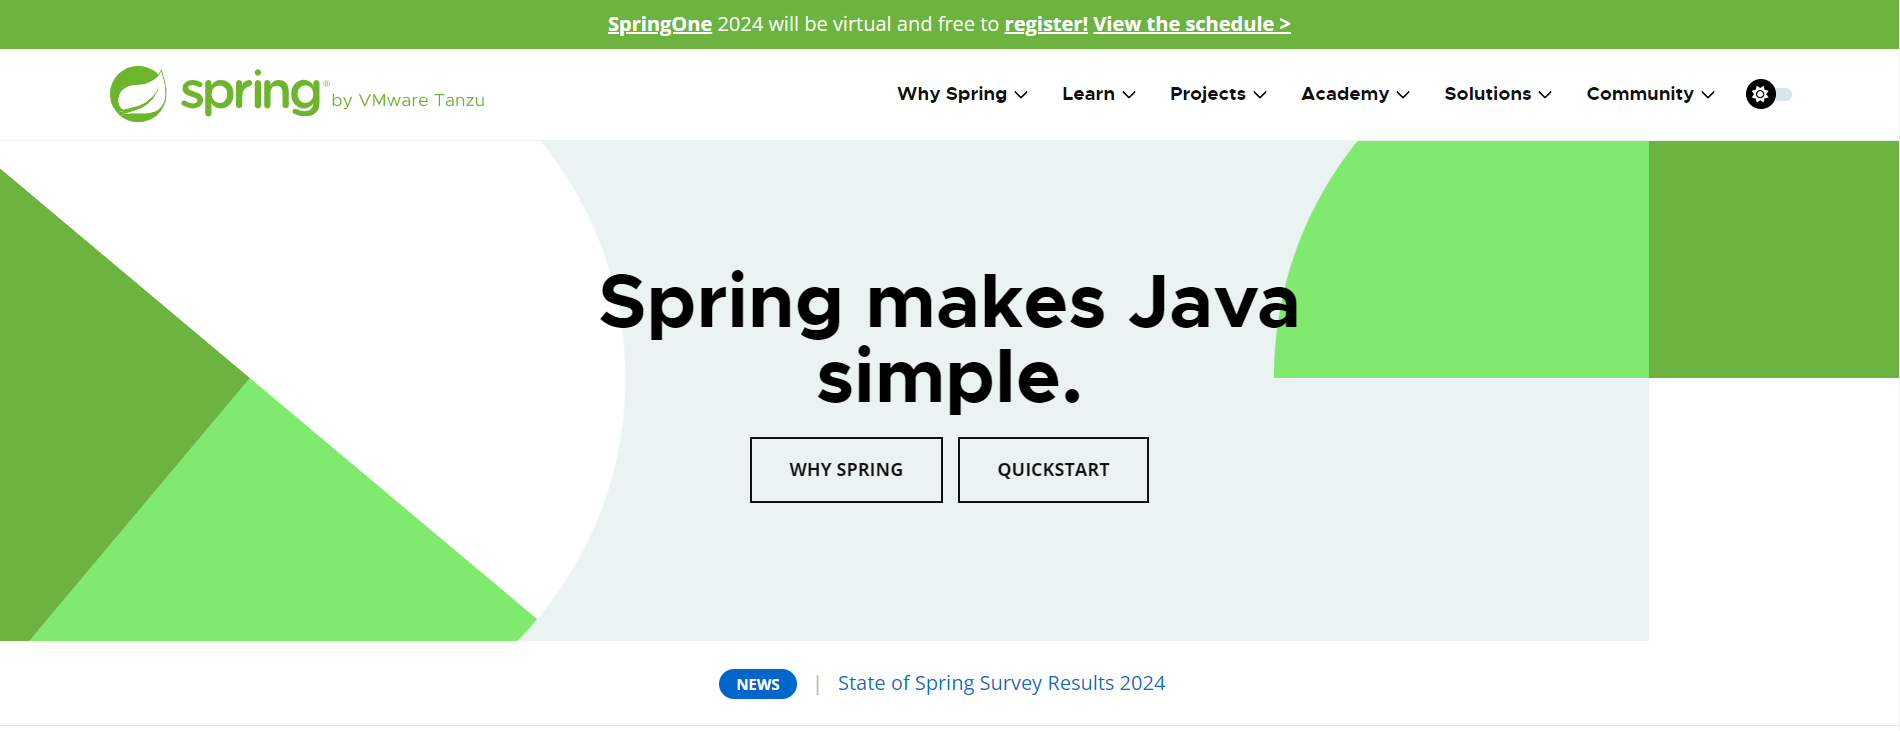

Spring的官方提供很多开源的项目，我们可以点击上面的projects，看到spring家族旗下的项目，按照流行程度排序为：

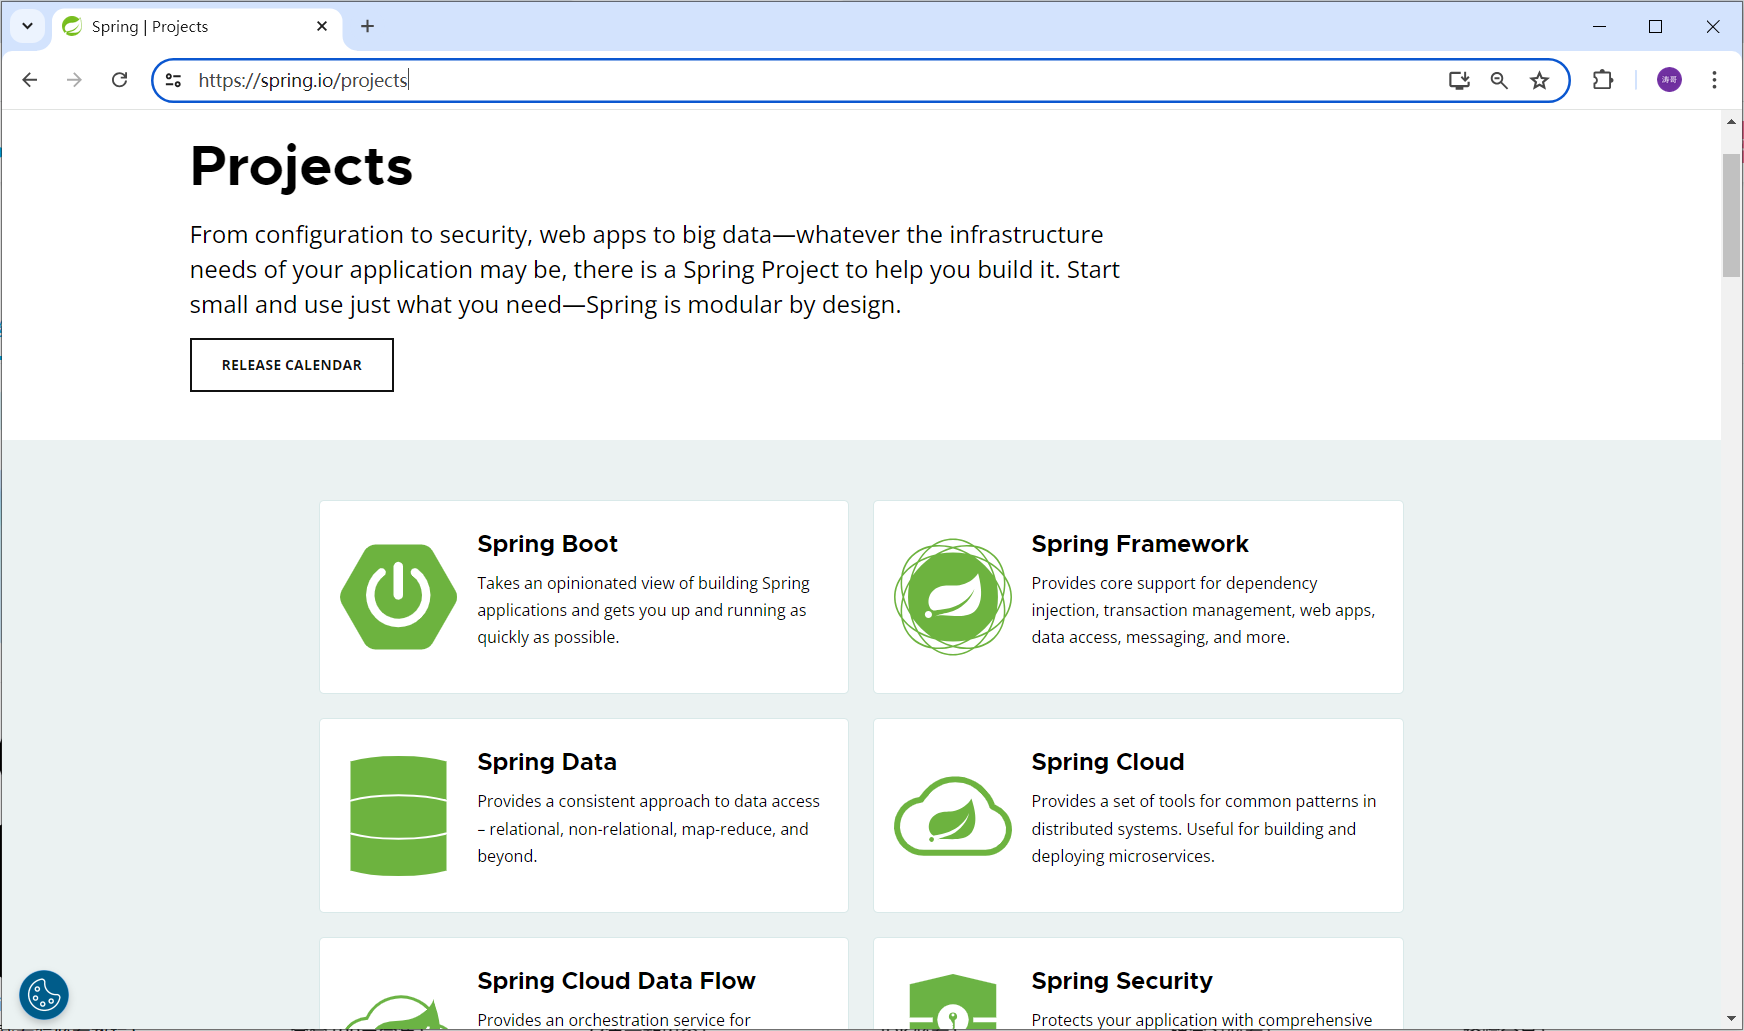

Spring发展到今天已经形成了一种开发生态圈，Spring提供了若干个子项目，每个项目用于完成特定的功能。而我们在项目开发时，一般会偏向于选择这一套spring家族的技术，来解决对应领域的问题，那我们称这一套技术为<strong>spring全家桶</strong>。

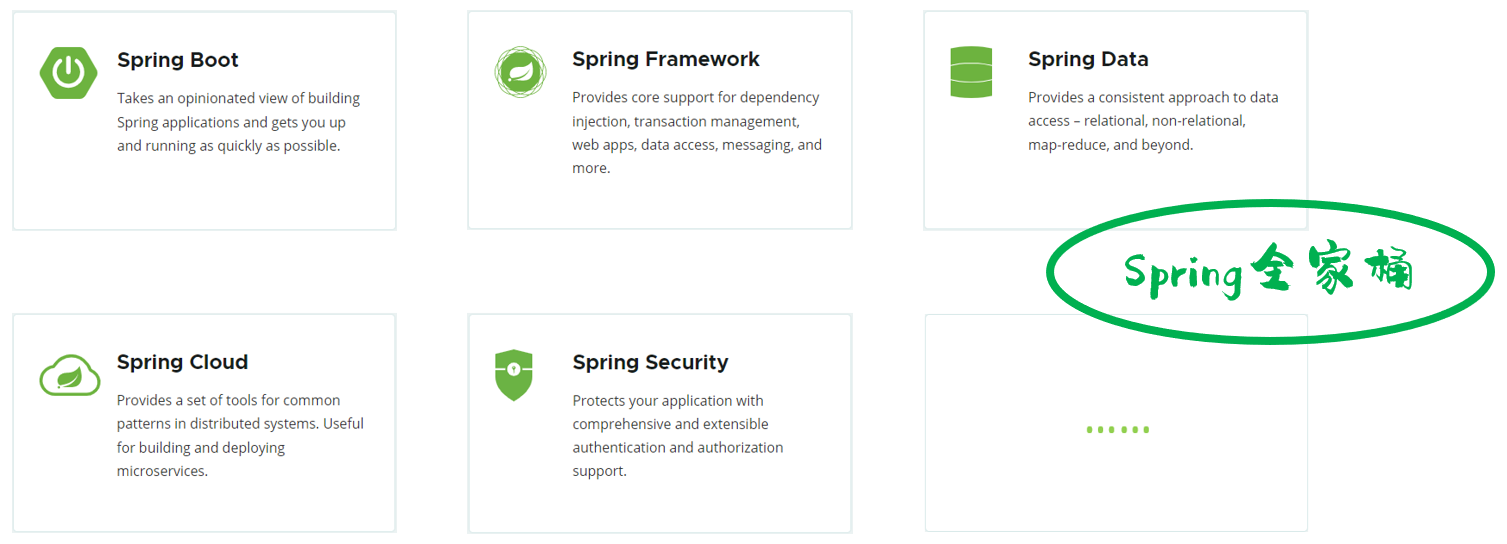

而Spring家族旗下这么多的技术，最基础、最核心的是 SpringFramework。其他的spring家族的技术，都是基于SpringFramework的，SpringFramework中提供很多实用功能，如：依赖注入、事务管理、web开发支持、数据访问、消息服务等等。

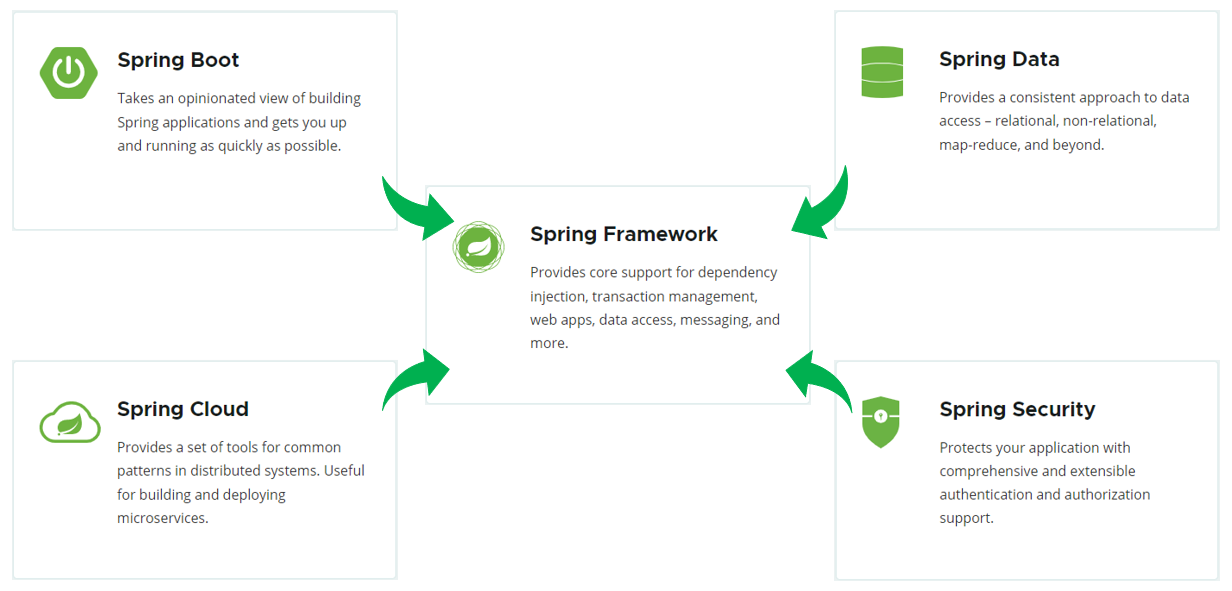

而如果我们在项目中，直接基于<strong>SpringFramework</strong>进行开发，存在两个问题：

- 配置繁琐
- 入门难度大

所以基于此呢，spring官方推荐我们从另外一个项目开始学习，那就是目前最火爆的SpringBoot。 通过springboot就可以快速的帮我们构建应用程序，所以<strong>springboot</strong>呢，最大的特点有两个 ：

- 简化配置
- 快速开发

<strong>Spring Boot 可以帮助我们非常快速的构建应用程序、简化开发、提高效率 。</strong>

<strong>而直接基于SpringBoot进行项目构建和开发，不仅是Spring官方推荐的方式，也是现在企业开发的主流。</strong>


### 1.2 入门程序


#### 1.2.1 需求

需求：基于SpringBoot的方式开发一个web应用，浏览器发起请求/hello后，给浏览器返回字符串 "Hello xxx &#126;"。

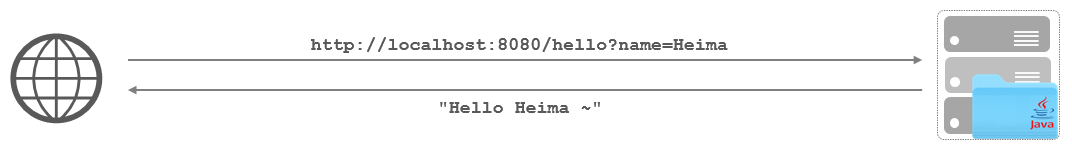


#### 1.2.2 开发步骤

第1步：创建SpringBoot工程，并勾选Web开发相关依赖

第2步：定义HelloController类，添加方法hello，并添加注解

<strong>1). 创建SpringBoot工程（需要联网）</strong>

基于Spring官方骨架，创建SpringBoot工程。

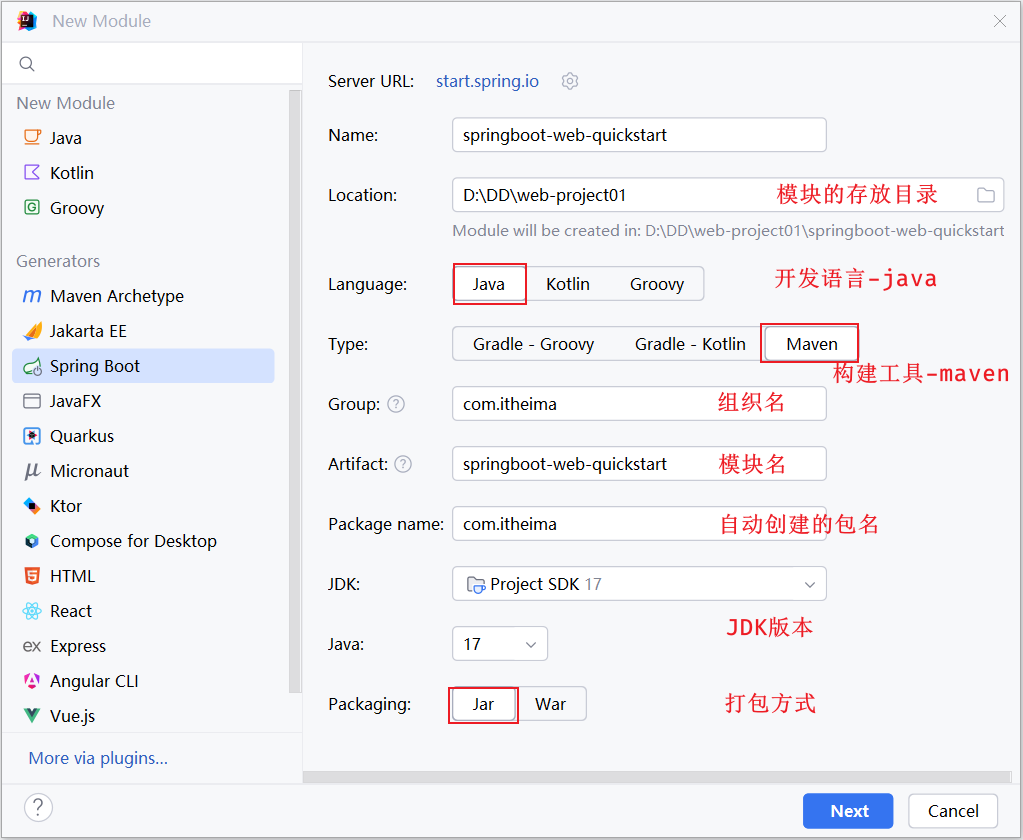

基本信息描述完毕之后，勾选web开发相关依赖。

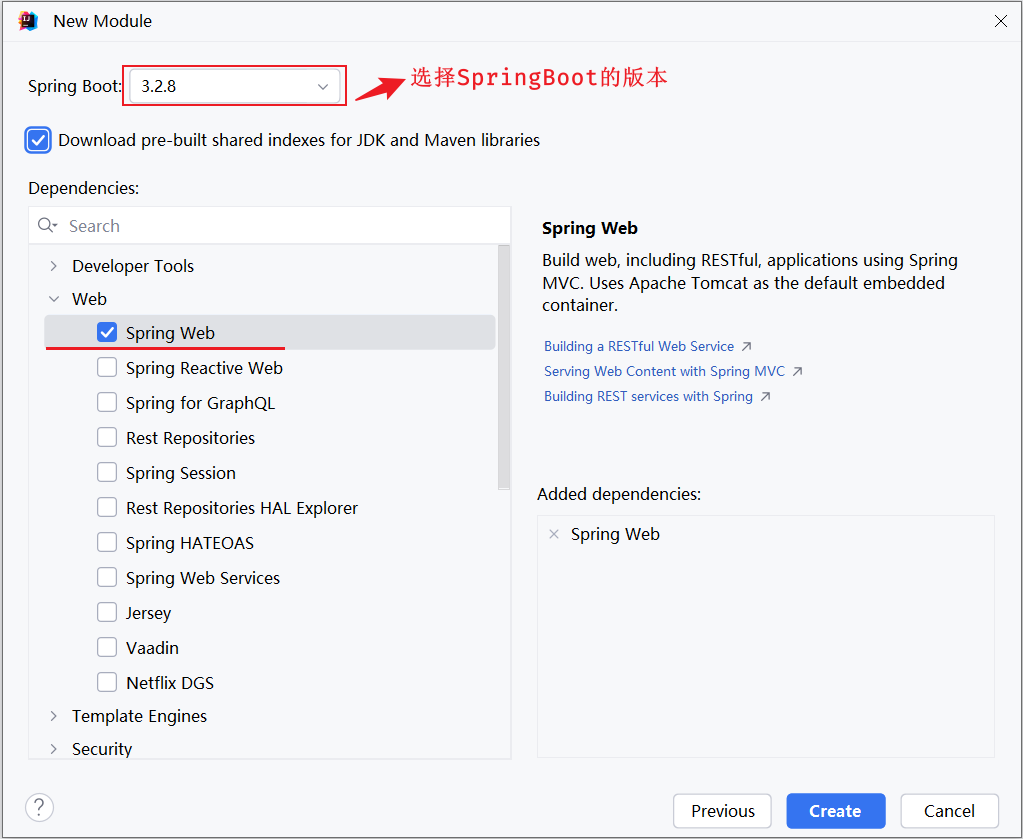

**配图操作转写：**

1. 选择 Java、Maven，Group 为 `com.itheima`，项目名可用 `springboot-web-quickstart`，包名 `com.itheima`。
2. Java 选择 `17`，Packaging 选择 `Jar`。
3. 在依赖选择页勾选 **Spring Web**。它对应本章的 `spring-boot-starter-web`，不是 Spring Reactive Web。
4. 等待项目生成和 Maven 依赖下载完成，再运行启动类。

> **补充：**本章截图同时出现 Spring Boot `3.2.8` 与 `3.1.3`。后面的完整跟练统一使用截图中的 `3.2.8`、Java `17`；这些是课程复现版本。当前脚手架的可选版本会变化，不能把新版本生成的所有依赖/插件配置原样保留后，仅降低一个父版本就认定兼容。找不到课程版本时，可以直接使用第 4.6 节给出的完整 POM。

> SpringBoot官方提供的脚手架，里面只能够选择SpringBoot的几个最新的版本，如果要选择其他相对低一点的版本，可以在springboot项目创建完毕之后，修改项目的pom.xml文件中的版本号。

点击Create之后，就会联网创建这个SpringBoot工程，创建好之后，结构如下：

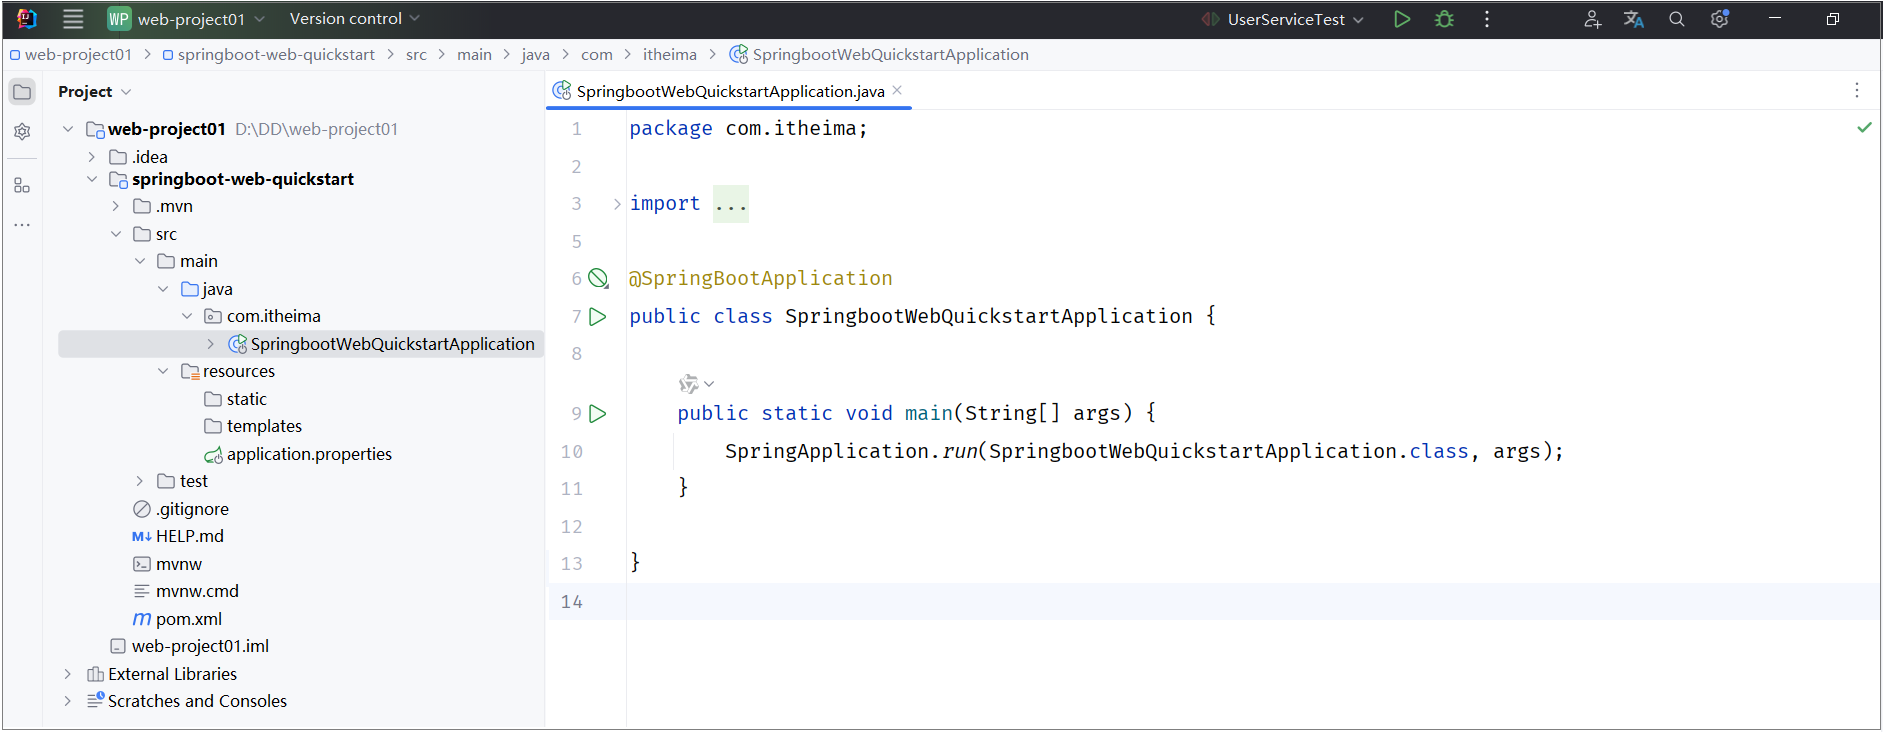

<strong>注意：在联网创建过程中，会下载相关资源(请耐心等待)</strong>

<strong>2). </strong><strong>定义HelloController类，添加方法hello，并添加注解</strong>

在<code>com.itheima</code>这个包下新建一个类：<code>HelloController</code>

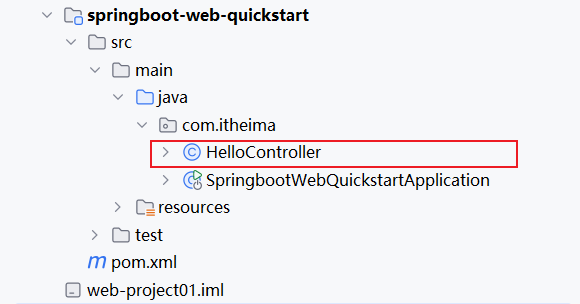

HelloController中的内容，具体如下：

````java
package com.itheima;

import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;

@RestController //标识当前类是一个请求处理类
public class HelloController {

    @RequestMapping("/hello") //标识请求路径
    public String hello(String name){
        System.out.println("HelloController ... hello: " + name);
        return "Hello " + name;
    }

}
````

> **补充：**`@RequestMapping("/hello")` 将路径映射到方法，本例未限定 HTTP 方法。查询参数 `name=itheima` 绑定到形参 `name`，返回正文是 `Hello itheima`；原需求示意里的 `~` 没写进实际返回代码。
>
> 本章 Spring Boot 父 POM 会为 Java 编译保留方法参数名。手工搭建工程或改动编译配置时，可以用显式的 `@RequestParam(name = "name") String name`，避免依赖参数名推断；该写法默认要求请求携带 name。沿用原方法签名时，未传 name 可能看到 `Hello null`。

<strong>3). 运行测试</strong>

运行SpringBoot自动生成的引导类 (标识有<code>@SpringBootApplication</code>注解的类)

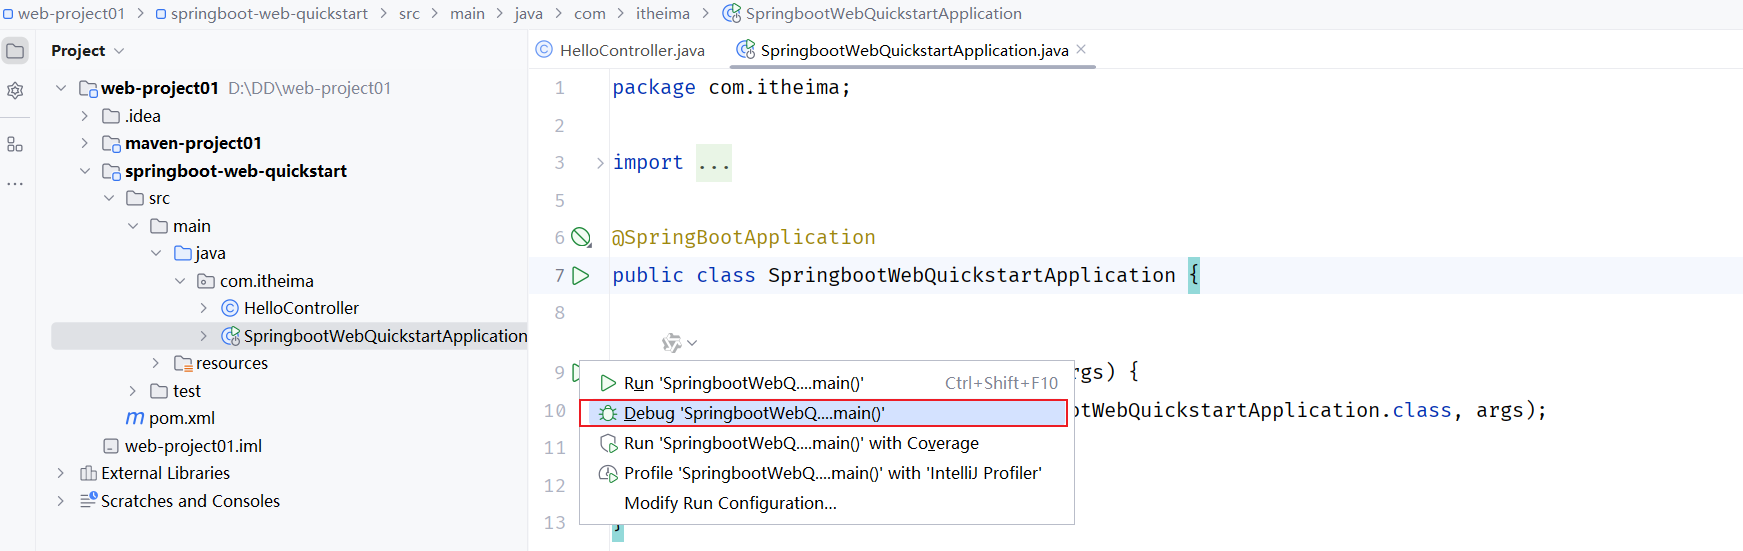

**补充：启动类的最小结构。**脚手架生成的类名可不同；关键是包位置、`@SpringBootApplication` 和 `SpringApplication.run(...)`。

```java
package com.itheima;

import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;

@SpringBootApplication
public class WebApplication {
    public static void main(String[] args) {
        SpringApplication.run(WebApplication.class, args);
    }
}
```

启动后终端进程会持续运行，这时再访问浏览器。若提示 8080 端口被占用，可以在 `src/main/resources/application.properties` 中配置 `server.port=8081`，并把浏览器地址相应改成 8081；不要同时启动多个占用同一端口的练习项目。

打开浏览器，输入 <code>http://localhost:8080/hello?name=itheima</code>

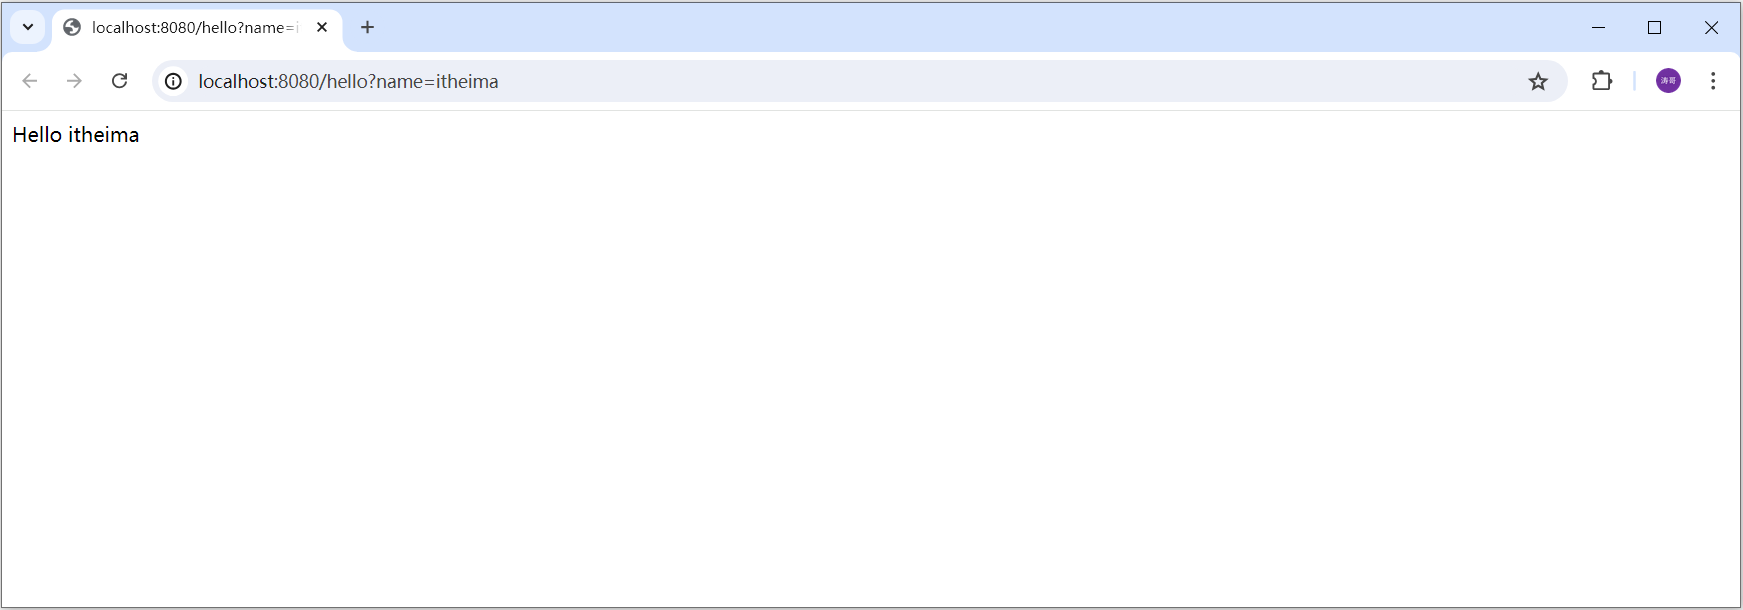


#### 1.2.3 常见问题

大伙儿在下来联系的时候，联网基于spring的脚手架创建SpringBoot项目，偶尔可能会因为网内网络的原因，链接不上SpringBoot的脚手架网站，此时会出现如下现象：

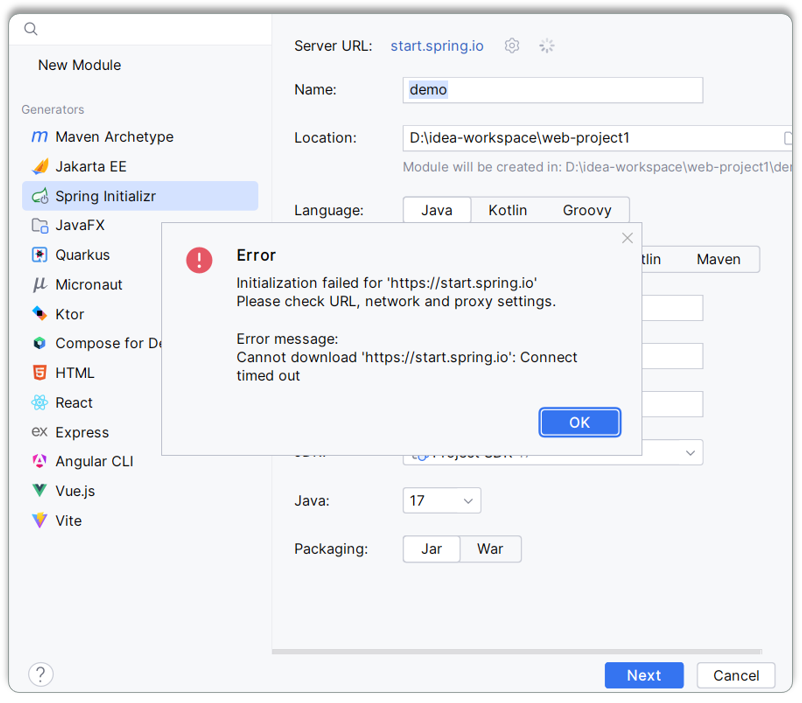

此时可以使用阿里云提供的脚手架，网址为：https://start.aliyun.com

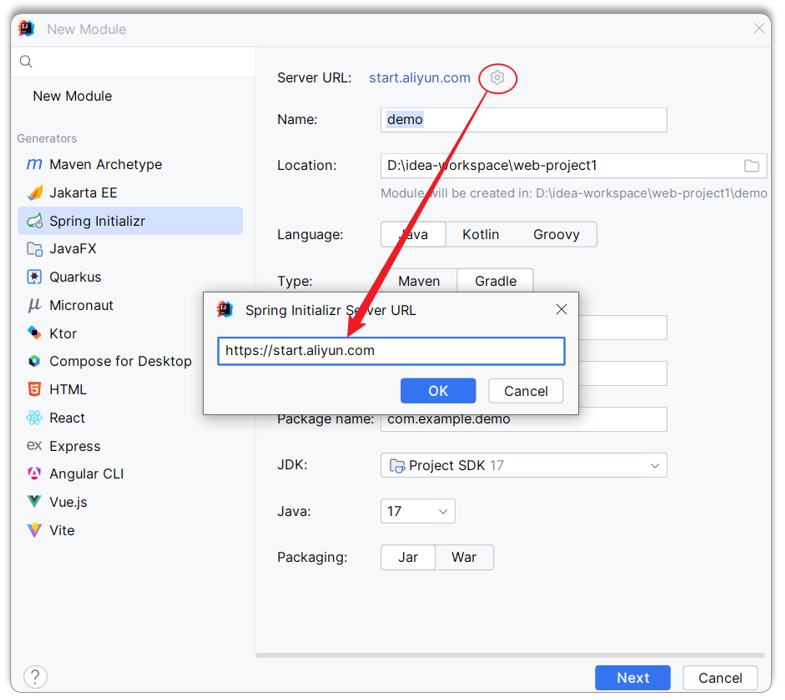

> **补充：**也可在浏览器打开 [Spring Initializr](https://start.spring.io/)，生成 ZIP 后解压，再用 IDEA 打开 `pom.xml`。IDEA 中没有对应向导时仍可这样创建项目。脚手架服务负责生成项目；之后下载 Maven 依赖是另一个网络步骤，前者成功不等于后者一定成功。若只想按本章跟练，第 4.6 节的 POM 和启动类可直接使用。

然后按照项目创建的向导，一步一步的创建项目即可。


### 1.3 入门解析

那在上面呢，我们已经完成了SpringBootWeb的入门程序，并且测试通过。 在入门程序中，我们发现，我们只需要一个main方法就可以将web应用启动起来了，然后就可以打开浏览器访问了。

那接下来我们需要明确两个问题：

<strong>1). </strong><strong>为什么一个main方法就可以将Web应用启动了？</strong>

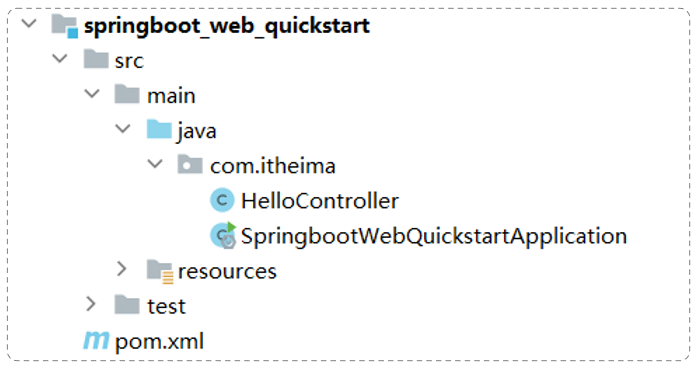

因为我们在创建springboot项目的时候，选择了web开发的<strong>起步依赖</strong> <code>spring-boot-starter-web</code>。而<code>spring-boot-starter-web</code>依赖，又依赖了<code>spring-boot-starter-tomcat</code>，由于maven的依赖传递特性，那么在我们创建的springboot项目中也就已经有了tomcat的依赖，这个其实就是springboot中内嵌的tomcat。 

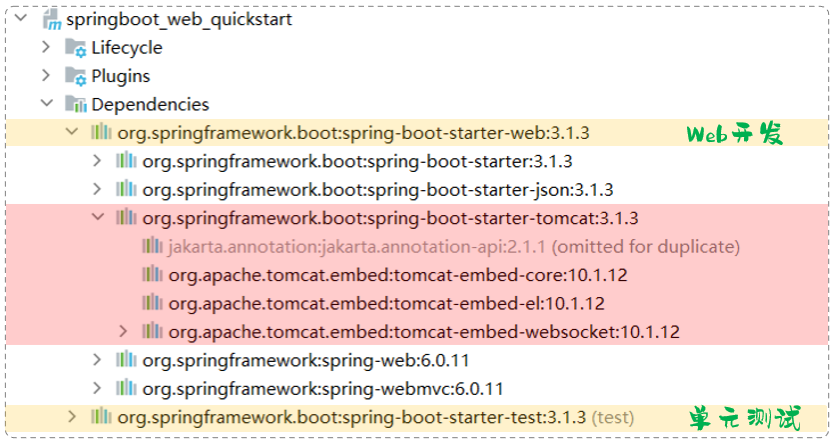

而我们运行引导类中的main方法，其实启动的就是springboot中内嵌的Tomcat服务器。 而我们所开发的项目，也会自动的部署在该tomcat服务器中，并占用8080端口号 。 

> **补充：**`SpringApplication.run` 还会创建 Spring 容器、加载配置、注册组件并完成自动配置；在本章 Servlet Web 项目中，这个过程同时启动内嵌 Tomcat。`main` 方法本身不会自动成为 Web 服务，前提是依赖和应用配置齐全。默认端口 8080 可以修改，也不需要再单独安装一份 Tomcat。

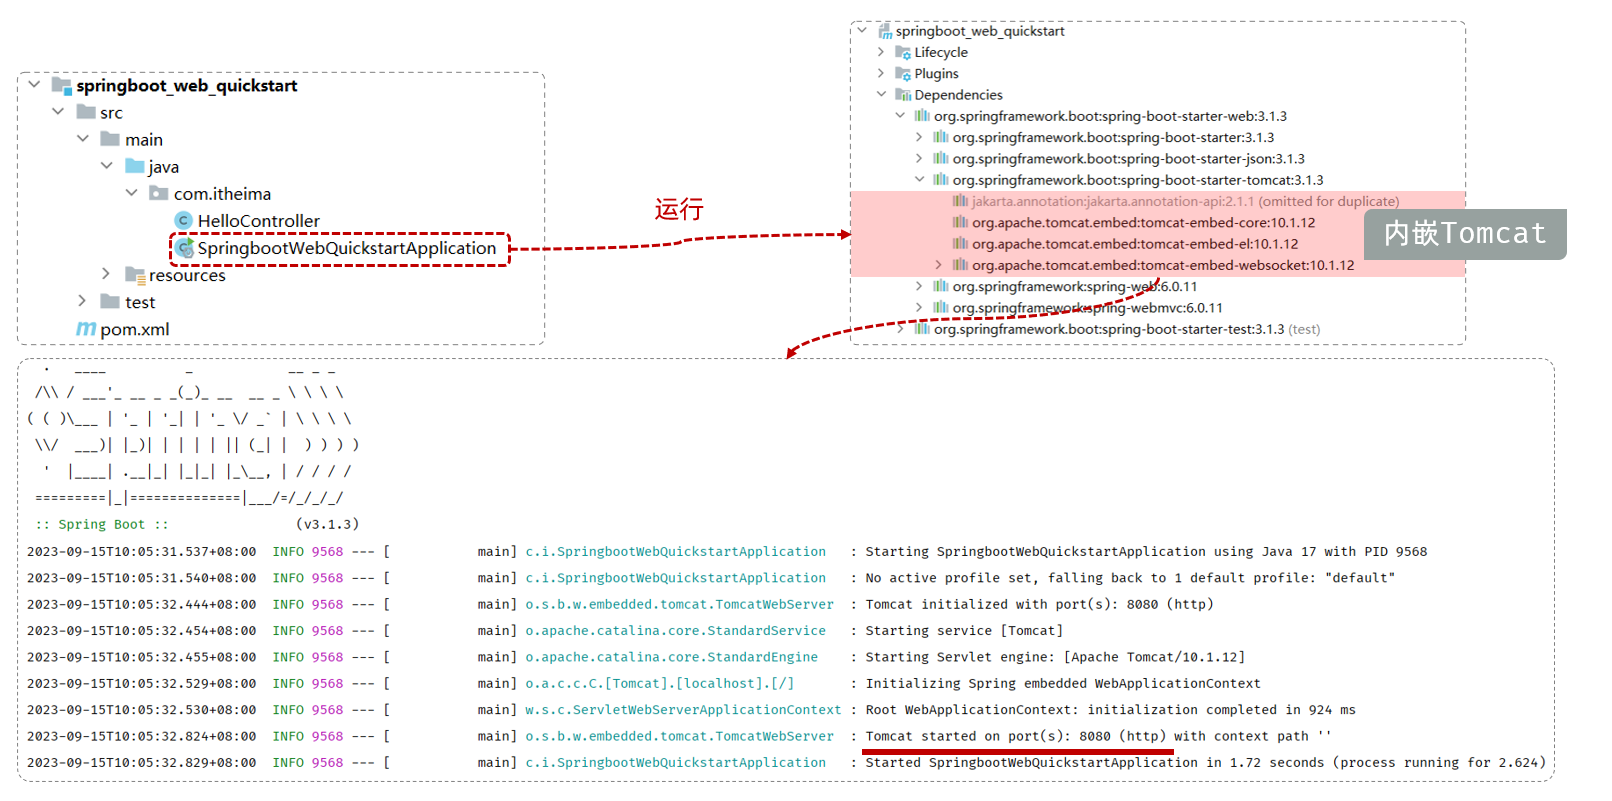

> <strong>起步依赖：</strong>
> 
> - 一种为开发者提供简化配置和集成的机制，使得构建Spring应用程序更加轻松。起步依赖本质上是一组预定义的依赖项集合，它们一起提供了在特定场景下开发Spring应用所需的所有库和配置。
> 
>     - spring-boot-starter-web：包含了web应用开发所需要的常见依赖。
>     - spring-boot-starter-test：包含了单元测试所需要的常见依赖。
> - 官方提供的starter：<a href="https://docs.spring.io/spring-boot/docs/3.1.3/reference/htmlsingle/">https://docs.spring.io/spring-boot/docs/3.1.3/reference/htmlsingle/&#35;using.build-systems.starters</a>

**补充：Spring、Spring MVC、Spring Boot、Tomcat 各管什么？**

| 名称 | 本章中的职责 | 在代码或运行时哪里能看到 |
| --- | --- | --- |
| Spring Framework | 提供 IOC 容器、依赖注入等基础能力 | 管理 `UserServiceImpl`、`UserDaoImpl`，把依赖交给调用方 |
| Spring MVC | Spring 中处理 Web 请求的框架 | 根据 `@RequestMapping` 找到方法、绑定参数、把返回值写入响应 |
| Spring Boot | 简化 Spring 应用的依赖配置、自动配置和启动 | 起步依赖、`@SpringBootApplication`、`SpringApplication.run` |
| Tomcat | Web 服务器与 Servlet 容器，接收 HTTP 连接并执行 Servlet | 本章默认监听 8080 端口，为 Spring MVC 的 `DispatcherServlet` 提供运行环境 |

`DispatcherServlet` 是 Spring MVC 统一接收并分派请求的 Servlet。Servlet 可以理解为 Java Web 中处理请求、生成响应的一套接口约定。四者在这个项目里协作：

```text
Spring Boot 启动并配置 Spring 容器和内嵌 Tomcat

浏览器 HTTP 请求
    → Tomcat
    → Spring MVC 的 DispatcherServlet
    → Controller → Service → Dao → user.txt
    ← HTTP 响应 ← 返回值转换 ← 处理结果逐层返回
```

起步依赖解决“把哪些库加进来”，自动配置解决“根据依赖和配置组装哪些组件”，组件扫描解决“找到自己写的哪些组件类”。只引入一个 starter，并不等于所有业务类都会自动成为 Bean。


## 2 HTTP协议


### 2.1 HTTP概述


#### 2.1.1 介绍

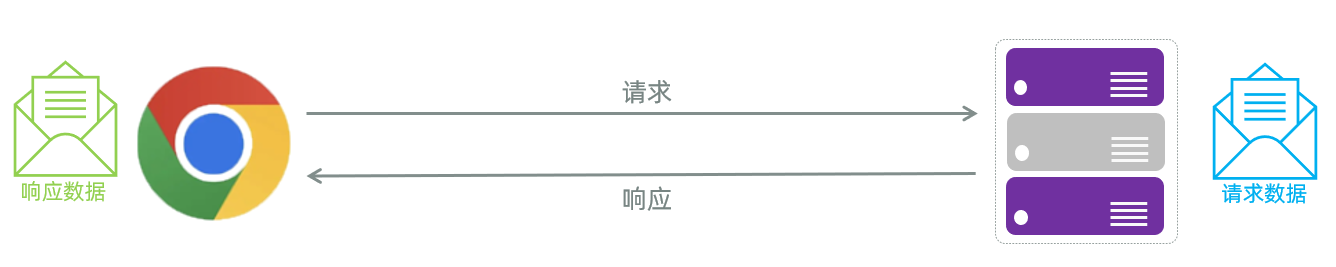

<strong>HTTP</strong>：Hyper Text Transfer Protocol(超文本传输协议)，规定了浏览器与服务器之间数据传输的规则。

- http是互联网上应用最为广泛的一种网络协议 
- http协议要求：浏览器在向服务器发送请求数据时，或是服务器在向浏览器发送响应数据时，都必须按照固定的格式进行数据传输

如果想知道http协议的数据传输格式有哪些，可以打开浏览器，点击<code>F12</code>打开开发者工具，点击<code>Network(网络)</code>来查看

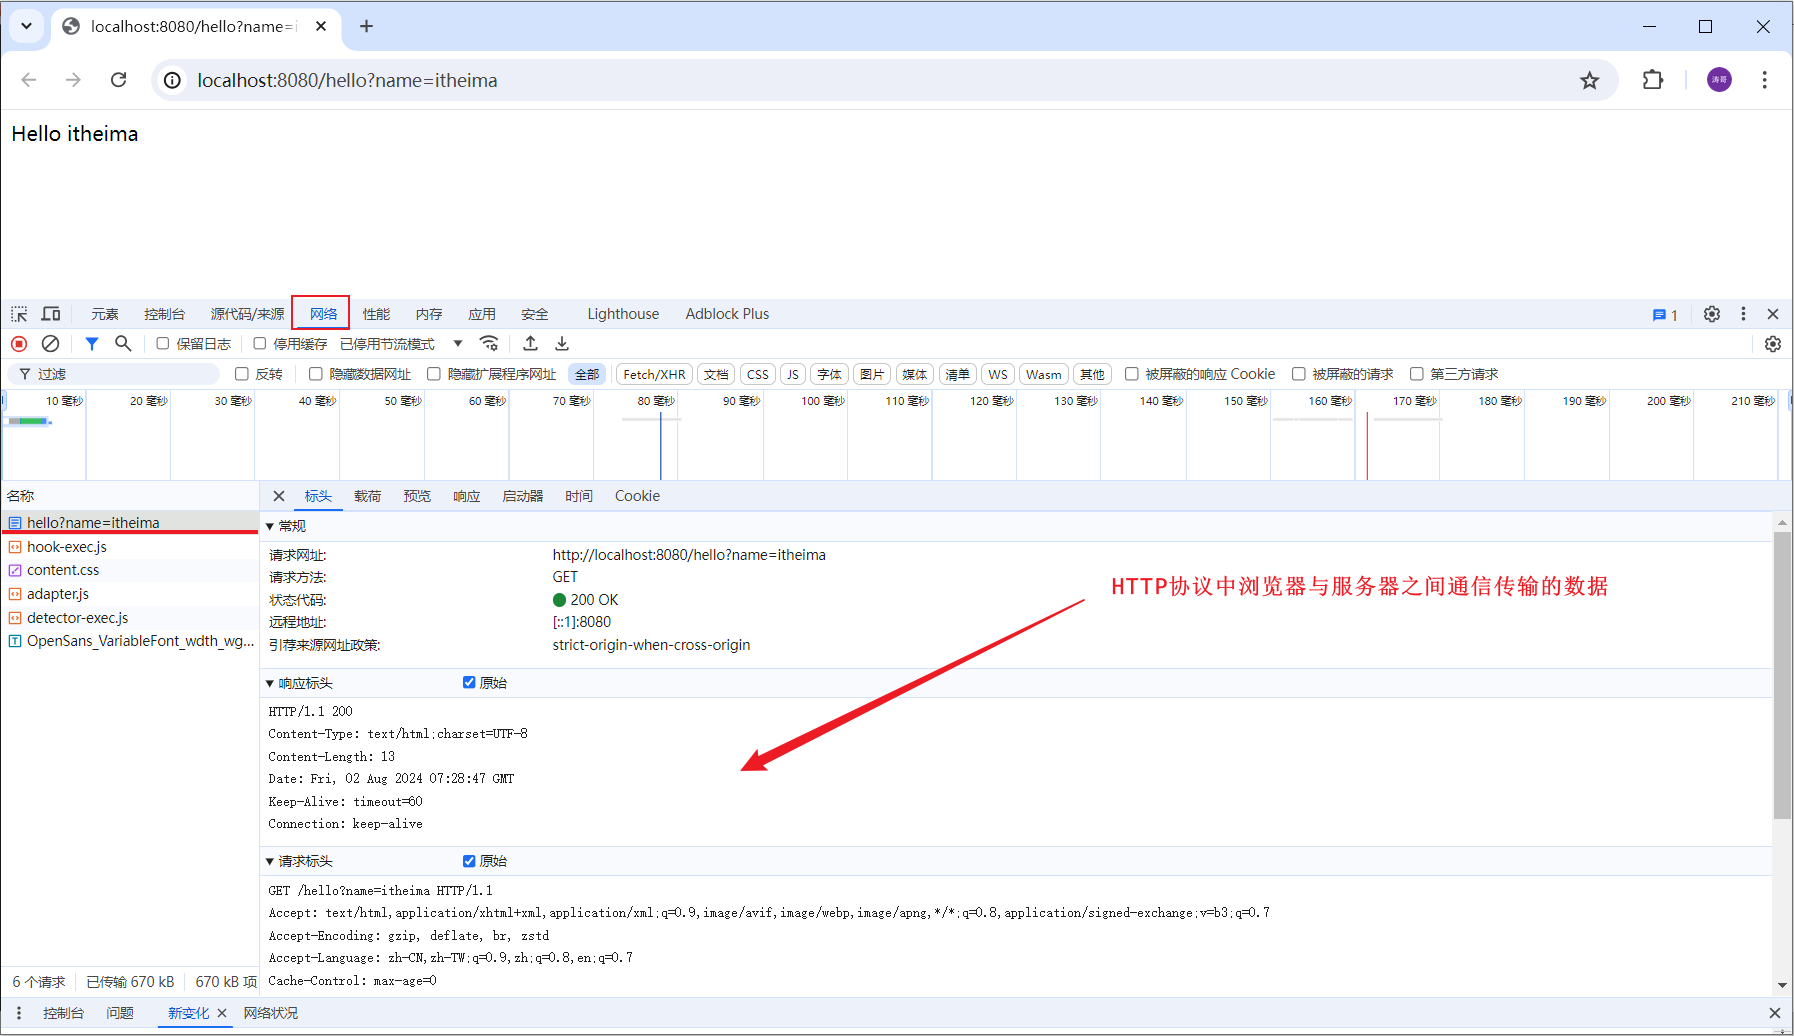

浏览器向服务器进行请求时，服务器按照固定的格式进行解析：

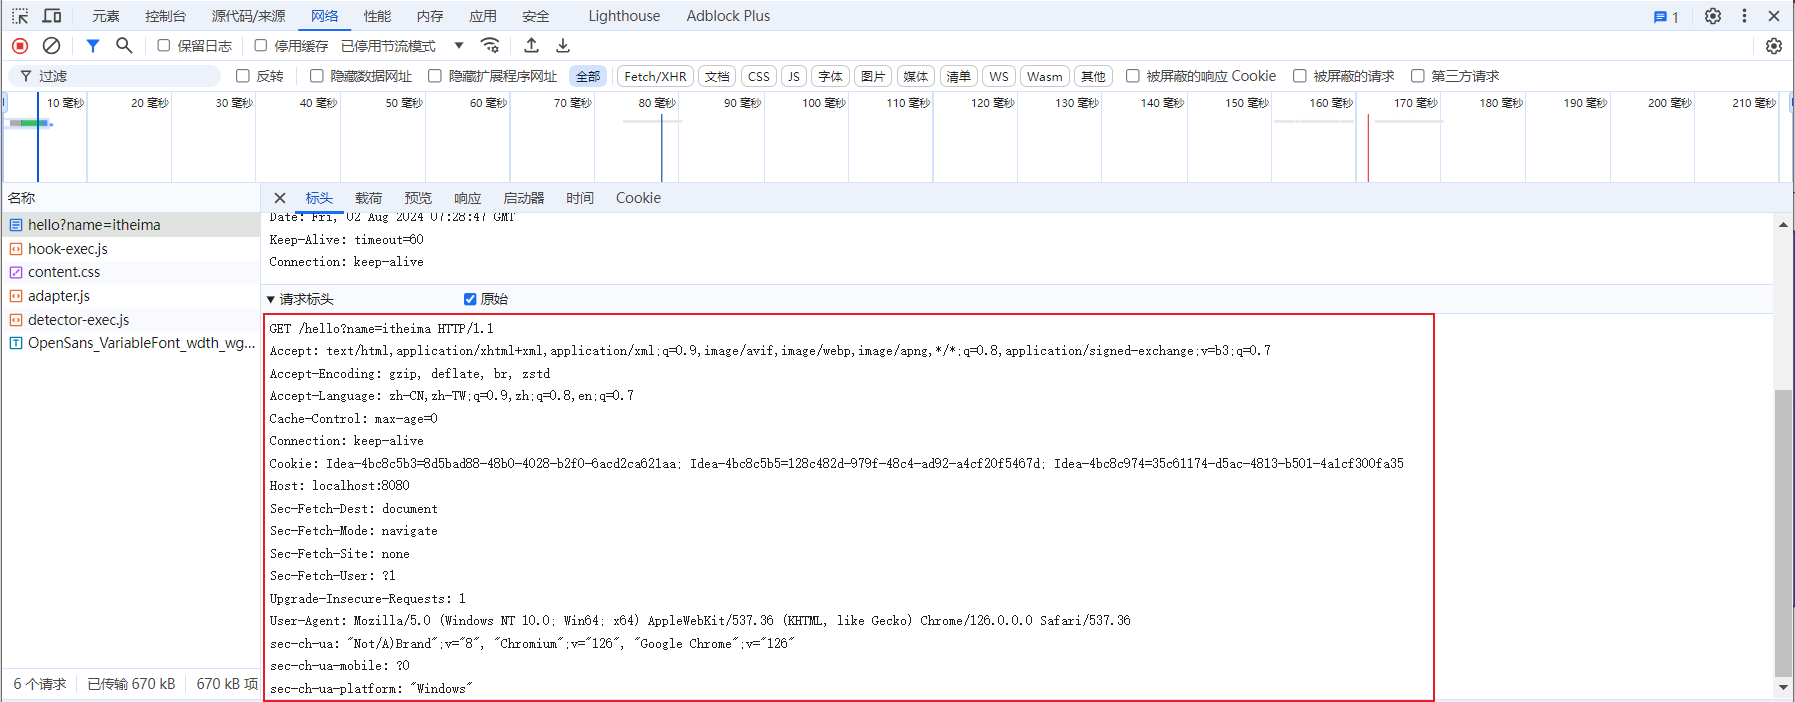

服务器向浏览器进行响应时，浏览器按照固定的格式进行解析：

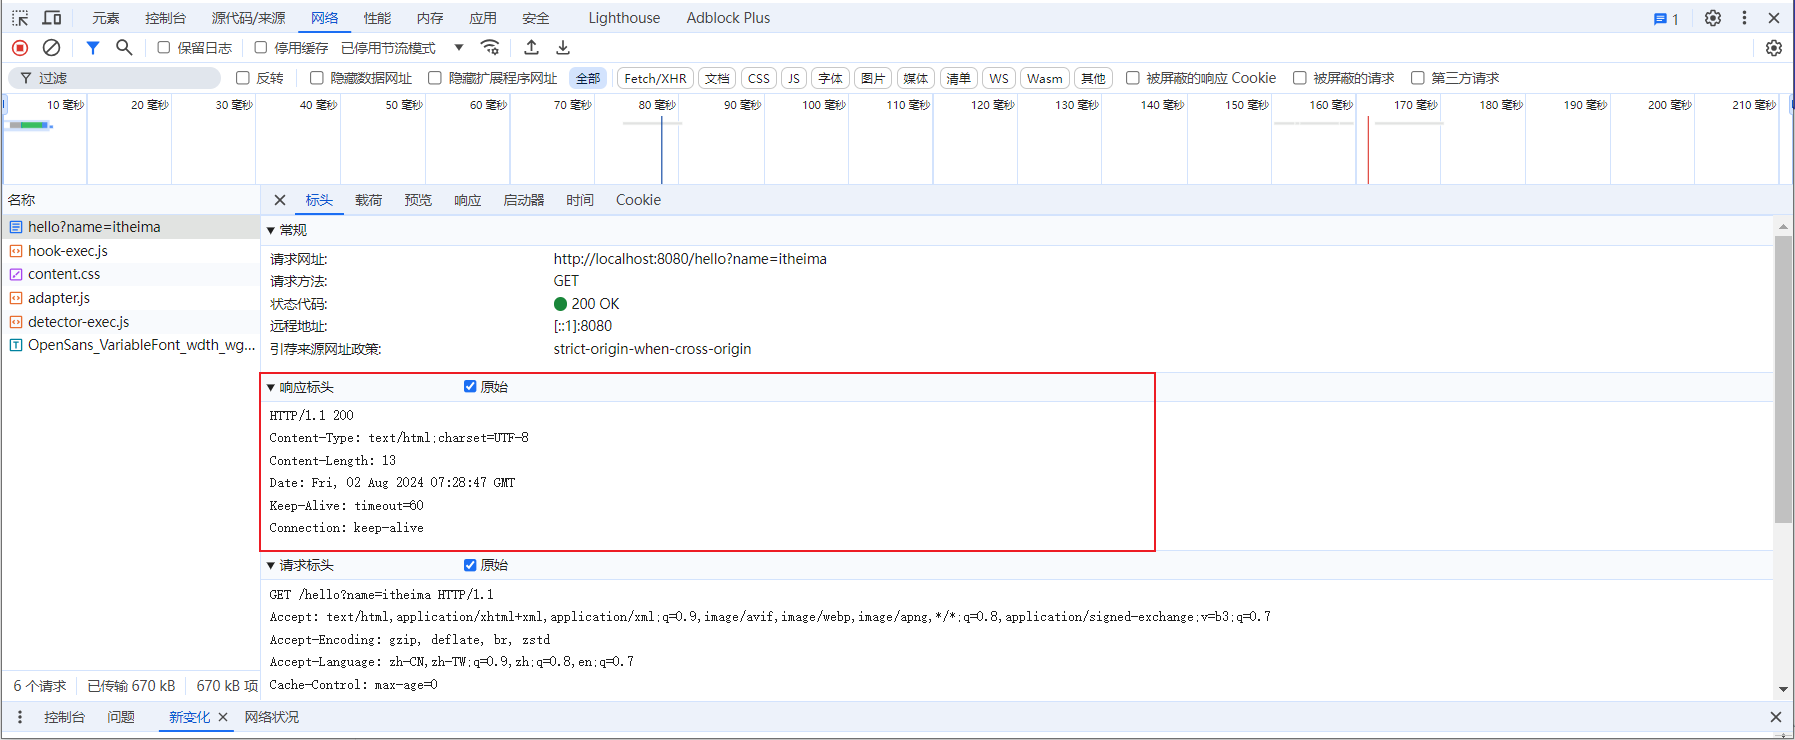

而我们学习HTTP协议，就是来学习请求和响应数据的具体格式内容。


#### 2.1.2 特点

我们刚才初步认识了HTTP协议，那么我们在看看HTTP协议有哪些特点：

- <strong>基于TCP协议:</strong> 面向连接，安全

> TCP是一种面向连接的(建立连接之前是需要经过三次握手)、可靠的、基于字节流的传输层通信协议，在数据传输方面更安全
> 
> > **勘误：**TCP 提供可靠、有序的字节流传输，**可靠不等于加密安全**。普通 HTTP 不会因为使用 TCP 就自动加密；HTTPS 通过 TLS 提供传输保护。本章按 HTTP/1.1 的文本格式讲解；HTTP/1.1、HTTP/2 通常基于 TCP，HTTP/3 使用基于 UDP 的 QUIC，不能把“HTTP 永远基于 TCP”作为通用定义。

- <strong>基于请求-响应模型:</strong>   一次请求对应一次响应（先请求后响应）

> 请求和响应是一一对应关系，没有请求，就没有响应
> 
> > **补充：**入门时按“一次请求对应一个最终响应”理解即可。一个请求在最终响应之前还可能收到 `100 Continue` 等 1xx 临时响应。开发者工具展示的是便于阅读的请求/响应信息，HTTP/2、HTTP/3 在线路上的格式并不是这里的文本请求行。

- <strong>HTTP协议是</strong><strong>无状态协议</strong><strong>:</strong>  对于数据没有记忆能力。每次请求-响应都是独立的

> 无状态指的是客户端发送HTTP请求给服务端之后，服务端根据请求响应数据，响应完后，不会记录任何信息。
> 
> - 缺点:  多次请求间不能共享数据
> - 优点:  速度快
> 
> > **勘误：**“无状态”指 HTTP 协议本身不自动维护跨请求的业务会话，并不禁止服务器记录日志、保存数据库数据、维护 Session，也不表示每次请求都要重新建立连接。购物车能够跨请求保留，是应用借助用户标识、Cookie、Session 或其他机制关联状态；这些技术并非 Java 独有。是否更快也不能只靠“无状态”判断。
> 
> - 请求之间无法共享数据会引发的问题：
> 
>     - 如：京东购物。加入购物车和去购物车结算是两次请求
>     - 由于HTTP协议的无状态特性，加入购物车请求响应结束后，并未记录加入购物车是何商品
>     - 发起去购物车结算的请求后，因为无法获取哪些商品加入了购物车，会导致此次请求无法正确展示数据
> 
> - 具体使用的时候，我们发现京东是可以正常展示数据的，原因是Java早已考虑到这个问题，并提出了使用会话技术(Cookie、Session)来解决这个问题。具体如何来做，我们后面课程中会讲到。

刚才提到HTTP协议是规定了请求和响应数据的格式，那具体的格式是什么呢? 接下来，我们就来详细剖析。

HTTP协议又分为：请求协议和响应协议


### 2.2 HTTP请求协议


#### 2.2.1 介绍

- <strong>请求</strong><strong>协议</strong><strong>：</strong>浏览器将数据以请求格式发送到服务器。包括：<strong>请求行、</strong><strong>请求头 、请求体</strong>

- <strong>GET方式的请求协议：</strong>

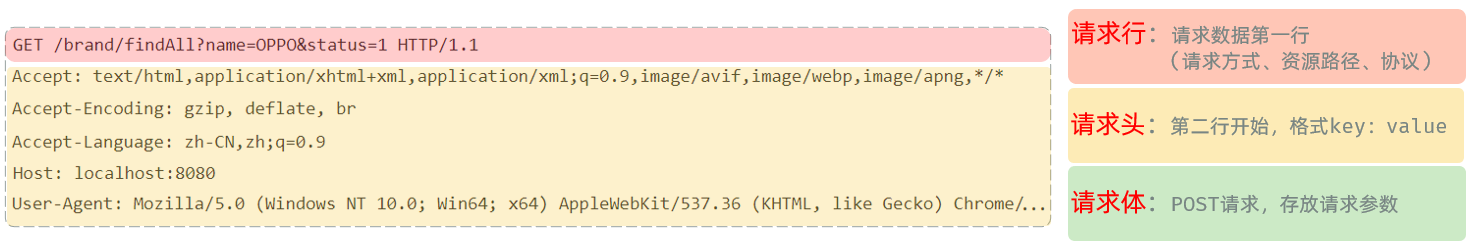

**补充：把图中的 GET 结构写成文本。**这是一个简化的 HTTP/1.1 示例，头部结束后有空行。

```http
GET /brand/findAll?name=OPPO&status=1 HTTP/1.1
Host: localhost:8080
Accept: application/json

```

路径为 `/brand/findAll`，查询字符串为 `name=OPPO&status=1`。当参数值本身含有 `&`、`=`、中文等内容时，需要正确编码；使用 Axios 的 `params` 可以减少手工拼接 URL 出错。

- <strong>请求行</strong>(以上图中红色部分) ：HTTP请求中的第一行数据。由：<code>请求方式</code>、<code>资源路径</code>、<code>协议/版本</code>组成（之间使用空格分隔）

    - 请求方式：GET  
    - 资源路径：/brand/findAll?name=OPPO&amp;status=1

        - 请求路径：/brand/findAll
        - 请求参数：name=OPPO&amp;status=1

            - 请求参数是以key=value形式出现
            - 多个请求参数之间使用<code>&amp;</code>连接
        - 请求路径和请求参数之间使用<code>?</code>连接                          
    - 协议/版本：HTTP/1.1  
- <strong>请求头</strong>(以上图中黄色部分) ：第二行开始，上图黄色部分内容就是请求头。格式为key: value形式 

    - http是个无状态的协议，所以在请求头设置浏览器的一些自身信息和想要响应的形式。这样服务器在收到信息后，就可以知道是谁，想干什么了

    > **补充：**请求头用于传递协议元信息，并不能仅凭 `User-Agent`、`Host` 等字段可信地确认用户身份。`User-Agent` 可描述客户端软件，也可能被修改；身份认证需要另外的机制。
    - 常见的HTTP请求头有:

        | 请求头 | 含义 |
        | --- | --- |
        | Host | 表示请求的主机名 |
        | User-Agent | 浏览器版本。 例如：Chrome浏览器的标识类似Mozilla/5.0 ...Chrome/79 ，IE浏览器的标识类似Mozilla/5.0 (Windows NT ...)like Gecko |
        | Accept | 表示浏览器能接收的资源类型，如text/&#42;，image/&#42;或者&#42;/&#42;表示所有； |
        | Accept-Language | 表示浏览器偏好的语言，服务器可以据此返回不同语言的网页； |
        | Accept-Encoding | 表示浏览器可以支持的压缩类型，例如gzip, deflate等。 |
        | Content-Type | 请求主体的数据类型 |
        | Content-Length | 数据主体的大小（单位：字节） |

> 举例说明：服务端可以根据请求头中的内容来获取客户端的相关信息，有了这些信息服务端就可以处理不同的业务需求。
> 
> 比如:
> 
> - 不同浏览器解析HTML和CSS标签的结果会有不一致，所以就会导致相同的代码在不同的浏览器会出现不同的效果
> - 服务端根据客户端请求头中的数据获取到客户端的浏览器类型，就可以根据不同的浏览器设置不同的代码来达到一致的效果（这就是我们常说的浏览器兼容问题）

- 请求体 ：存储请求参数

    - GET请求的请求参数在请求行中，故不需要设置请求体

<strong>POST方式的请求协议：</strong>

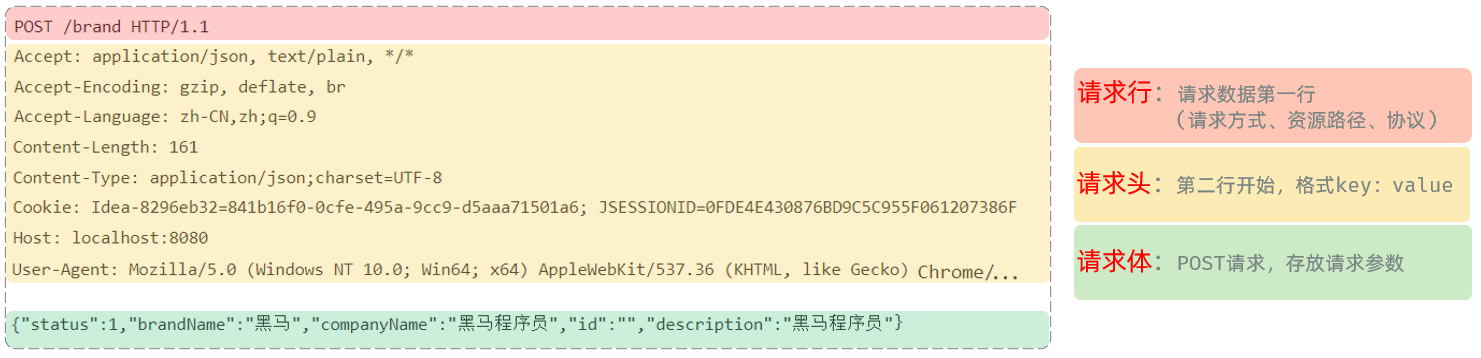

- <strong>请求行</strong>(以上图中红色部分)：包含请求方式、资源路径、协议/版本

    - 请求方式：POST
    - 资源路径：/brand
    - 协议/版本：HTTP/1.1
- <strong>请求头</strong>(以上图中黄色部分)   
- <strong>请求体</strong>(以上图中绿色部分) ：存储请求参数 

    - 请求体和请求头之间是有一个空行隔开（作用：用于标记请求头结束）

GET请求和POST请求的区别：

| <strong>区别方式</strong> | <strong>GET请求</strong> | <strong>POST请求</strong> |
| --- | --- | --- |
| 请求参数 | 请求参数在请求行中。&lt;br/&gt;例：/brand/findAll?name=OPPO&amp;status=1 | 请求参数在请求体中 |
| 请求参数长度 | 请求参数长度有限制(浏览器不同限制也不同) | 请求参数长度没有限制 |
| 安全性 | 安全性低。原因：请求参数暴露在浏览器地址栏中。 | 安全性相对高 |

> **勘误：**以上表格保留原讲义说法，实际应这样理解：
>
> - GET 通常用于获取资源，查询参数常放在 URL；POST 常用于提交内容，请求体可以是表单、JSON、文件等，URL 中也可以同时带查询参数。
> - HTTP 规范没有给出所有浏览器、网关和服务器统一的 URL 长度上限；实际组件会限制 URL、请求头或请求体。POST 请求体也有大小限制，不能理解为“无限长”。
> - 参数放在请求体里不会自动加密。POST 相比 URL 查询参数较少直接暴露在地址栏，但保密性仍依赖 HTTPS 等措施。GET 的“安全方法”语义指请求不应主动改变服务器业务状态，与传输是否保密不是一回事。

**补充：可与下一节 `/request` 接口一起验证的 POST 报文。**

```http
POST /request?source=web HTTP/1.1
Host: localhost:8080
Content-Type: application/x-www-form-urlencoded
Content-Length: 15

name=Tom&age=18
```

`source=web` 仍在 URL 查询字符串中，`name` 和 `age` 在表单请求体中。`application/x-www-form-urlencoded` 表示按 `key=value&key=value` 编码的表单；它不同于 `application/json`。这里正文 `name=Tom&age=18` 恰好是 15 个 ASCII 字节，空行不计入正文长度。实际发送请求时让浏览器或 HTTP 客户端计算 `Content-Length`。

这也解释了为什么下一节的 `getParameter("name")` 能读取普通表单，却不能直接读取 JSON 对象里的同名属性：**参数放在哪里、用什么格式发送，会影响后端的读取方式。**原 `/request` 方法没有限定 HTTP 方法，因此可以用 GET 查询参数，也可以用上述 POST 表单跟练。


#### 2.2.2 获取请求数据

Web服务器（Tomcat）对HTTP协议的请求数据进行解析，并进行了封装(HttpServletRequest)，并在调用Controller方法的时候传递给了该方法。这样，就使得程序员不必直接对协议进行操作，让Web开发更加便捷。

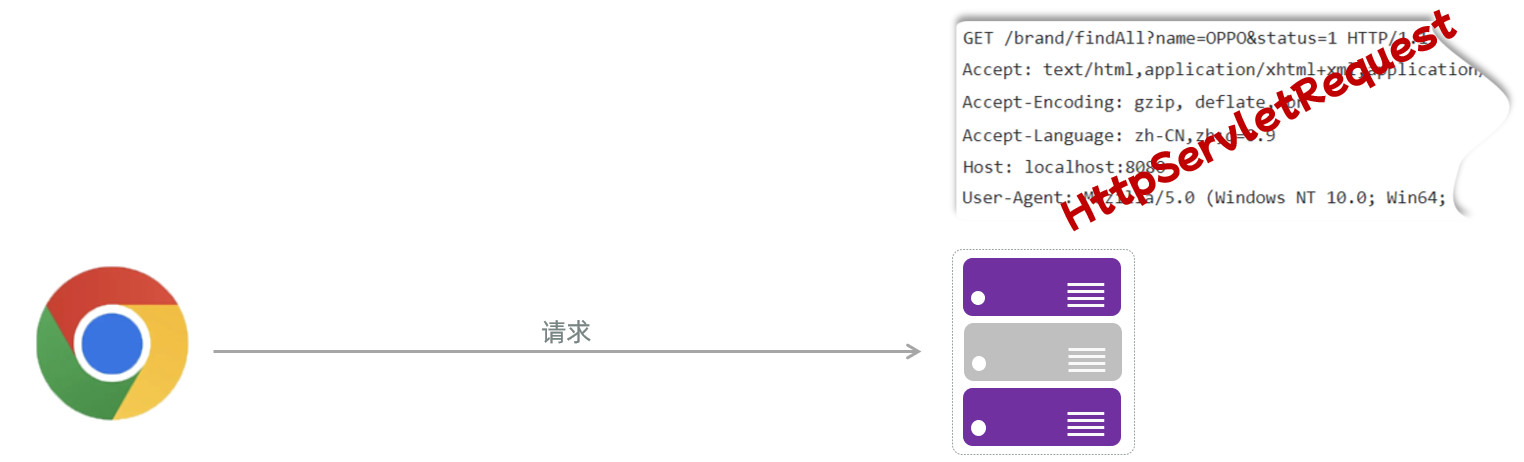

代码演示如下：

````java
@RestController
public class RequestController {

    /**
     * 请求路径 http://localhost:8080/request?name=Tom&age=18
     * @param request
     * @return
     */
    @RequestMapping("/request")
    public String request(HttpServletRequest request){
        //1.获取请求参数 name, age
        String name = request.getParameter("name");
        String age = request.getParameter("age");
        System.out.println("name = " + name + ", age = " + age);
        
        //2.获取请求路径
        String uri = request.getRequestURI();
        String url = request.getRequestURL().toString();
        System.out.println("uri = " + uri);
        System.out.println("url = " + url);
        
        //3.获取请求方式
        String method = request.getMethod();
        System.out.println("method = " + method);
        
        //4.获取请求头
        String header = request.getHeader("User-Agent");
        System.out.println("header = " + header);
        return "request success";
    }

}
````

**补充：这段代码需要补齐的包和导入。**本章使用 Spring Boot 3，Servlet API 的包名前缀是 `jakarta.servlet`。

```java
package com.itheima;

import jakarta.servlet.http.HttpServletRequest;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
```

> **补充：**访问示例时，`getRequestURI()` 得到 `/request`，`getRequestURL()` 得到 `http://localhost:8080/request`，两者都不包含查询字符串；若要单独读取 `name=Tom&age=18`，可用 `getQueryString()`。`getParameter` 的结果是字符串，缺少参数时通常为 `null`；它适用于查询参数、常规表单参数，不会自动把任意 JSON 请求体解析成参数。Tomcat 负责解析 HTTP，Spring MVC 再把请求对象交给控制器方法。

最终输出内容如下所示：

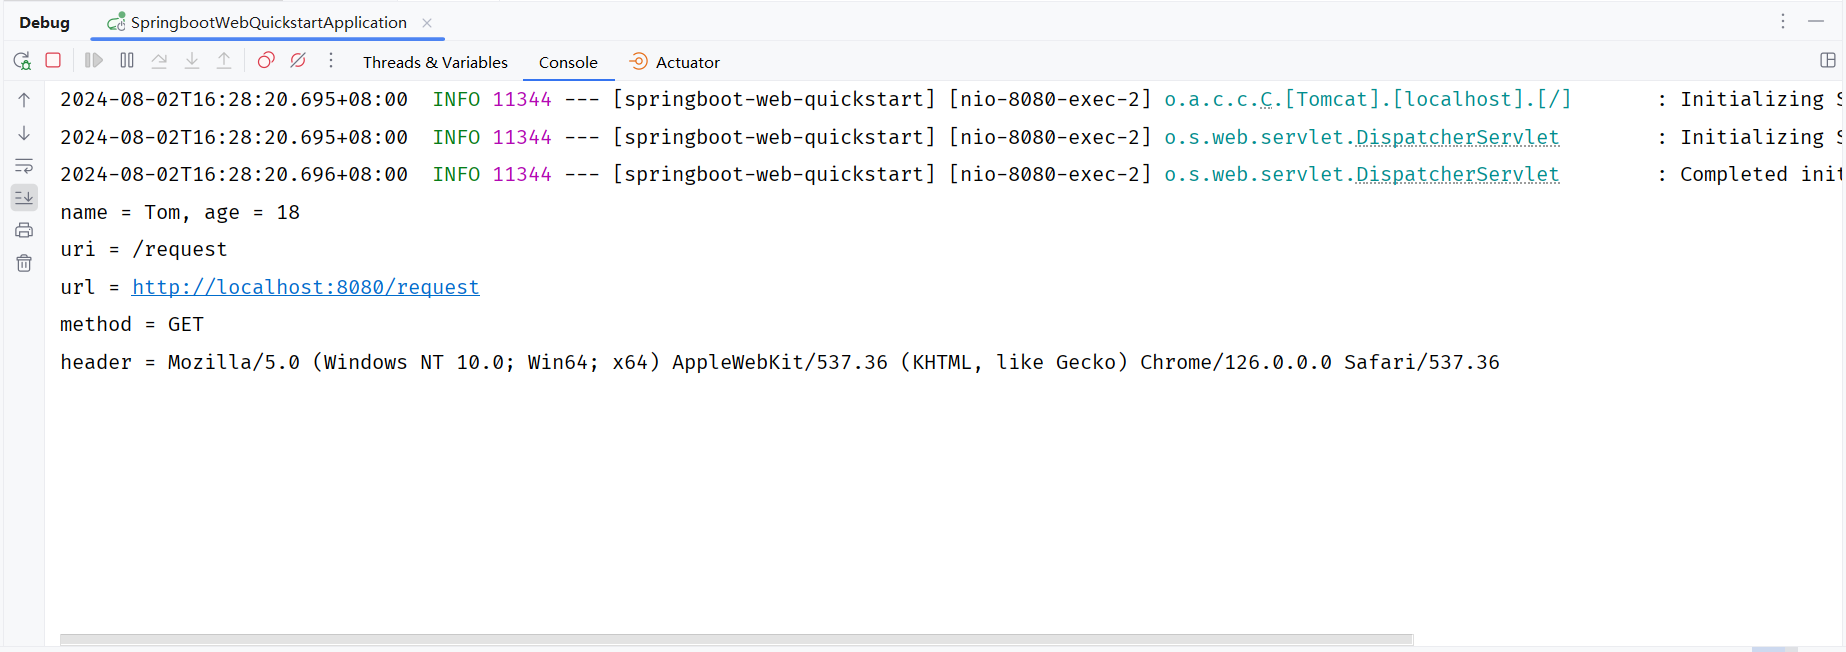


### 2.3 HTTP响应协议


#### 2.3.1 格式介绍

- 响应协议：服务器将数据以响应格式返回给浏览器。包括：<strong>响应行 </strong><strong>、响应头 、响应体</strong>

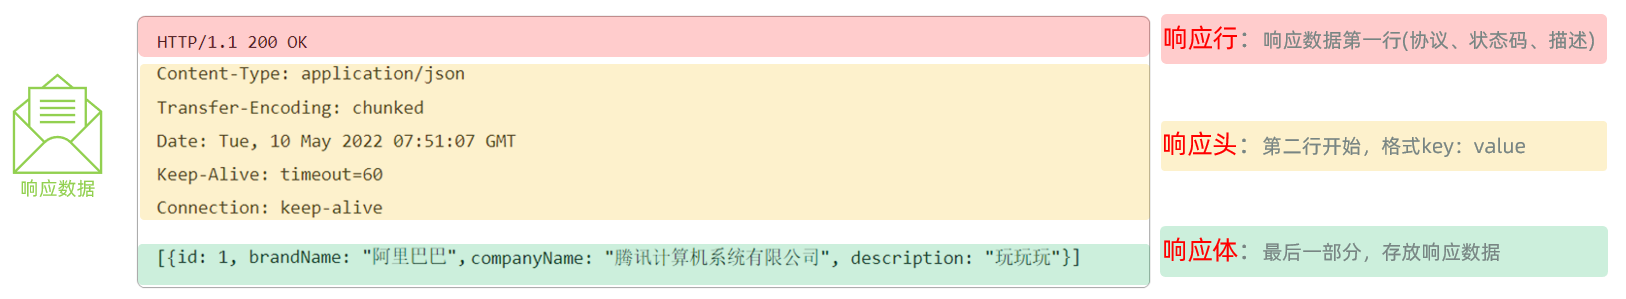

- 响应行(以上图中红色部分)：响应数据的第一行。响应行由<code>协议及版本</code>、<code>响应状态码</code>、<code>状态码描述</code>组成

    - 协议/版本：HTTP/1.1
    - 响应状态码：200
    - 状态码描述：OK
- 响应头(以上图中黄色部分)：响应数据的第二行开始。格式为key：value形式

    - http是个无状态的协议，所以可以在请求头和响应头中设置一些信息和想要执行的动作，这样，对方在收到信息后，就可以知道你是谁，你想干什么
    - 常见的HTTP响应头有:

    ````java
    Content-Type：表示该响应内容的类型，例如text/html，image/jpeg ；

    Content-Length：表示该响应内容的长度（字节数）；

    Content-Encoding：表示该响应压缩算法，例如gzip ；

    Cache-Control：指示客户端应如何缓存，例如max-age=300表示可以最多缓存300秒 ;

    Set-Cookie: 告诉浏览器为当前页面所在的域设置cookie ;
    ````

    > **补充：**上面是响应头说明，虽然原讲义把代码语言标为 Java，但它不是 Java 源代码。`Content-Length` 表示字节数，不是中文字数；`Content-Type` 表示内容类型，`Content-Encoding` 表示压缩等内容编码。`Set-Cookie` 的具体作用还受 Domain、Path 等属性影响。
- 响应体(以上图中绿色部分)： 响应数据的最后一部分。存储响应的数据

    - 响应体和响应头之间有一个空行隔开（作用：用于标记响应头结束）

**补充：把响应结构写成可对照的文本。**以下是与 `/request` 的返回正文对应的简化 HTTP/1.1 报文，实际服务器可能增加其他头部或使用其他消息分帧方式。

```http
HTTP/1.1 200 OK
Content-Type: text/plain;charset=UTF-8
Content-Length: 15

request success
```

`200` 是处理状态，`Content-Type` 说明正文如何解释，空行之后才是正文。接口返回 JSON 时，例如本章 `/list`，通常会看到 `Content-Type: application/json`。请求头的 `Accept` 表达“希望收到什么类型”，请求或响应头的 `Content-Type` 表达“这一份正文是什么类型”；两者不能互换。


#### 2.3.2 响应状态码

| 状态码分类 | 说明 |
| --- | --- |
| 1xx | 响应中 --- 临时状态码。表示请求已经接受，告诉客户端应该继续请求或者如果已经完成则忽略 |
| 2xx | 成功 --- 表示请求已经被成功接收，处理已完成 |
| 3xx | 重定向 --- 重定向到其它地方，让客户端再发起一个请求以完成整个处理 |
| 4xx | 客户端错误 --- 处理发生错误，责任在客户端，如：客户端的请求一个不存在的资源，客户端未被授权，禁止访问等 |
| 5xx | 服务器端错误 --- 处理发生错误，责任在服务端，如：服务端抛出异常，路由出错，HTTP版本不支持等 |

> **补充：**这是状态码的语义分类，不是对故障责任人的绝对判断；服务器配置错误也可能表现为某个 4xx。3xx 不全都要求浏览器跳到另一个页面，例如 `304 Not Modified` 表示复用已缓存的表示。1xx 是临时响应，后面通常还有最终状态码。

关于响应状态码，我们先主要认识三个状态码，其余的等后期用到了再去掌握：

- <code>200 ok</code>   客户端请求成功
- <code>404 Not Found</code>  请求资源不存在
- <code>500 Internal Server Error</code>  服务端发生不可预期的错误


#### 2.3.3 设置响应数据

Web服务器对HTTP协议的响应数据进行了封装(HttpServletResponse)，并在调用Controller方法的时候传递给了该方法。这样，就使得程序员不必直接对协议进行操作，让Web开发更加便捷。

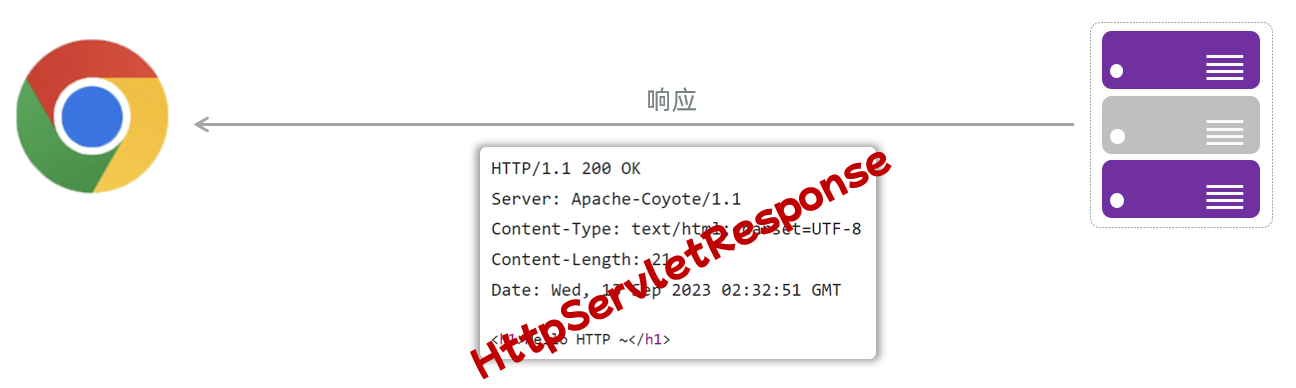

代码演示：

````java
package com.itheima;

import jakarta.servlet.http.HttpServletResponse;
import org.springframework.http.ResponseEntity;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;

import java.io.IOException;

@RestController
public class ResponseController {

    @RequestMapping("/response")
    public void response(HttpServletResponse response) throws IOException {
        //1.设置响应状态码
        response.setStatus(401);
        //2.设置响应头
        response.setHeader("name","itcast");
        //3.设置响应体
        response.setContentType("text/html;charset=utf-8");
        response.setCharacterEncoding("utf-8");
        response.getWriter().write("<h1>hello response</h1>");
    }

    @RequestMapping("/response2")
    public ResponseEntity<String> response2(HttpServletResponse response) throws IOException {
        return ResponseEntity
                .status(401)
                .header("name","itcast")
                .body("<h1>hello response</h1>");
    }

}
````

> **补充：**这里主动设置 401，是演示如何控制响应状态，并没有实现登录认证。浏览器可能同时显示正文和 401 状态，不能只看页面是否有文字来判断请求成功；应在 Network 中检查状态码、响应头 `name: itcast` 和正文。
>
> 第一种写法设置状态、头和正文后返回 `void`，第二种交给 `ResponseEntity` 表达响应。第二个方法不需要使用传入的 response，也没有实际用到 `throws IOException`。如果明确要按 HTML 响应，可在链式调用中添加 `.contentType(MediaType.TEXT_HTML)`，并导入 `org.springframework.http.MediaType`；不要把内容协商碰巧选出的类型当成固定结果。

浏览器访问测试：

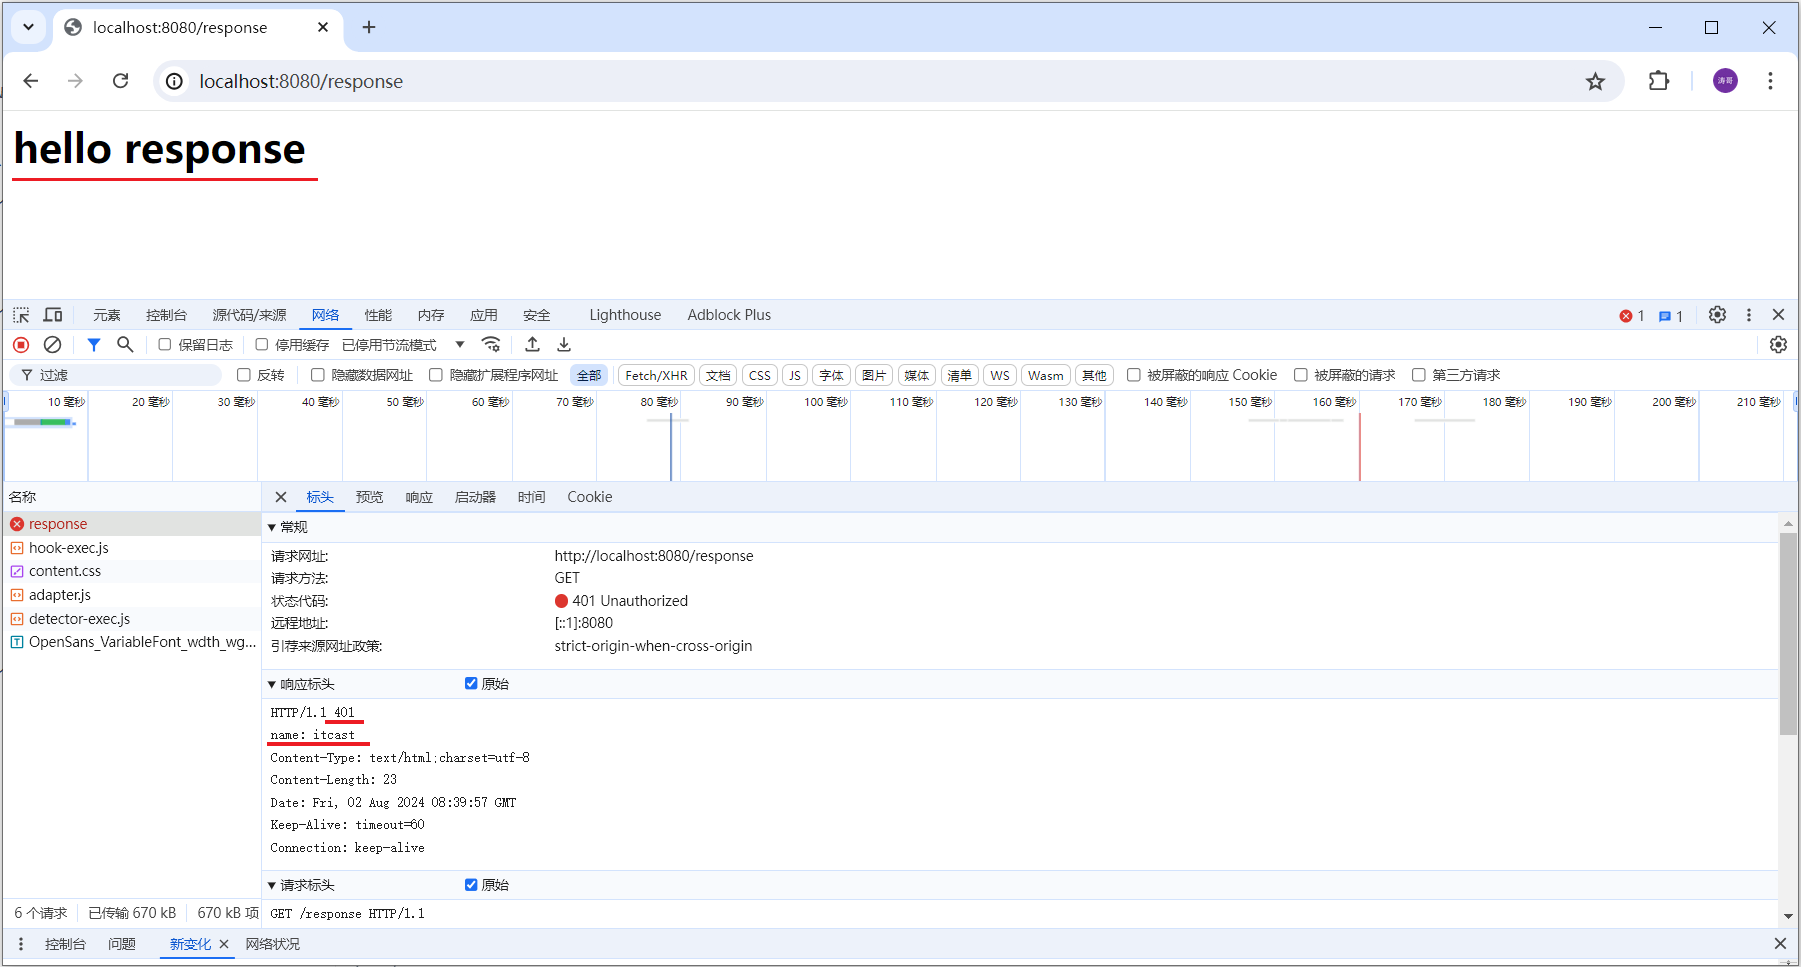

> 响应状态码 和 响应头如果没有特殊要求的话，通常不手动设定。服务器会根据请求处理的逻辑，自动设置响应状态码和响应头。
> 
> > **补充：**框架通常会为正常返回设置成功状态，为部分错误生成相应响应，但不会自动理解所有业务错误。后续编写参数校验、权限和异常处理时，仍要由应用决定合适的状态码。真实认证场景中，401 表示需要有效身份认证，协议要求相应的 `WWW-Authenticate` 认证挑战；403 表示服务器拒绝执行请求。


## 3 SpringBootWeb案例


### 3.1 需求说明

需求：基于SpringBoot开发web程序，完成用户列表的渲染展示

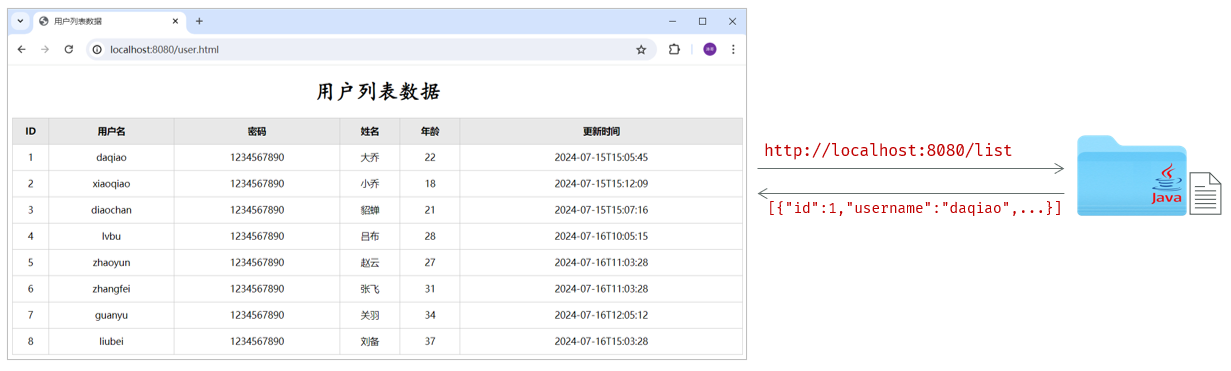

当在浏览器地址栏，访问前端静态页面（http://localhost:8080/usre.html）后，在前端页面上，会发送ajax请求，请求服务端（http://localhost:8080/list），服务端程序加载 user.txt 文件中的数据，读取出来后最终给前端页面响应json格式的数据，前端页面再将数据渲染展示在表格中。

> **勘误：**这里的 `usre.html` 是拼写错误，正确地址是 `http://localhost:8080/user.html`。浏览器先请求页面，再由页面请求 `/list`，这是两个 HTTP 请求。


### 3.2 代码实现

<strong>1). 准备工作：再创建一个SpringBoot工程，</strong><strong>并勾选web依赖、lombok依赖</strong><strong>。</strong>

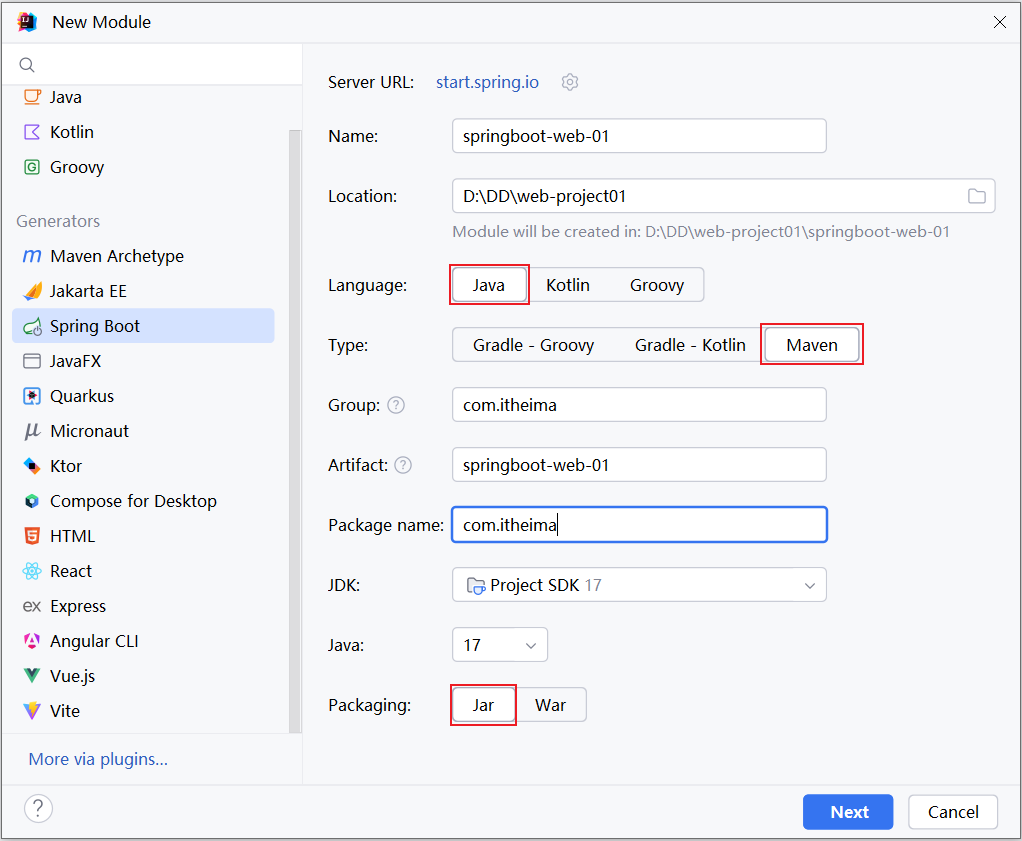

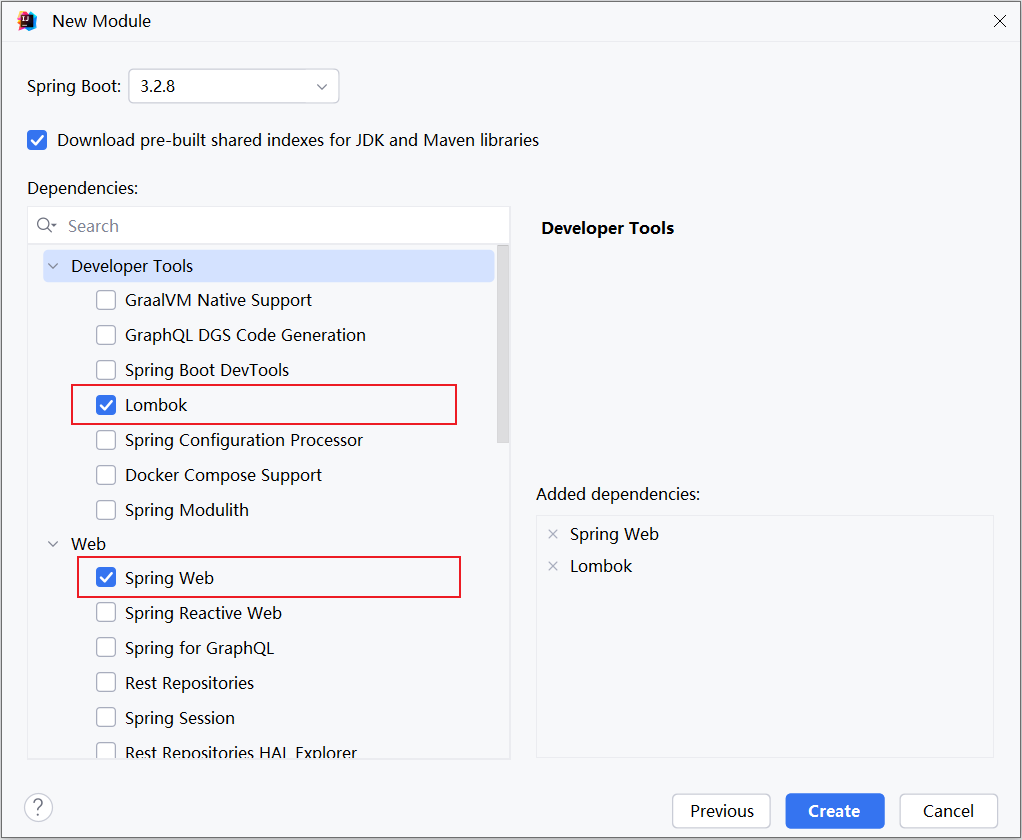

<strong>2). 准备工作：引入资料中准备好的数据文件user.txt，以及static下的前端静态页面</strong>

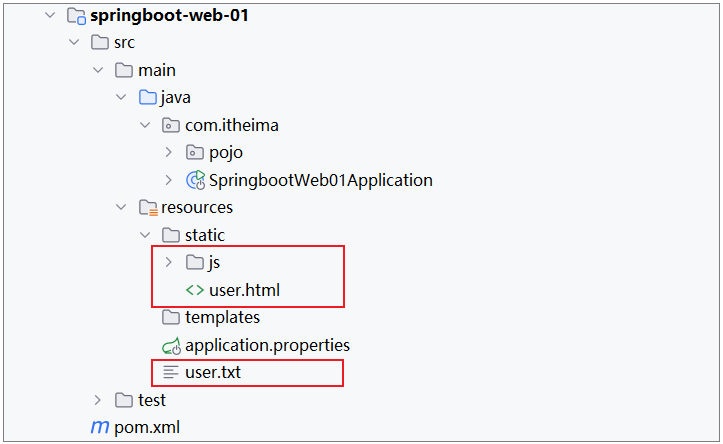

**配图目录转写：**

```text
src/main/resources/
├── user.txt
├── application.properties
└── static/
    ├── user.html
    └── js/                 使用本地脚本时放 Vue、Axios 等文件
```

> **补充：**Spring Boot 默认把 classpath 下的 `static` 等位置作为静态资源目录，因此 `static/user.html` 对应 URL `/user.html`，不带 `/static`。本章 `user.txt` 放在 resources 根下，用类加载器读取；它不是放进 static 让浏览器直接下载。讲义正文未附这两个文件的源码，第 4.6 节会提供截图数据转写和可用的页面补充。

这些文件，在提供的资料中，已经提供了直接导入进来即可。 

<strong>3). 准备工作：定义封装用户信息的实体类。</strong>

在 <code>com.itheima</code> 下再定义一个包 <code>pojo</code>，专门用来存放实体类。 在该包下定义一个实体类User：

````java
package com.itheima.pojo;

import lombok.AllArgsConstructor;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.time.LocalDateTime;

/**
 * 封装用户信息
 */
@Data
@NoArgsConstructor
@AllArgsConstructor
public class User {
    private Integer id;
    private String username;
    private String password;
    private String name;
    private Integer age;
    private LocalDateTime updateTime;
}
````

> **补充：**Lombok 的 `@Data` 生成 getter/setter 等方法，`@NoArgsConstructor` 生成无参构造器，`@AllArgsConstructor` 生成包含全部字段的构造器。如果 IDEA 提示这些方法不存在，先确认 Maven 依赖已经下载，再核对 Lombok 支持及注解处理设置。
>
> **勘误提醒：**截图把 password 放在页面里，是课程演示数据。真实用户系统不应明文保存密码，也不应在用户列表接口返回密码或密码哈希。

<strong>3). 开发服务端程序，接收请求，读取文本数据并响应</strong>

由于在案例中，需要读取文本中的数据，并且还需要将对象转为json格式，所以这里呢，我们在项目中再引入一个非常常用的工具包hutool。 然后调用里面的工具类，就可以非常方便快捷的完成业务操作。

- <code>pom.xml</code>中引入依赖

````xml
<dependency>
    <groupId>cn.hutool</groupId>
    <artifactId>hutool-all</artifactId>
    <version>5.8.27</version>
</dependency>
````

- 在<code>com.itheima</code>包下新建一个子包<code>controller</code>，在其中创建一个<code>UserController</code>

````java
import cn.hutool.core.io.IoUtil;
import cn.hutool.json.JSONConfig;
import cn.hutool.json.JSONUtil;
import com.itheima.pojo.User;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import java.io.InputStream;
import java.nio.charset.StandardCharsets;
import java.time.LocalDateTime;
import java.time.format.DateTimeFormatter;
import java.util.ArrayList;
import java.util.List;
import java.util.stream.Collectors;

@RestController
public class UserController {
    
    @RequestMapping("/list")
    public String list(){
        //1.加载并读取文件
        InputStream in = this.getClass().getClassLoader().getResourceAsStream("user.txt");
        ArrayList<String> lines = IoUtil.readLines(in, StandardCharsets.UTF_8, new ArrayList<>());
        
        //2.解析数据，封装成对象 --> 集合
        List<User> userList = lines.stream().map(line -> {
            String[] parts = line.split(",");
            Integer id = Integer.parseInt(parts[0]);
            String username = parts[1];
            String password = parts[2];
            String name = parts[3];
            Integer age = Integer.parseInt(parts[4]);
            LocalDateTime updateTime = LocalDateTime.parse(parts[5], DateTimeFormatter.ofPattern("yyyy-MM-dd HH:mm:ss"));

            return new User(id, username, password, name, age, updateTime);
        }).collect(Collectors.toList());
        
        //3.响应数据
        //return JSONUtil.toJsonStr(userList, JSONConfig.create().setDateFormat("yyyy-MM-dd HH:mm:ss"));
        return userList;
    }
    
}
````

**勘误：原段落的返回类型不一致，直接复制会编译失败。**方法声明是 `String`，末尾却 `return userList;`。按后文 `@ResponseBody` 的学习目标，应改为：

```java
@RequestMapping("/list")
public List<User> list() {
    // 保留原例中“读取文件”和“解析数据”的代码
    return userList;
}
```

这是修改位置示意，不是独立完整方法。完整可运行代码见第 4.6 节；这个类还需要在文件开头写 `package com.itheima.controller;`。

> **补充：**如果坚持返回 String，就应使用原注释里的 `JSONUtil.toJsonStr(...)`，并明确 JSON 媒体类型；本章推荐直接返回 `List<User>`，由 Spring MVC 的消息转换器序列化，避免重复转换。原注释中的 Hutool 日期格式配置，在注释掉手工 JSON 转换后不会继续生效；最终补充使用 `@JsonFormat` 统一显示格式。
>
> 读取 `user.txt` 时要处理资源不存在并关闭输入流；每行按 6 个逗号分隔字段解析。原例适合课程的简单文件，不是支持引号、转义和字段内逗号的完整 CSV 解析器。

<strong>4). </strong><strong>启动服务测试</strong><strong>，访问：</strong>http://localhost:8080/user.html

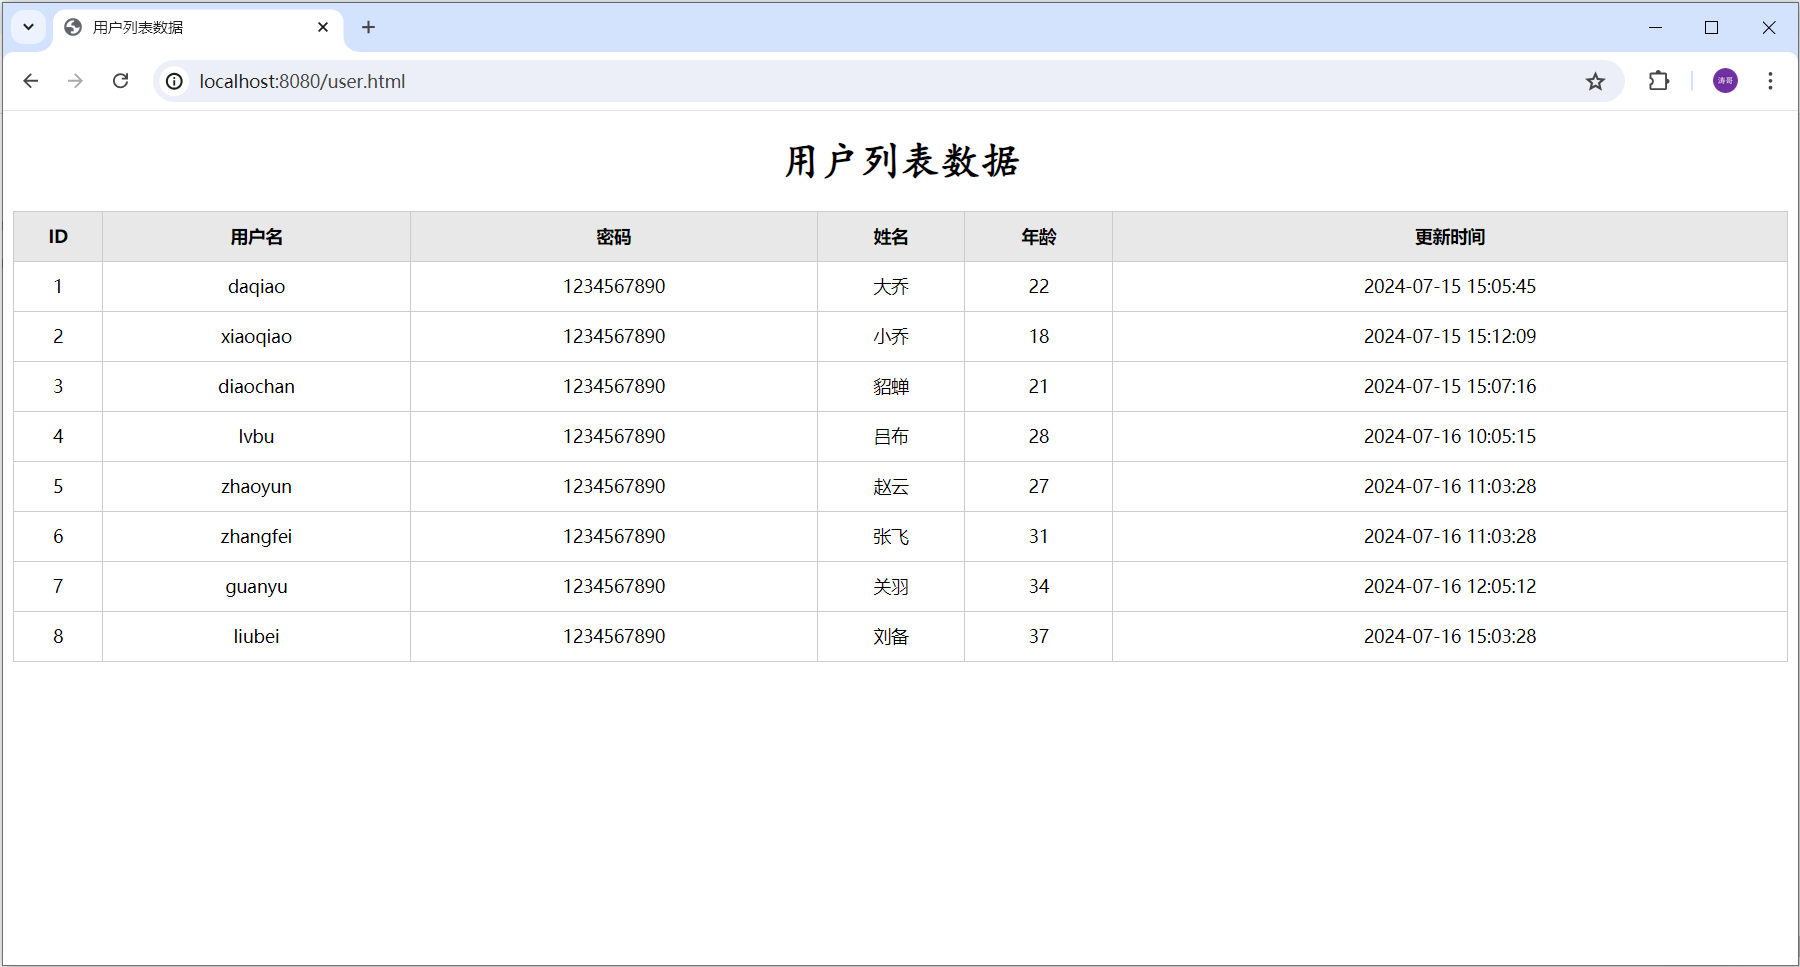


### 3.3 @ResponseBody

前面我们学习过HTTL协议的交互方式：请求响应模式（有请求就有响应）。那么Controller程序呢，除了接收请求外，还可以进行响应。

在我们前面所编写的controller方法中，都已经设置了响应数据。

controller方法中的return的结果，怎么就可以响应给浏览器呢？

答案：使用@ResponseBody注解

<strong>@</strong><strong>ResponseBody</strong><strong>注解：</strong>

- 类型：方法注解、类注解
- 位置：书写在Controller方法上或类上
- 作用：将方法返回值直接响应给浏览器，如果返回值类型是实体对象/集合，将会转换为JSON格式后在响应给浏览器

> **补充：**`@ResponseBody` 表示返回值写入响应体，具体如何转换由消息转换器及内容协商决定。本章默认 Web 依赖包含 JSON 支持，实体/集合通常转换成 JSON；返回普通 `String` 时通常作为文本写出，不应笼统地认为“所有返回值都自动变成 JSON”。

但是在我们所书写的Controller中，只在类上添加了@RestController注解、方法添加了@RequestMapping注解，并没有使用@ResponseBody注解，怎么给浏览器响应呢？

这是因为，我们在类上加了@RestController注解，而这个注解是由两个注解组合起来的，分别是：@Controller 、@ResponseBody。 那也就意味着，我们在类上已经添加了@ResponseBody注解了，而一旦在类上加了@ResponseBody注解，就相当于该类所有的方法中都已经添加了@ResponseBody注解。 

> 提示：前后端分离的项目中，一般直接在请求处理类上加@RestController注解，就无需在方法上加@ResponseBody注解了。


### 3.4 问题分析

上述案例的功能，我们虽然已经实现，但是呢，我们会发现案例中：解析文本文件中的数据，处理数据的逻辑代码，给页面响应的代码全部都堆积在一起了，全部都写在controller方法中了。

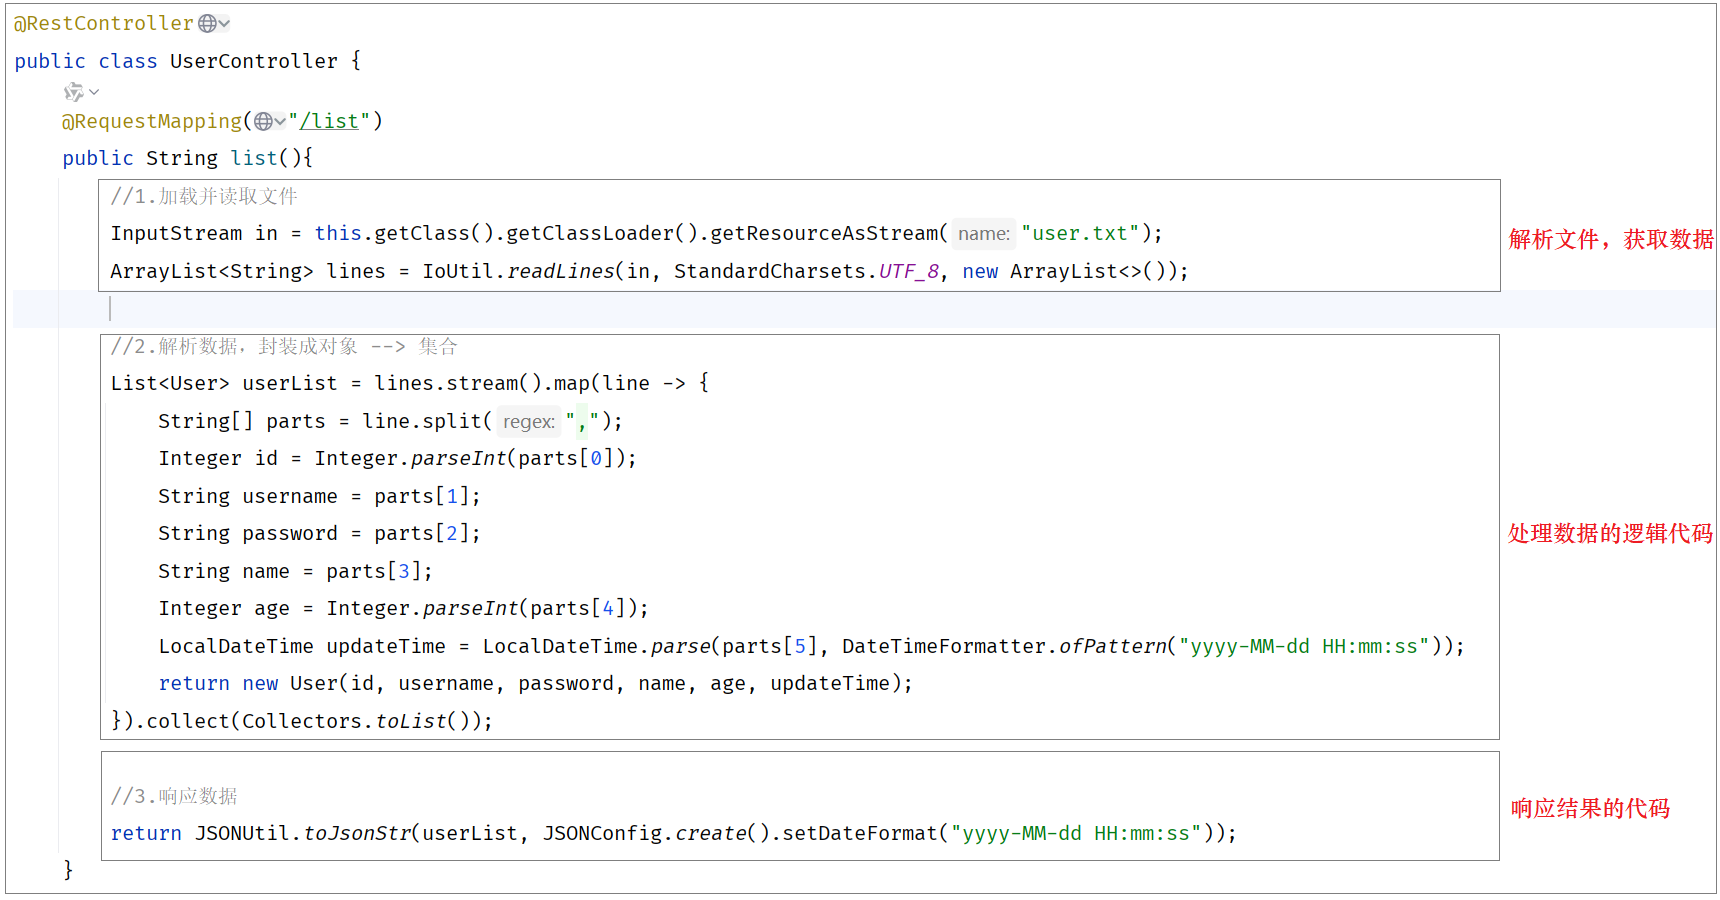

当前程序的这个业务逻辑还是比较简单的，如果业务逻辑再稍微复杂一点，我们会看到Controller方法的代码量就很大了。

- 当我们要修改操作数据部分的代码，需要改动Controller
- 当我们要完善逻辑处理部分的代码，需要改动Controller
- 当我们需要修改数据响应的代码，还是需要改动Controller

这样呢，就会造成我们整个工程代码的复用性比较差，而且代码难以维护。 那如何解决这个问题呢？其实在现在的开发中，有非常成熟的解决思路，那就是分层开发。


## 4 分层解耦


### 4.1 三层架构


#### 4.1.1 介绍

在我们进行程序设计以及程序开发时，尽可能让每一个接口、类、方法的职责更单一些（单一职责原则）。

> 单一职责原则：一个类或一个方法，就只做一件事情，只管一块功能。
> 
> 这样就可以让类、接口、方法的复杂度更低，可读性更强，扩展性更好，也更利于后期的维护。

我们之前开发的程序呢，并不满足单一职责原则。下面我们来分析下之前的程序：

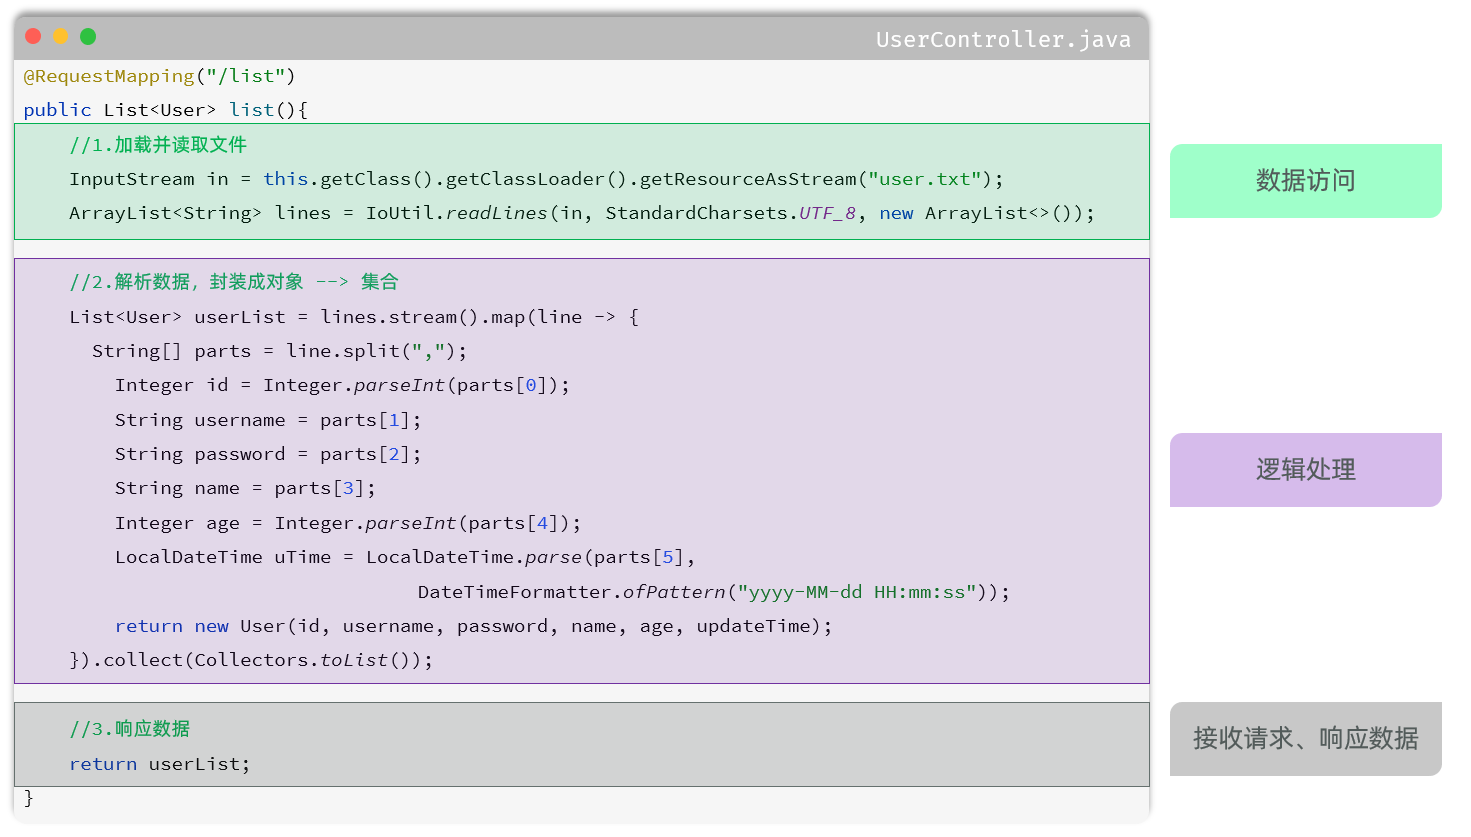

那其实我们上述案例的处理逻辑呢，从组成上看可以分为三个部分：

- 数据访问：负责业务数据的维护操作，包括增、删、改、查等操作。
- 逻辑处理：负责业务逻辑处理的代码。
- 请求处理、响应数据：负责，接收页面的请求，给页面响应数据。

按照上述的三个组成部分，在我们项目开发中呢，可以将代码分为三层，如图所示：

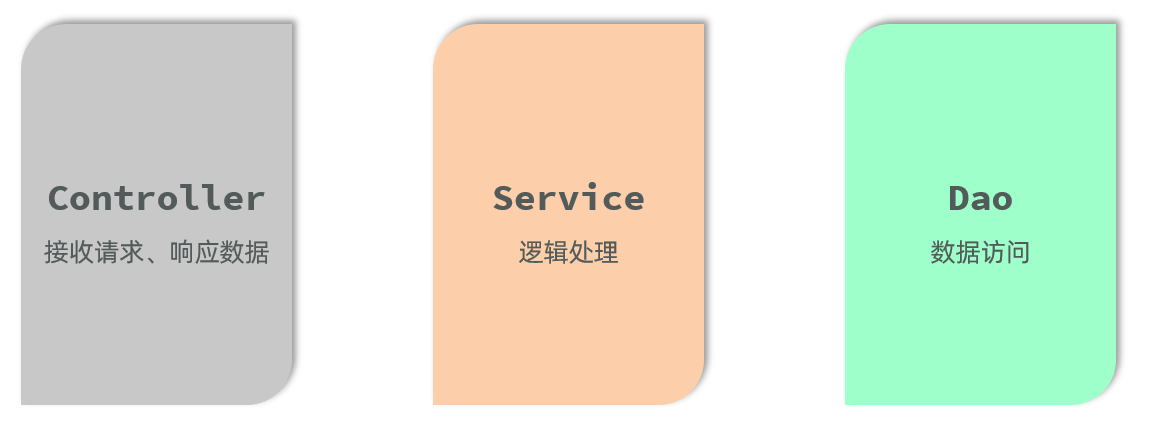

- Controller：控制层。接收前端发送的请求，对请求进行处理，并响应数据。
- Service：业务逻辑层。处理具体的业务逻辑。
- Dao：数据访问层(Data Access Object)，也称为持久层。负责数据访问操作，包括数据的增、删、改、查。

基于三层架构的程序执行流程，如图所示：

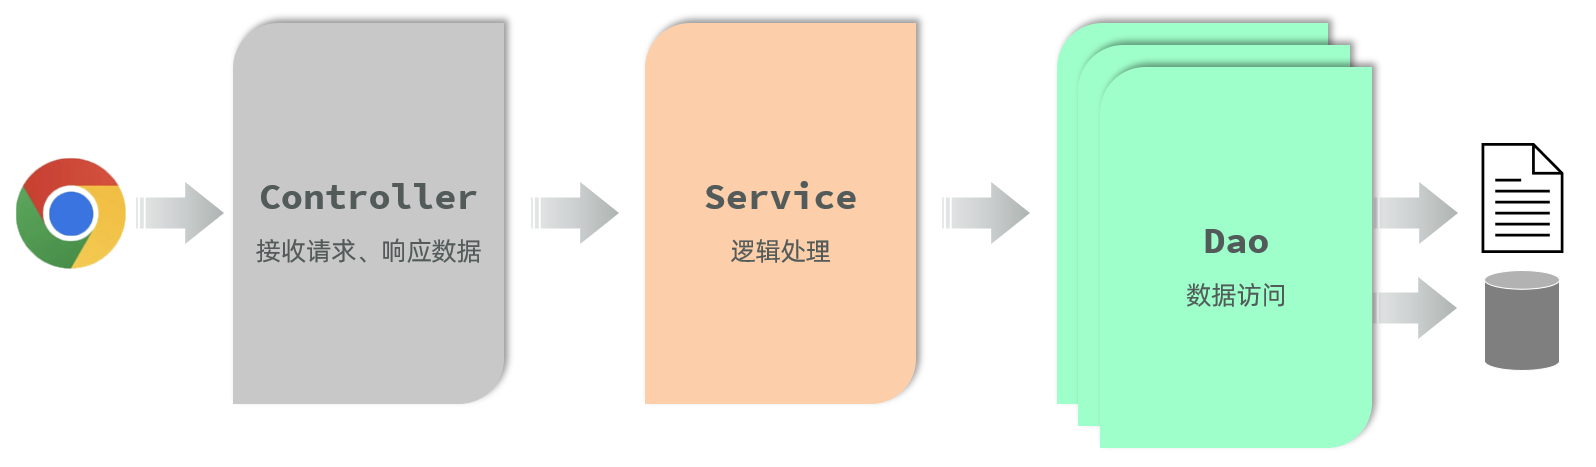

- 前端发起的请求，由Controller层接收（Controller响应数据给前端）
- Controller层调用Service层来进行逻辑处理（Service层处理完后，把处理结果返回给Controller层）
- Serivce层调用Dao层（逻辑处理过程中需要用到的一些数据要从Dao层获取）
- Dao层操作文件中的数据（Dao拿到的数据会返回给Service层）

> 思考：按照三层架构的思想，如果要对业务逻辑(Service层)进行变更，会影响到Controller层和Dao层吗？ 
> 
> 答案：不会影响。 （程序的扩展性、维护性变得更好了）
> 
> > **补充：**这个结论以接口约定保持兼容为前提。只修改 Service 内部实现时，Controller 和 Dao 常可不变；如果修改方法签名、数据结构或业务契约，其他层仍可能要配合调整。分层是降低影响范围，不是消除所有依赖。

> **补充：三层架构与 MVC 不是逐项对应的两套名字。**Controller、Service、Dao 是按请求处理、业务逻辑、数据访问划分职责；MVC 的 Model、View、Controller 是另一种组织界面交互的方式。本章用 Spring MVC 实现控制层，Vue 页面负责展示，不能把 Service 直接等同于 View、把 Dao 直接等同于 Model。


#### 4.1.2 代码拆分

我们使用三层架构思想，来改造下之前的程序：

- 控制层包名：<code>com.itheima.controller</code>
- 业务逻辑层包名：<code>com.itheima.service</code>
- 数据访问层包名：<code>com.itheima.dao</code>

<strong>1). 控制层：接收前端发送的请求，对请求进行处理，并响应数据</strong>

在 <code>com.itheima.controller</code> 中创建UserController类，代码如下：

````java
package com.itheima.controller;

import com.itheima.pojo.User;
import com.itheima.service.UserService;
import com.itheima.service.impl.UserServiceImpl;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import java.util.List;

@RestController
public class UserController {
    
    private UserService userService = new UserServiceImpl();

    @RequestMapping("/list")
    public List<User> list(){
        //1.调用Service
        List<User> userList = userService.findAll();
        //2.响应数据
        return userList;
    }

}
````

<strong>2). 业务逻辑层：</strong><strong>处理具体的业务逻辑</strong>

在 <code>com.itheima.service</code>中创建UserSerivce接口，代码如下：

````java
package com.itheima.service;

import com.itheima.pojo.User;
import java.util.List;

public interface UserService {

    public List<User> findAll();

}
````

在 <code>com.itheima.service.</code><code>impl</code> 中创建UserSerivceImpl接口，代码如下：

> **勘误：**这里实际创建的是 `UserServiceImpl` **实现类**，不是接口；接口名统一为 `UserService`，不要照抄说明文字中的 `Serivce` 拼写。

````java
package com.itheima.service.impl;

import com.itheima.dao.UserDao;
import com.itheima.dao.impl.UserDaoImpl;
import com.itheima.pojo.User;
import com.itheima.service.UserService;

import java.time.LocalDateTime;
import java.time.format.DateTimeFormatter;
import java.util.List;
import java.util.stream.Collectors;

public class UserServiceImpl implements UserService {

    private UserDao userDao = new UserDaoImpl();

    @Override
    public List<User> findAll() {
        List<String> lines = userDao.findAll();
        List<User> userList = lines.stream().map(line -> {
            String[] parts = line.split(",");
            Integer id = Integer.parseInt(parts[0]);
            String username = parts[1];
            String password = parts[2];
            String name = parts[3];
            Integer age = Integer.parseInt(parts[4]);
            LocalDateTime updateTime = LocalDateTime.parse(parts[5], DateTimeFormatter.ofPattern("yyyy-MM-dd HH:mm:ss"));
            return new User(id, username, password, name, age, updateTime);
        }).collect(Collectors.toList());
        return userList;
    }
}
````

<strong>3). 数据访问层：负责数据的访问操作，包含数据的增、删、改、查</strong>

在 <code>com.itheima.dao</code>中创建UserDao接口，代码如下：

````java
package com.itheima.dao;

import java.util.List;

public interface UserDao {

    public List<String> findAll();

}
````

在 <code>com.itheima.dao.impl</code> 中创建UserDaoImpl接口，代码如下：

> **勘误：**`UserDaoImpl` 同样是实现类，实现的是前面定义的 `UserDao` 接口。

````java
package com.itheima.dao.impl;

import cn.hutool.core.io.IoUtil;
import com.itheima.dao.UserDao;

import java.io.InputStream;
import java.nio.charset.StandardCharsets;
import java.util.ArrayList;
import java.util.List;

public class UserDaoImpl implements UserDao {
    @Override
    public List<String> findAll() {
        InputStream in = this.getClass().getClassLoader().getResourceAsStream("user.txt");
        ArrayList<String> lines = IoUtil.readLines(in, StandardCharsets.UTF_8, new ArrayList<>());
        return lines;
    }
}
````

> **补充：**原 Dao 片段没有显式关闭输入流，资源不存在时也未单独处理。第 4.6 节使用 `try-with-resources` 关闭流，并在找不到文件时给出明确错误。读取打包后的 classpath 资源仍可用流，不应假设它一定是磁盘上的普通文件路径。

具体的请求调用流程：

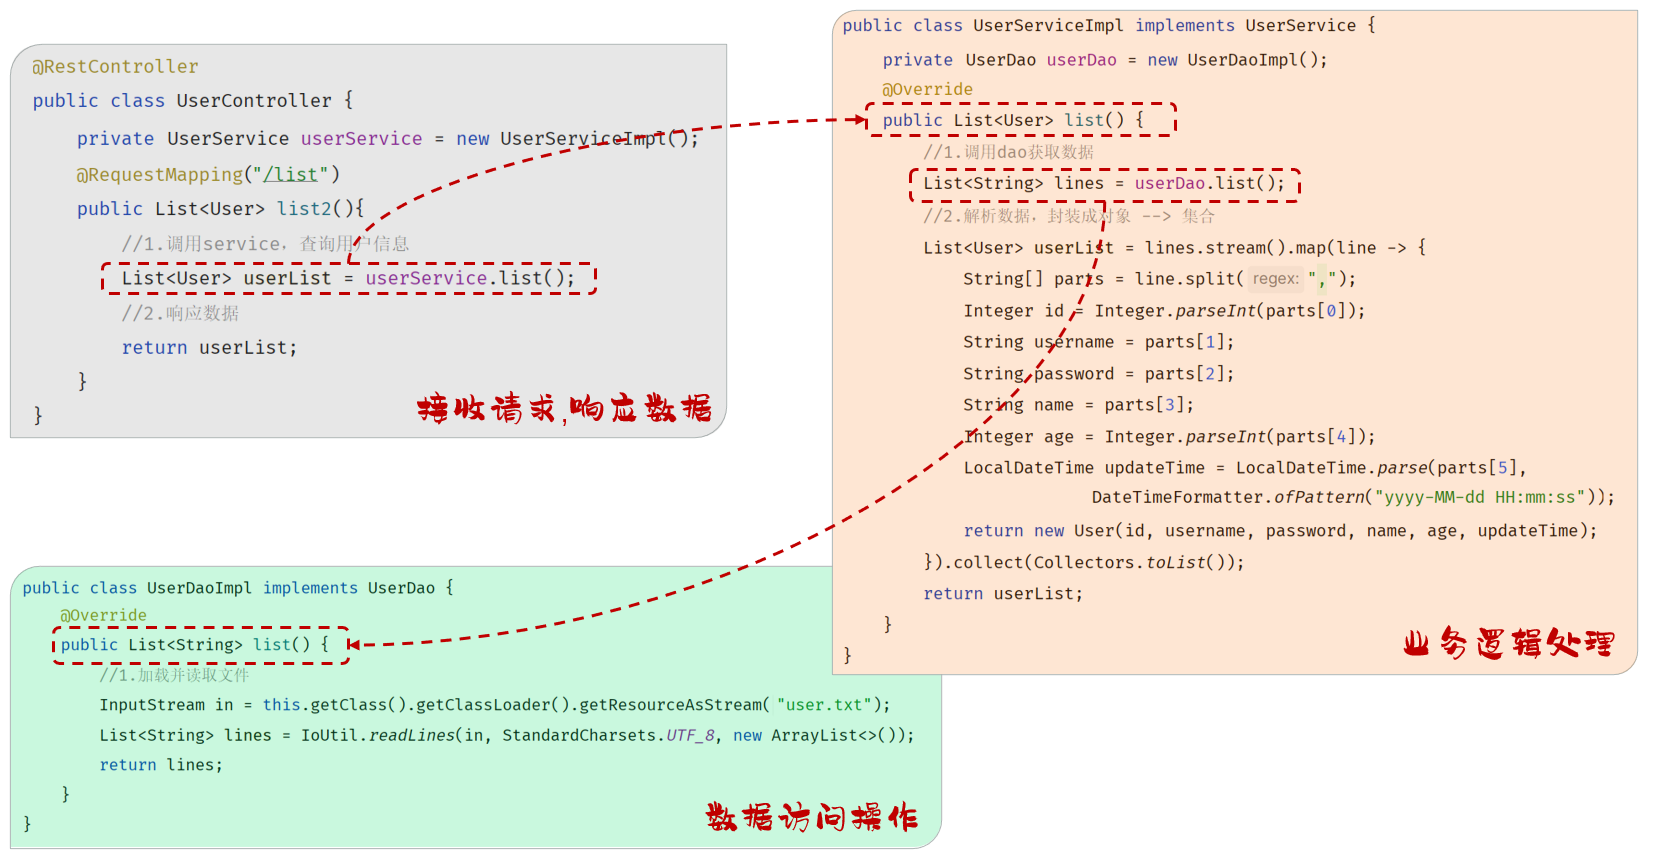

> 三层架构的好处：
> 
> 1. 复用性强
> 2. 便于维护
> 3. 利用扩展


### 4.2 分层解耦


#### 4.2.1 问题分析

由于我们现在在程序中，需要什么对象，直接new一个对象 <code>new UserServiceImpl()</code>  。

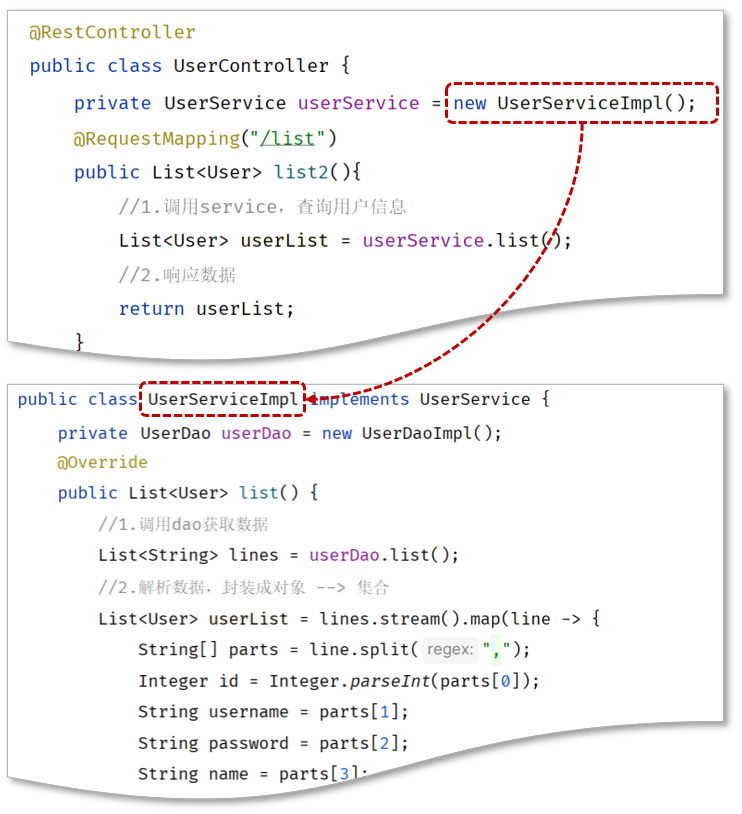

如果说我们需要更换实现类，比如由于业务的变更，UserServiceImpl 不能满足现有的业务需求，我们需要切换为 UserServiceImpl2 这套实现，就需要修改Contorller的代码，需要创建 UserServiceImpl2 的实现<code>new UserServiceImpl2()</code> 。

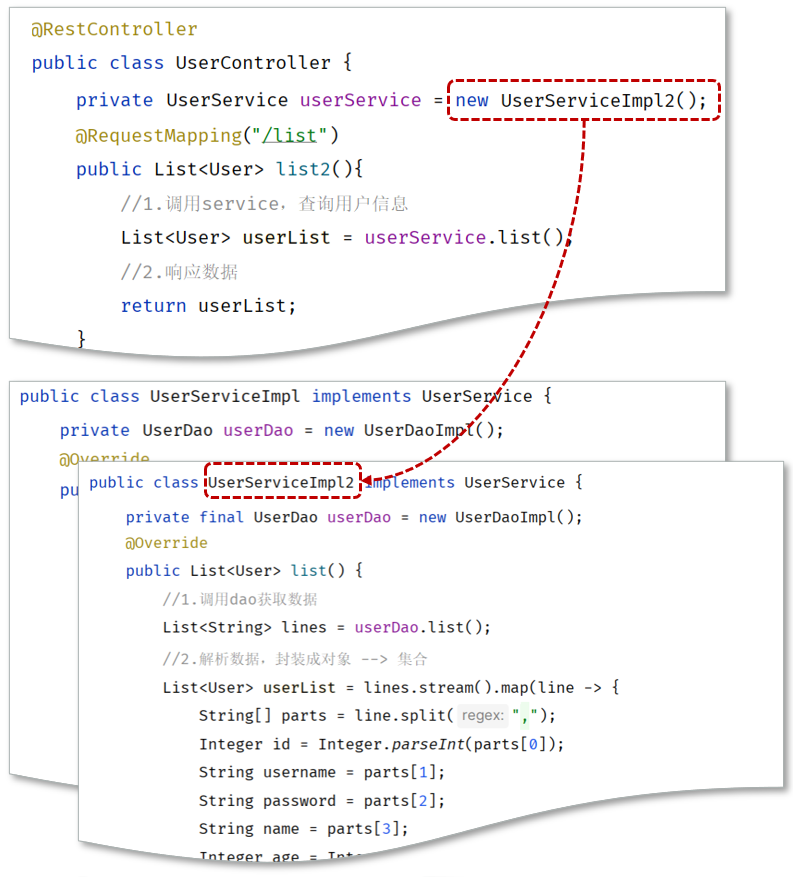

Service中调用Dao，也是类似的问题。这种呢，我们就称之为层与层之间 <strong>耦合</strong> 了。 那什么是耦合呢 ？

首先需要了解软件开发涉及到的两个概念：内聚和耦合。

- <strong>内聚：</strong>软件中各个功能模块内部的功能联系。
- <strong>耦合：</strong>衡量软件中各个层/模块之间的依赖、关联的程度。

<strong>软件设计原则：高内聚低耦合。</strong>

> <strong>高内聚</strong><strong>：</strong>指的是一个模块中各个元素之间的联系的紧密程度，如果各个元素(语句、程序段)之间的联系程度越高，则内聚性越高，即 "高内聚"。
> 
> <strong>低耦合：</strong>指的是软件中各个层、模块之间的依赖关联程序越低越好。

目前层与层之间是存在耦合的，Controller耦合了Service、Service耦合了Dao。而 高内聚、低耦合的目的是使程序模块的可重用性、移植性大大增强。

那最终我们的目标呢，就是做到层与层之间，尽可能的降低耦合，甚至解除耦合。

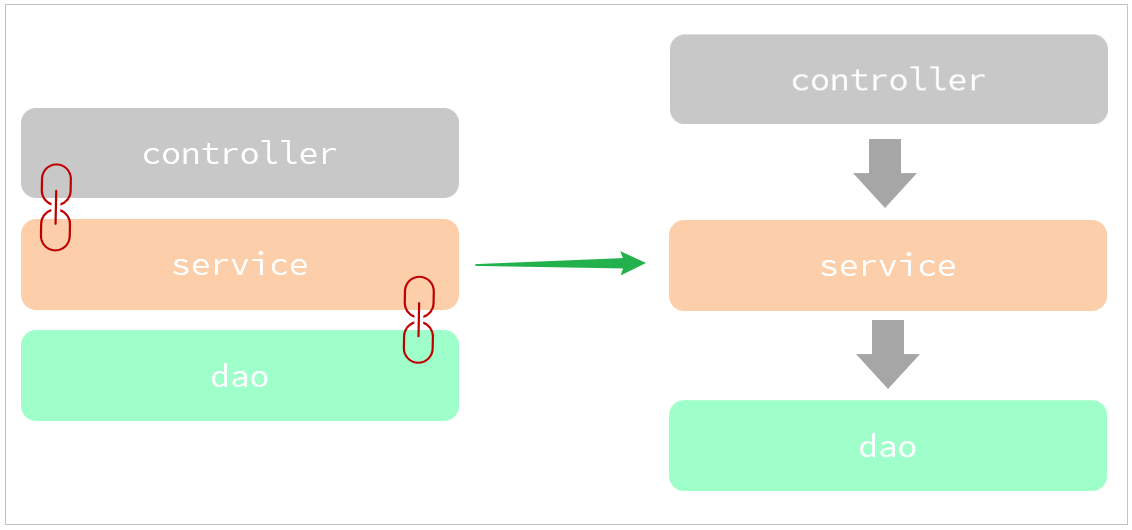


#### 4.2.2 解耦思路

之前我们在编写代码时，需要什么对象，就直接new一个就可以了。 这种做法呢，层与层之间代码就耦合了，当service层的实现变了之后， 我们还需要修改controller层的代码。

那应该怎么解耦呢？

<strong>1). 首先不能在EmpController中使用new对象。代码如下：</strong>

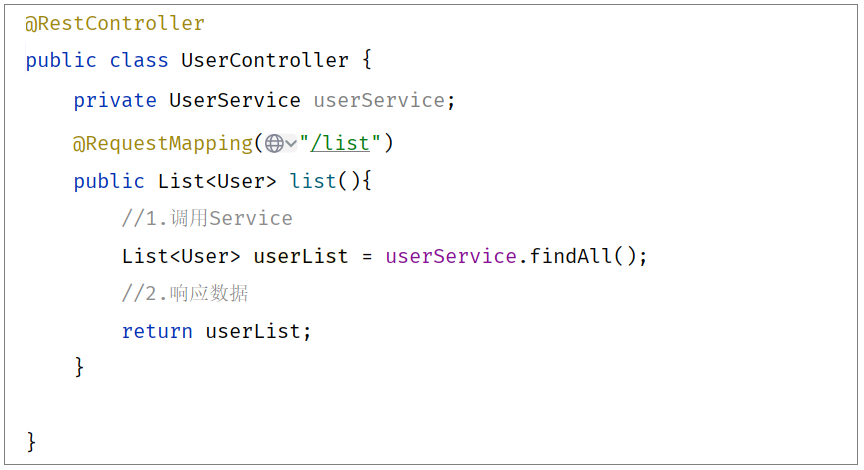

此时，就存在另一个问题了，不能new，就意味着没有业务层对象（程序运行就报错），怎么办呢? 

我们的解决思路是：

- 提供一个容器，容器中存储一些对象(例：UserService对象)
- Controller程序从容器中获取UserService类型的对象

<strong>2). 将要用到的对象交给一个容器管理。</strong>

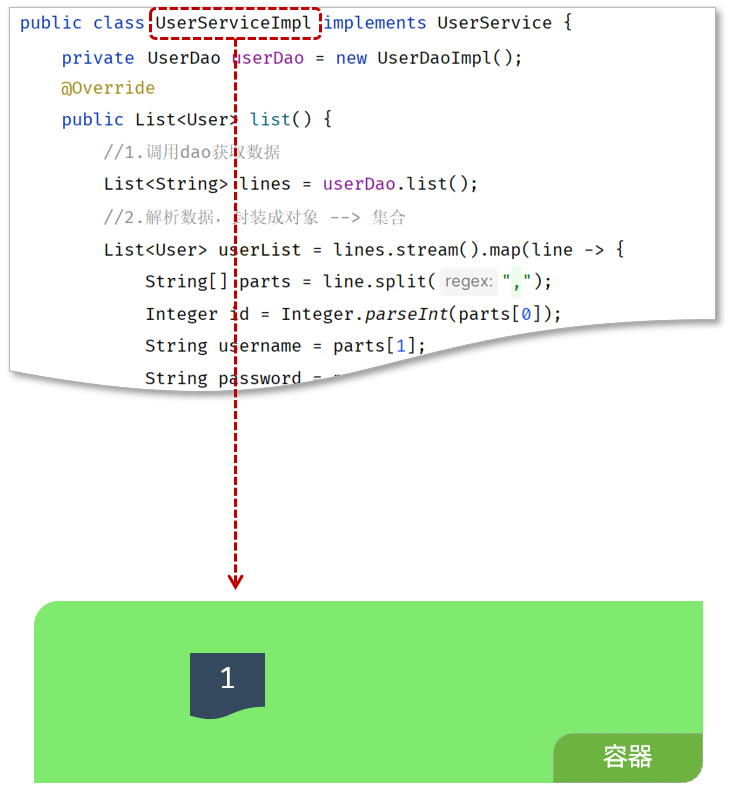

<strong>3). 应用程序中用到这个对象，就直接从容器中获取</strong>

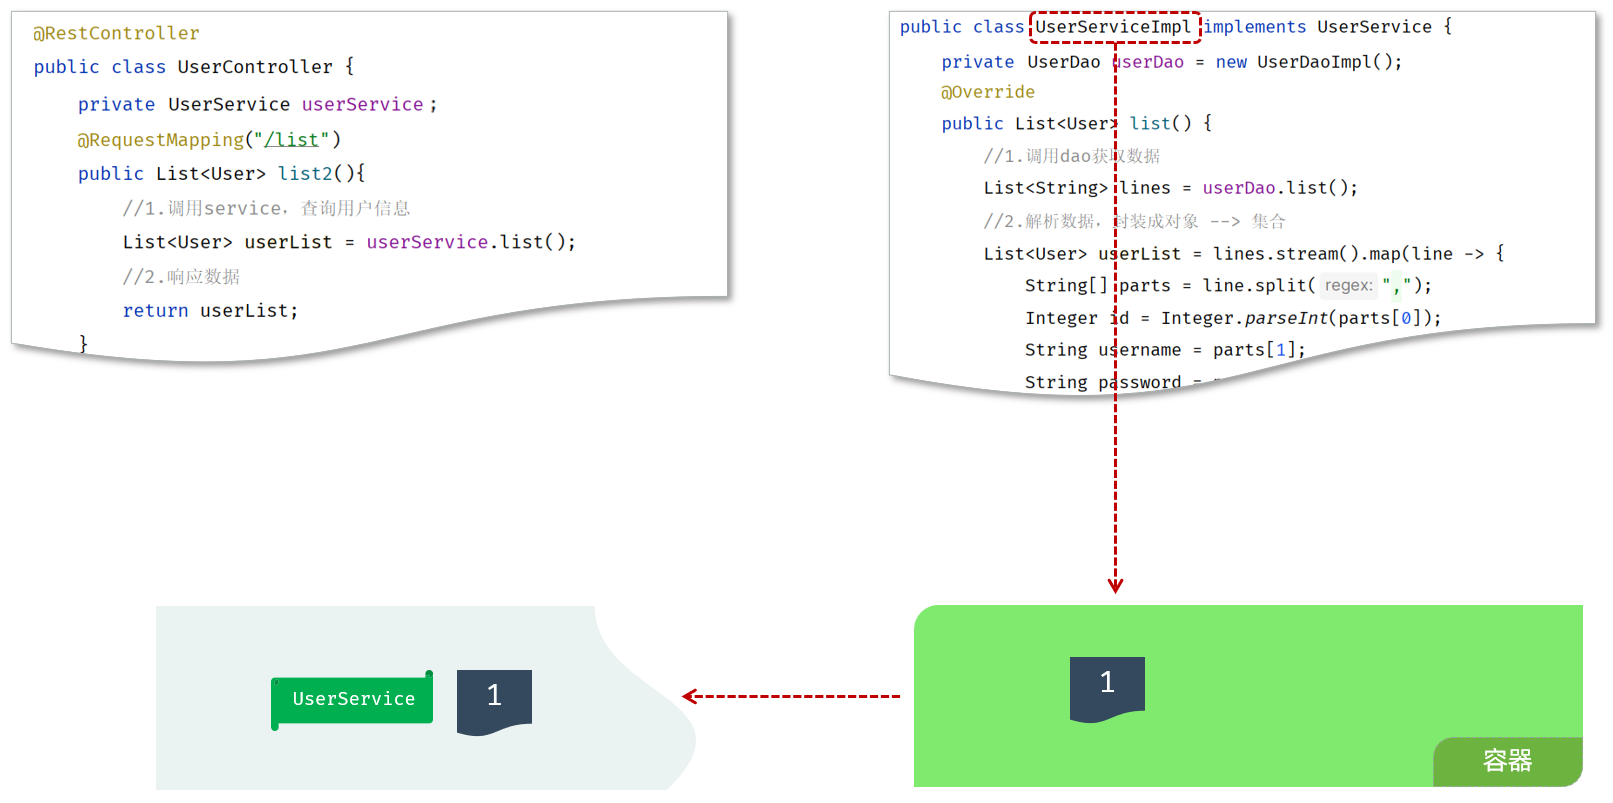

那问题来了，我们如何将对象交给容器管理呢？ 程序运行时，容器如何为程序提供依赖的对象呢？ 

我们想要实现上述解耦操作，就涉及到Spring中的两个核心概念：

> - <strong>控制反转</strong><strong>：</strong> Inversion Of Control，简称<strong>IOC</strong>。对象的创建控制权由程序自身转移到外部（容器），这种思想称为控制反转。
> 
>     - 对象的创建权由程序员主动创建转移到容器(由容器创建、管理对象)。这个容器称为：IOC容器或Spring容器。
> - <strong>依赖注入</strong><strong>：</strong> Dependency Injection，简称<strong>DI</strong>。容器为应用程序提供运行时，所依赖的资源，称之为依赖注入。
> 
>     - 程序运行时需要某个资源，此时容器就为其提供这个资源。
>     - 例：EmpController程序运行时需要EmpService对象，Spring容器就为其提供并注入EmpService对象。
> 
>     > **勘误：**本章案例的名字是 `UserController / UserService`，说明文字中的 `EmpController / EmpService` 是遗留名称。IOC 管对象的创建与生命周期，DI 把它需要的协作对象提供进去；“交给容器”不意味着业务接口之间再也没有依赖。
> 
> - <strong>bean对象：</strong>IOC容器中创建、管理的对象，称之为：bean对象。


### 4.3 IOC&DI入门

<strong>1). 将Service及Dao层的实现类，交给IOC容器管理</strong>

在实现类加上 <code>@Component</code> 注解，就代表把当前类产生的对象交给IOC容器管理。

<strong>A. UserDaoImpl</strong>

````java
@Component
public class UserDaoImpl implements UserDao {
    @Override
    public List<String> findAll() {
        InputStream in = this.getClass().getClassLoader().getResourceAsStream("user.txt");
        ArrayList<String> lines = IoUtil.readLines(in, StandardCharsets.UTF_8, new ArrayList<>());
        return lines;
    }
}
````

<strong>B. UserServiceImpl</strong>

````java
@Component
public class UserServiceImpl implements UserService {

    private UserDao userDao;

    @Override
    public List<User> findAll() {
        List<String> lines = userDao.findAll();
        List<User> userList = lines.stream().map(line -> {
            String[] parts = line.split(",");
            Integer id = Integer.parseInt(parts[0]);
            String username = parts[1];
            String password = parts[2];
            String name = parts[3];
            Integer age = Integer.parseInt(parts[4]);
            LocalDateTime updateTime = LocalDateTime.parse(parts[5], DateTimeFormatter.ofPattern("yyyy-MM-dd HH:mm:ss"));
            return new User(id, username, password, name, age, updateTime);
        }).collect(Collectors.toList());
        return userList;
    }
}
````

> **说明：**这一段是“先注册 Bean”的中间状态，只有 `@Component` 还没有给 userDao 注入对象，直接调用会遇到空引用。紧接着的第 2 步会加入 `@Autowired`；应把两步完成后再运行。

<strong>2). 为Controller 及 Service注入运行时所依赖的对象</strong>

<strong>A. UserServiceImpl</strong>

````java
@Component
public class UserServiceImpl implements UserService {

    @Autowired
    private UserDao userDao;
    
    @Override
    public List<User> findAll() {
        List<String> lines = userDao.findAll();
        List<User> userList = lines.stream().map(line -> {
            String[] parts = line.split(",");
            Integer id = Integer.parseInt(parts[0]);
            String username = parts[1];
            String password = parts[2];
            String name = parts[3];
            Integer age = Integer.parseInt(parts[4]);
            LocalDateTime updateTime = LocalDateTime.parse(parts[5], DateTimeFormatter.ofPattern("yyyy-MM-dd HH:mm:ss"));
            return new User(id, username, password, name, age, updateTime);
        }).collect(Collectors.toList());
        return userList;
    }
}
````

<strong>B. UserController</strong>

````java
@RestController
public class UserController {
    
    @Autowired
    private UserService userService;

    @RequestMapping("/list")
    public List<User> list(){
        //1.调用Service
        List<User> userList = userService.findAll();
        //2.响应数据
        return userList;
    }

}
````

启动服务，运行测试。 打开浏览器，地址栏直接访问：http://localhost:8080/user.html 。 依然正常访问，就说明入门程序完成了。 已经完成了层与层之间的解耦。

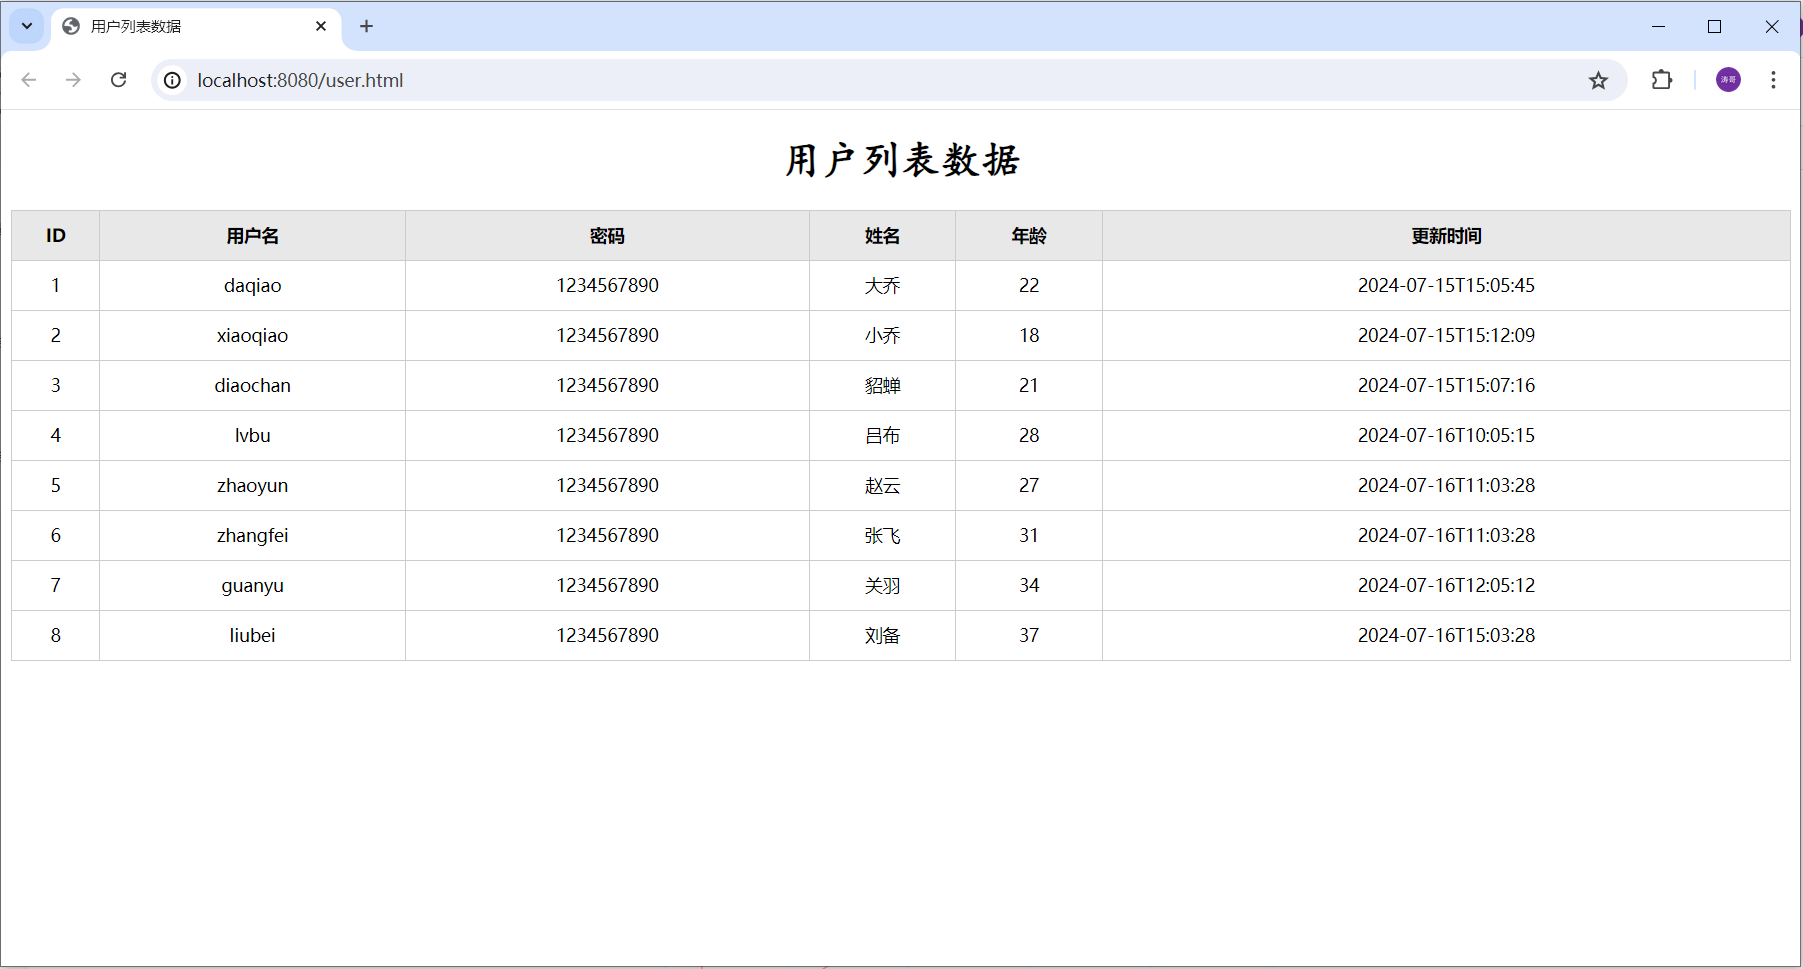


### 4.4 IOC详解

通过IOC和DI的入门程序呢，我们已经基本了解了IOC和DI的基础操作。接下来呢，我们学习下IOC控制反转和DI依赖注入的细节。

#### 4.4.1 Bean的声明

前面我们提到IOC控制反转，就是将对象的控制权交给Spring的IOC容器，由IOC容器创建及管理对象。IOC容器创建的对象称为bean对象。

在之前的入门案例中，要把某个对象交给IOC容器管理，需要在类上添加一个注解：<strong><code>@Component</code></strong>

而Spring框架为了更好的标识web应用程序开发当中，bean对象到底归属于哪一层，又提供了@Component的衍生注解：

| 注解 | 说明 | 位置 |
| --- | --- | --- |
| @Component | 声明bean的基础注解 | 不属于以下三类时，用此注解 |
| @Controller | @Component的衍生注解 | 标注在控制层类上 |
| @Service | @Component的衍生注解 | 标注在业务层类上 |
| @Repository | @Component的衍生注解 | 标注在数据访问层类上（由于与mybatis整合，用的少） |

那么此时，我们就可以使用 <code>@Service</code> 注解声明Service层的bean。 使用 <code>@Repository</code> 注解声明Dao层的bean。 代码实现如下：

Service层:

````java
@Service
public class UserServiceImpl implements UserService {

    private UserDao userDao;

    @Override
    public List<User> findAll() {
        List<String> lines = userDao.findAll();
        List<User> userList = lines.stream().map(line -> {
            String[] parts = line.split(",");
            Integer id = Integer.parseInt(parts[0]);
            String username = parts[1];
            String password = parts[2];
            String name = parts[3];
            Integer age = Integer.parseInt(parts[4]);
            LocalDateTime updateTime = LocalDateTime.parse(parts[5], DateTimeFormatter.ofPattern("yyyy-MM-dd HH:mm:ss"));
            return new User(id, username, password, name, age, updateTime);
        }).collect(Collectors.toList());
        return userList;
    }
}
````

> **勘误：**本例将 `@Component` 换成 `@Service` 时，漏保留了 userDao 的依赖注入。`@Service` 只负责声明组件，不会自动给所有字段赋值。沿用前文可在字段上补 `@Autowired`；也可以像第 4.6 节那样使用唯一构造器注入。

Dao层:

````java
@Repository
public class UserDaoImpl implements UserDao {
    @Override
    public List<String> findAll() {
        InputStream in = this.getClass().getClassLoader().getResourceAsStream("user.txt");
        ArrayList<String> lines = IoUtil.readLines(in, StandardCharsets.UTF_8, new ArrayList<>());
        return lines;
    }
}
````

> <strong>注意1</strong>：声明bean的时候，可以通过注解的value属性指定bean的名字，如果没有指定，默认为类名首字母小写。
> 
> <strong>注意2</strong>：使用以上四个注解都可以声明bean，但是在springboot集成web开发中，声明控制器bean只能用@Controller。
> 
> > **勘误：**也可以使用本章一直在用的 `@RestController`，因为它组合了 `@Controller` 和 `@ResponseBody`。这里要表达的是：仅用普通 `@Component`、`@Service` 等声明一个 Bean，不等于它自动成为 Spring MVC 请求处理控制器。

#### 4.4.2 组件扫描

> 问题：使用前面学习的四个注解声明的bean，一定会生效吗？
> 
> 答案：不一定。（原因：bean想要生效，还需要被组件扫描）

- 前面声明bean的四大注解，要想生效，还需要被组件扫描注解 <code>@ComponentScan</code> 扫描。
- 该注解虽然没有显式配置，但是实际上已经包含在了启动类声明注解 <code>@SpringBootApplication</code> 中，默认扫描的范围是启动类所在包及其子包。

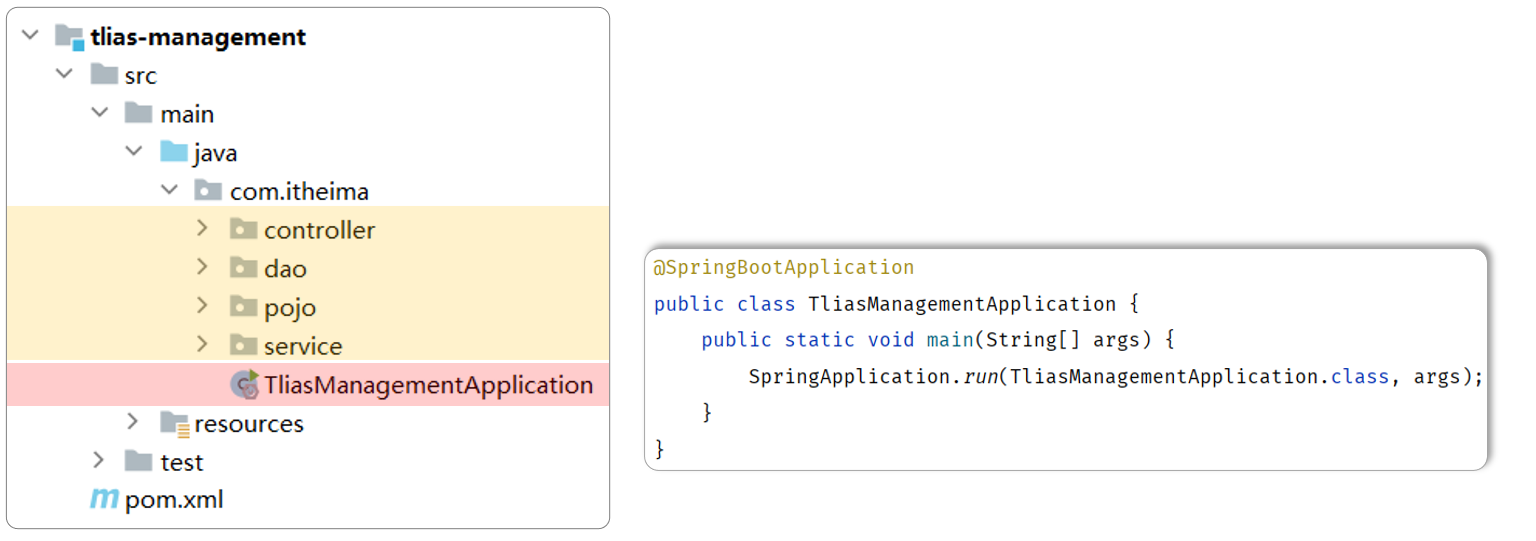

**配图结构转写：**启动类放在公共根包，业务组件放在该包或其子包。

```text
com.itheima
├── WebApplication
├── controller
├── service
│   └── impl
├── dao
│   └── impl
└── pojo
```

> **补充：**接口本身通常不负责创建实例，组件注解放在实现类上。也不要以为实体类都必须注册为 Bean：本章每条用户记录由业务代码创建，`User` 无需加 `@Component`。若代码移到根包之外，需要相应调整扫描范围。

所以，我们在项目开发中，只需要按照如上项目结构，将项目中的所有的业务类，都放在启动类所在包的子包中，就无需考虑组件扫描问题。


### 4.5 DI详解

上一小节我们讲解了控制反转IOC的细节，接下来呢，我们学习依赖注解DI的细节。

依赖注入，是指IOC容器要为应用程序去提供运行时所依赖的资源，而资源指的就是对象。

在入门程序案例中，我们使用了@Autowired这个注解，完成了依赖注入的操作，而这个Autowired翻译过来叫：自动装配。

<code>@Autowired</code>注解，默认是按照<strong>类型</strong>进行自动装配的（去IOC容器中找某个类型的对象，然后完成注入操作）

> 入门程序举例：在EmpController运行的时候，就要到IOC容器当中去查找EmpService这个类型的对象，而我们的IOC容器中刚好有一个EmpService这个类型的对象，所以就找到了这个类型的对象完成注入操作。


#### 4.5.1 @Autowired用法

@Autowired 进行依赖注入，常见的方式，有如下三种：

1). 属性注入

````java
@RestController
public class UserController {

    //方式一: 属性注入
    @Autowired
    private UserService userService;
    
  }
````

- 优点：代码简洁、方便快速开发。
- 缺点：隐藏了类之间的依赖关系、可能会破坏类的封装性。

2). 构造函数注入

````java
@RestController
public class UserController {

    //方式二: 构造器注入
    private final UserService userService;
    
    @Autowired //如果当前类中只存在一个构造函数, @Autowired可以省略
    public UserController(UserService userService) {
        this.userService = userService;
    }
    
 }   
````

> **补充：**本节三种注入片段是互相替代的写法，省略了 list 方法及部分导入，不要把多个同名 UserController 一起复制进项目。单构造器注入能配合 `final` 字段表达必需依赖，也便于测试时直接传入替代实现。框架注入只会发生在其管理的对象上，自己 `new UserController(...)` 时需要自己提供构造参数。

- 优点：能清晰地看到类的依赖关系、提高了代码的安全性。
- 缺点：代码繁琐、如果构造参数过多，可能会导致构造函数臃肿。
- <strong>注意：如果只有一个构造函数，@Autowired注解可以省略。（通常来说，也只有一个构造函数）</strong>

3). setter注入

````java
/**
 * 用户信息Controller
 */
@RestController
public class UserController {
    
    //方式三: setter注入
    private UserService userService;
    
    @Autowired
    public void setUserService(UserService userService) {
        this.userService = userService;
    }
    
}    
````

- 优点：保持了类的封装性，依赖关系更清晰。
- 缺点：需要额外编写setter方法，增加了代码量。

> 在项目开发中，基于@Autowired进行依赖注入时，基本都是第一种和第二种方式。（官方推荐第二种方式，因为会更加规范）但是在企业项目开发中，很多的项目中，也会选择第一种方式因为更加简洁、高效（在规范性方面进行了妥协）。


#### 4.5.2 注意事项

那如果在IOC容器中，存在多个相同类型的bean对象，会出现什么情况呢？

在下面的例子中，我们准备了两个UserService的实现类，并且都交给了IOC容器管理。 代码如下：

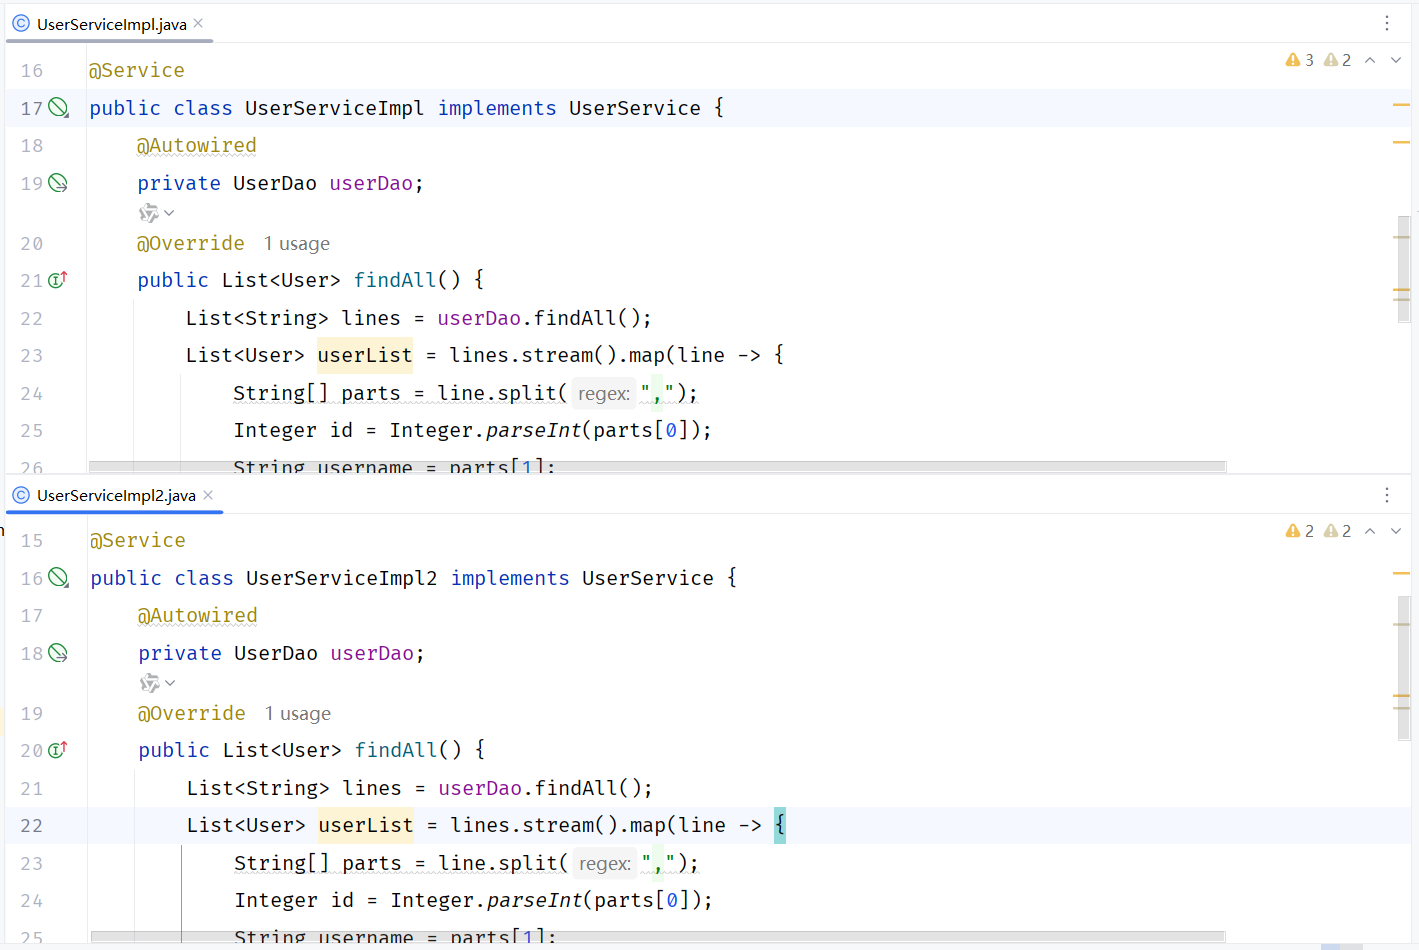

此时，我们启动项目会发现，控制台报错了：

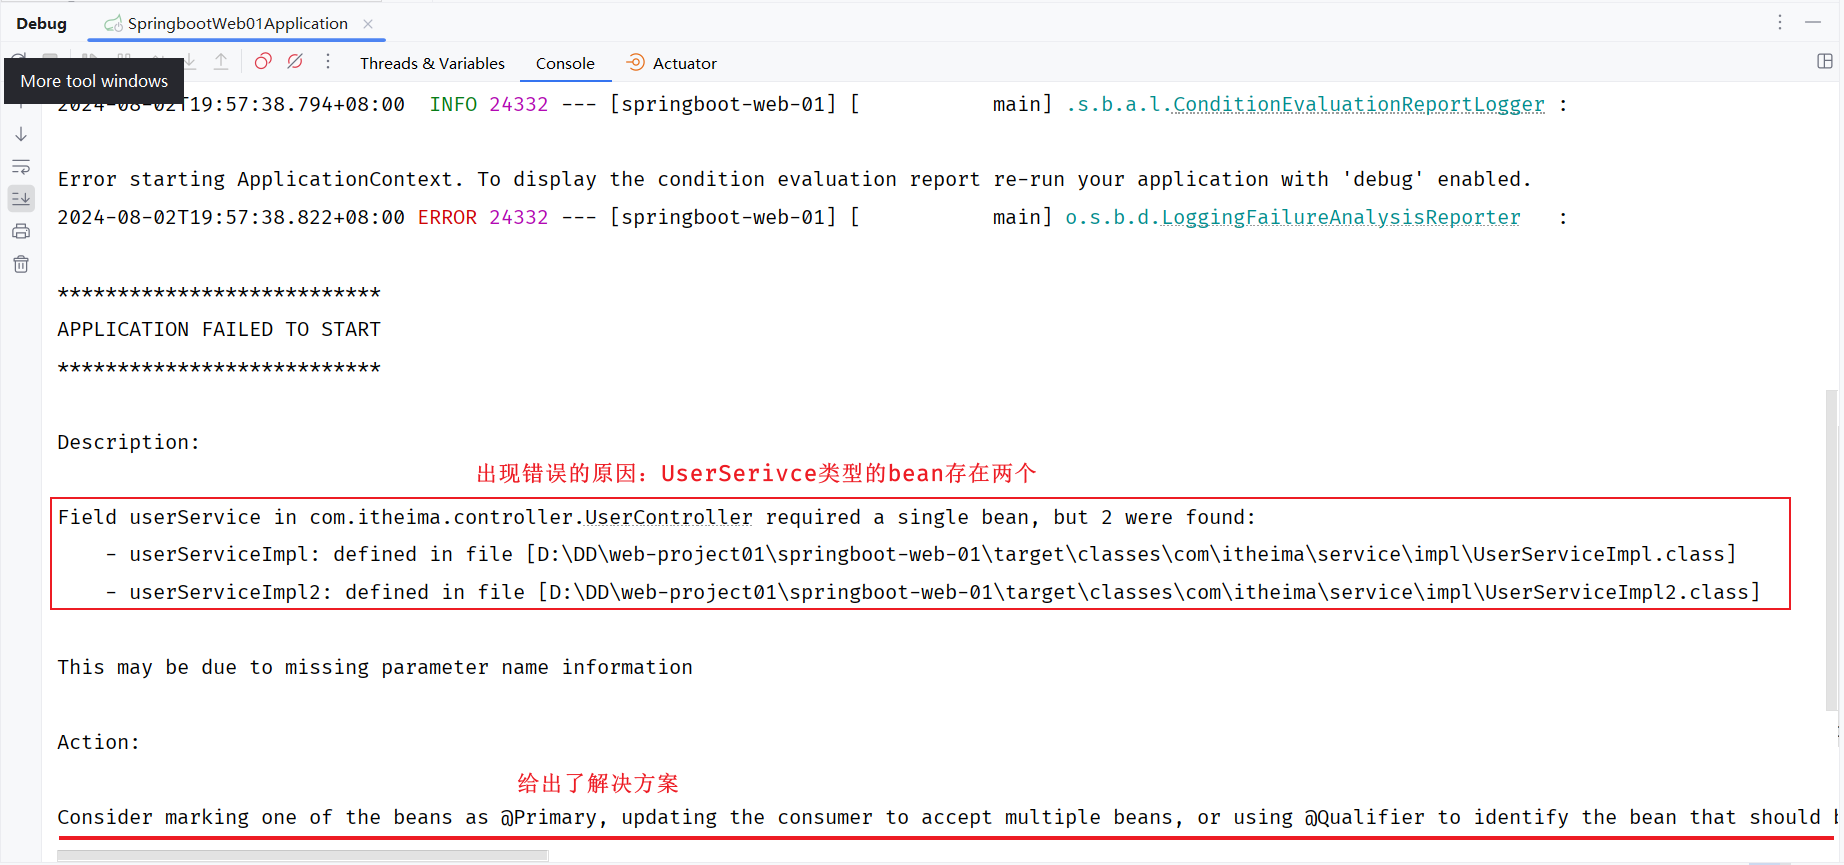

出现错误的原因呢，是因为在Spring的容器中，UserService这个类型的bean存在两个，框架不知道具体要注入哪个bean使用，所以就报错了。

如何解决上述问题呢？Spring提供了以下几种解决方案：

- @Primary
- @Qualifier
- @Resource

<strong>方案一：</strong><strong>使用@Primary注解</strong>

当存在多个相同类型的Bean注入时，加上@Primary注解，来确定默认的实现。

````java
@Primary
@Service
public class UserServiceImpl implements UserService {
}
````

> **补充：**这里只展示注解位置，不能真的把实现类内容删空：`UserService` 中的 `findAll()` 仍需实现。`@Primary` 提供多个候选 Bean 中的优先选择，不会把其他 Bean 从容器删除。

<strong>方案二：使用@Qualifier注解</strong>

指定当前要注入的bean对象。 在@Qualifier的value属性中，指定注入的bean的名称。 @Qualifier注解不能单独使用，必须配合@Autowired使用。

````java
@RestController
public class UserController {

    @Qualifier("userServiceImpl")
    @Autowired
    private UserService userService;
````

> **补充：**原片段省略了类的结尾 `}` 和 list 方法。这里按默认 Bean 名 `userServiceImpl` 选择对象。对于这种**字段注入**，`@Qualifier` 要与 `@Autowired` 配合；但“必须配合”不是所有场景的绝对规则，单构造器参数上也可使用 `@Qualifier`，而构造器本身不必写 `@Autowired`。

<strong>方案三：使用@Resource注解</strong>

是按照bean的名称进行注入。通过name属性指定要注入的bean的名称。

````java
@RestController
public class UserController {
        
    @Resource(name = "userServiceImpl")
    private UserService userService;
````

> **补充：**原片段同样省略了类的结尾 `}` 和 list 方法。本章 Spring Boot 3 应导入 `jakarta.annotation.Resource`。显式指定 `name="userServiceImpl"` 时按这个名字查找；不指定 name 时通常先按字段/属性名查找，没有匹配名称时再按类型回退。

> 面试题：@Autowird 与 @Resource的区别
> 
> - @Autowired 是spring框架提供的注解，而@Resource是JDK提供的注解
> 
> > **勘误：**`@Autowired` 来自 Spring；`@Resource` 来自标准 Common Annotations/Jakarta Annotations API，并不是当前 JDK 17 自带的注解。旧项目常见 `javax.annotation.Resource`，本章 Boot 3 使用 `jakarta.annotation.Resource`。
> >
> > `@Autowired` 主要按类型解析，再结合 `@Qualifier`、`@Primary` 等规则；当有多个候选时，在满足条件的情况下也会用注入点名称匹配。`@Resource` 优先按名称的规则也受是否显式指定 name 影响，不能只记“一个只看类型，一个永远只看名字”。实际跟练时明确选择一个实现即可，不需要同时套用三套方案。
> - @Autowired 默认是按照类型注入，而@Resource是按照名称注入

**补充：遇到注入失败，先数候选对象，再决定修改哪里。**

| 现象 | 检查思路 |
| --- | --- |
| 一个候选都没有 | 先看实现类是否注册为 Bean、是否在扫描范围内；加 `@Primary` 无法创造一个 Bean |
| 只有一个匹配候选 | 常规必需依赖可直接按类型注入；单构造器无需额外写 `@Autowired` |
| 多个候选，整个应用有首选实现 | 在首选实现类上使用 `@Primary` |
| 多个候选，某个调用方要指定实现 | 在该注入点使用 `@Qualifier`，或通过 `@Resource(name = "...")` 指定名称 |

`@Qualifier` 先缩小符合条件的候选范围，`@Primary` 再用于在候选中作优先选择；它们不是按源码书写先后依次覆盖。Spring 在符合条件时也可能按注入点名称消除歧义，所以“有两个实现必然启动失败”不够准确。本章跟练建议显式选择，方便读者判断实际注入的是谁。


### 4.6 补充：完整用户列表案例

这一节把讲义分散的片段合成可运行的工程。保留本章“读取 user.txt → 解析 User → 返回 JSON → Vue 渲染”的过程，使用前面已讲到的构造器注入，补齐 POM、启动类、文件关闭、日期格式和前端页面。它不包含数据库、登录、增删改等后续章节功能。

**文件来源说明：**业务分层和字段来自本章；下面的 `user.txt` 根据讲义效果图中的 8 条记录转写；`user.html` 是为跟练补写的页面，并非声称取到了原配套压缩包中的源码。password 仅沿用课程演示值，真实系统的列表接口不应返回这一字段。

**1. 创建工程与目录。**如果已有前文的 Spring Boot 工程，也可以在其中按这些路径整理。相同包名和类名只能保留一个版本，不要把前面每一步的 UserController、UserServiceImpl 都同时复制进去。

```text
springboot-web-04/
├── pom.xml
└── src/main/
    ├── java/com/itheima/
    │   ├── WebApplication.java
    │   ├── pojo/User.java
    │   ├── controller/UserController.java
    │   ├── service/
    │   │   ├── UserService.java
    │   │   └── impl/UserServiceImpl.java
    │   └── dao/
    │       ├── UserDao.java
    │       └── impl/UserDaoImpl.java
    └── resources/
        ├── user.txt
        └── static/user.html
```

**2. 配置 `pom.xml`。**Spring Boot 版本固定为课程截图中的 `3.2.8`，Java 版本为 `17`。Web、Lombok 和测试起步依赖的版本由父 POM 管理；Hutool 沿用讲义的 `5.8.27`。Spring Boot Maven 插件会把项目重新打成包含依赖、可用 `java -jar` 启动的包，这与上一章普通 Java JAR 不同。

````xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>
    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.8</version>
        <relativePath/>
    </parent>
    <groupId>com.itheima</groupId>
    <artifactId>springboot-web-04</artifactId>
    <version>1.0-SNAPSHOT</version>
    <properties>
        <java.version>17</java.version>
        <project.build.sourceEncoding>UTF-8</project.build.sourceEncoding>
    </properties>
    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter-web</artifactId>
        </dependency>
        <dependency>
            <groupId>org.projectlombok</groupId>
            <artifactId>lombok</artifactId>
            <optional>true</optional>
        </dependency>
        <dependency>
            <groupId>cn.hutool</groupId>
            <artifactId>hutool-all</artifactId>
            <version>5.8.27</version>
        </dependency>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter-test</artifactId>
            <scope>test</scope>
        </dependency>
    </dependencies>
    <build>
        <plugins>
            <plugin>
                <groupId>org.springframework.boot</groupId>
                <artifactId>spring-boot-maven-plugin</artifactId>
            </plugin>
        </plugins>
    </build>
</project>
````


**3. 启动类：`src/main/java/com/itheima/WebApplication.java`。**


启动类放在 `com.itheima` 根包，覆盖 controller、service、dao 等组件所在子包。如果已有脚手架生成的启动类，可以沿用它；不要为了复制此例而额外保留两个负责同一应用的启动入口。

````java
package com.itheima;

import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;

@SpringBootApplication
public class WebApplication {
    public static void main(String[] args) {
        SpringApplication.run(WebApplication.class, args);
    }
}
````


**4. 实体类：`src/main/java/com/itheima/pojo/User.java`。**


字段、Lombok 注解沿用原讲义。这里给日期增加 `@JsonFormat`，让自动 JSON 序列化也使用截图中的 `yyyy-MM-dd HH:mm:ss` 格式，而不是依赖已经注释掉的 Hutool 格式设置。

````java
package com.itheima.pojo;

import com.fasterxml.jackson.annotation.JsonFormat;
import lombok.AllArgsConstructor;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.time.LocalDateTime;

@Data
@NoArgsConstructor
@AllArgsConstructor
public class User {
    private Integer id;
    private String username;
    private String password; // 仅沿用讲义的演示数据字段
    private String name;
    private Integer age;
    @JsonFormat(pattern = "yyyy-MM-dd HH:mm:ss")
    private LocalDateTime updateTime;
}
````


**5. Dao 接口：`src/main/java/com/itheima/dao/UserDao.java`。**


接口声明需要什么能力，本章返回文件中的文本行；实现细节由 UserDaoImpl 负责。

````java
package com.itheima.dao;

import java.util.List;

public interface UserDao {
    List<String> findAll();
}
````


**6. Dao 实现：`src/main/java/com/itheima/dao/impl/UserDaoImpl.java`。**


`@Repository` 注册数据访问组件。资源路径 `user.txt` 相对 classpath 根目录，即源码中的 `src/main/resources/user.txt`；打包后依然通过流读取。`try-with-resources` 保证方法结束时关闭流。

````java
package com.itheima.dao.impl;

import cn.hutool.core.io.IoUtil;
import com.itheima.dao.UserDao;
import org.springframework.stereotype.Repository;
import java.io.IOException;
import java.io.InputStream;
import java.nio.charset.StandardCharsets;
import java.util.ArrayList;
import java.util.List;

@Repository
public class UserDaoImpl implements UserDao {
    @Override
    public List<String> findAll() {
        try (InputStream in = getClass().getClassLoader()
                .getResourceAsStream("user.txt")) {
            if (in == null) {
                throw new IllegalStateException("classpath 中找不到 user.txt");
            }
            return IoUtil.readLines(in, StandardCharsets.UTF_8, new ArrayList<>());
        } catch (IOException e) {
            throw new IllegalStateException("读取 user.txt 失败", e);
        }
    }
}
````


**7. Service 接口：`src/main/java/com/itheima/service/UserService.java`。**


控制器需要的是“查到所有用户”的能力，因此接口返回 `List<User>`，不暴露文本行解析细节。

````java
package com.itheima.service;

import com.itheima.pojo.User;
import java.util.List;

public interface UserService {
    List<User> findAll();
}
````


**8. Service 实现：`src/main/java/com/itheima/service/impl/UserServiceImpl.java`。**


构造器接收 UserDao，由 Spring 提供实现对象。只存在一个构造器，所以不用再写 `@Autowired`。按课程的三层拆分，把文本到 User 的转换放在 Service；过滤空行并检查字段数，便于发现输入格式错误。每行字段内不能再包含逗号；复杂 CSV 应使用对应解析器。

````java
package com.itheima.service.impl;

import com.itheima.dao.UserDao;
import com.itheima.pojo.User;
import com.itheima.service.UserService;
import org.springframework.stereotype.Service;
import java.time.LocalDateTime;
import java.time.format.DateTimeFormatter;
import java.util.List;
import java.util.stream.Collectors;

@Service
public class UserServiceImpl implements UserService {
    private final UserDao userDao;

    public UserServiceImpl(UserDao userDao) {
        this.userDao = userDao;
    }

    @Override
    public List<User> findAll() {
        return userDao.findAll().stream()
                .filter(line -> !line.isBlank())
                .map(line -> {
                    String[] parts = line.split(",", -1);
                    if (parts.length != 6) {
                        throw new IllegalArgumentException("每行必须有6个字段");
                    }
                    return new User(
                            Integer.parseInt(parts[0].trim()),
                            parts[1].trim(),
                            parts[2].trim(),
                            parts[3].trim(),
                            Integer.parseInt(parts[4].trim()),
                            LocalDateTime.parse(parts[5].trim(),
                                    DateTimeFormatter.ofPattern("yyyy-MM-dd HH:mm:ss")));
                }).collect(Collectors.toList());
    }
}
````


**9. Controller：`src/main/java/com/itheima/controller/UserController.java`。**


控制器只负责接收查询请求、调用业务层并返回结果。这里用 `@GetMapping("/list")` 明确查询只支持 GET；它相当于将 `@RequestMapping` 的 HTTP 方法限定为 GET。返回 List 后，由框架完成 JSON 转换。

````java
package com.itheima.controller;

import com.itheima.pojo.User;
import com.itheima.service.UserService;
import org.springframework.web.bind.annotation.GetMapping;
import org.springframework.web.bind.annotation.RestController;
import java.util.List;

@RestController
public class UserController {
    private final UserService userService;

    public UserController(UserService userService) {
        this.userService = userService;
    }

    @GetMapping("/list")
    public List<User> list() {
        return userService.findAll();
    }
}
````


**10. 数据文件：`src/main/resources/user.txt`。**按 UTF-8 保存，不添加表头。每行按以下顺序填写：

```text
id,username,password,name,age,updateTime
```

这里各字段的类型分别为整数、字符串、字符串、字符串、整数、日期时间。截图中的 8 条记录转写如下：

````text
1,daqiao,1234567890,大乔,22,2024-07-15 15:05:45
2,xiaoqiao,1234567890,小乔,18,2024-07-15 15:12:09
3,diaochan,1234567890,貂蝉,21,2024-07-15 15:07:16
4,lvbu,1234567890,吕布,28,2024-07-16 10:05:15
5,zhaoyun,1234567890,赵云,27,2024-07-16 11:03:28
6,zhangfei,1234567890,张飞,31,2024-07-16 11:03:28
7,guanyu,1234567890,关羽,34,2024-07-16 12:05:12
8,liubei,1234567890,刘备,37,2024-07-16 15:03:28
````


**11. 前端页面：`src/main/resources/static/user.html`。**

页面沿用第二章的 Vue 3 + Axios 思路。`mounted` 在页面挂载后发送 GET `/list`，将响应数组交给 `users`，再由 `v-for` 渲染表格。它与当前页面同源；从后端的 `http://localhost:8080/user.html` 打开时，不需要另配跨域。

注意本章接口直接返回数组，因此取值是 `result.data`，不是第二章某个接口的 `result.data.data`。下面使用固定版本的公共脚本地址；也可以把同版本文件保存到 `static/js`，把 Axios 的 src 改为 `/js/axios.min.js`、Vue 的 import 改为 `/js/vue.esm-browser.js`。

````html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>用户列表数据</title>
  <style>
    body { margin: 24px; font-family: Arial, "Microsoft YaHei", sans-serif; }
    h1 { text-align: center; }
    table { width: 100%; border-collapse: collapse; }
    th, td { border: 1px solid #ccc; padding: 12px; text-align: center; }
    th { background: #eee; }
    .table-wrap { overflow-x: auto; }
    .error { color: #b42318; }
    [v-cloak] { display: none; }
  </style>
</head>
<body>
  <h1>用户列表数据</h1>
  <div id="app" v-cloak>
    <p v-if="loading">正在加载用户数据……</p>
    <p v-else-if="error" class="error">{{ error }}</p>
    <p v-else-if="users.length === 0">暂无用户数据。</p>
    <div v-else class="table-wrap">
      <table>
        <thead>
          <tr><th>ID</th><th>用户名</th><th>密码</th><th>姓名</th><th>年龄</th><th>更新时间</th></tr>
        </thead>
        <tbody>
          <tr v-for="user in users" :key="user.id">
            <td>{{ user.id }}</td><td>{{ user.username }}</td>
            <td>{{ user.password }}</td><td>{{ user.name }}</td>
            <td>{{ user.age }}</td><td>{{ user.updateTime }}</td>
          </tr>
        </tbody>
      </table>
    </div>
  </div>
  <script src="https://unpkg.com/axios@1.20.0/dist/axios.min.js"></script>
  <script type="module">
    import { createApp } from 'https://unpkg.com/vue@3.5.43/dist/vue.esm-browser.js';

    createApp({
      data() {
        return { users: [], loading: true, error: '' };
      },
      async mounted() {
        try {
          const result = await axios.get('/list', { timeout: 10000 });
          if (!Array.isArray(result.data)) {
            throw new Error('接口应返回用户数组');
          }
          this.users = result.data;
        } catch (error) {
          this.error = '加载失败：' + error.message;
        } finally {
          this.loading = false;
        }
      }
    }).mount('#app');
  </script>
</body>
</html>
````


**12. 启动并验证。**

1. Reload Maven Project，等待依赖下载和索引完成。运行 `WebApplication.main`。
2. 先访问 [用户列表接口](http://localhost:8080/list)，应得到含 8 个用户的 JSON 数组，首条姓名为“大乔”，末条姓名为“刘备”。
3. 再访问 [用户列表页面](http://localhost:8080/user.html)，应显示 8 行，日期如 `2024-07-15 15:05:45`。
4. 打开开发者工具的 Network，刷新页面，检查 user.html 请求和 /list 请求。后者应为 200，响应类型为 JSON，正文应直接是数组。

也可以在 POM 所在目录用 Maven 运行：

```text
mvn spring-boot:run
```

要验证打包后仍能读取 classpath 资源，先停止正在运行的服务，再执行：

```text
mvn package
java -jar target/springboot-web-04-1.0-SNAPSHOT.jar
```

如果已经通过 application.properties 修改端口，访问地址也相应改变。本章页面要从 Spring Boot 提供的 HTTP 地址打开，不是双击 HTML 走 file 协议，也不是继续用第二章的 Live Server 端口请求一个不存在的 /list。

**一次列表请求的具体流程：**

1. 浏览器加载 user.html，Vue 挂载完成后由 Axios 请求 /list。
2. Tomcat 接收 HTTP 请求，Spring MVC 根据映射找到 UserController。
3. Controller 调用已经注入的 UserService。
4. UserServiceImpl 调用已注入的 UserDao，读取 user.txt 中的文本行。
5. Service 将文本行解析成 User 对象列表，返回给 Controller。
6. 因为 Controller 是 @RestController，列表通过消息转换器写成 JSON 响应。
7. Axios 得到响应，Vue 更新 users，表格随之渲染。

容器通常在应用启动过程中完成这些组件的创建与注入，不是每次 HTTP 请求都按业务代码重新 new 一遍。


### 4.7 补充：按现象排查

| 现象 | 优先检查 |
| --- | --- |
| 项目生成或依赖下载失败 | 区分 Initializr 生成服务和 Maven 仓库下载；检查网络与上一章的 Maven 配置 |
| 服务启动后立刻退出/端口占用 | 终端异常和端口配置；确认运行的是带 SpringBootApplication 的启动类 |
| /hello 返回 Hello null | 是否带了 name 查询参数，以及方法是否依赖参数名绑定 |
| /hello 或 /list 返回 404 | 路径拼写、端口、控制器注解、组件扫描范围 |
| 返回 405 | 请求方法与 GetMapping/RequestMapping 的限制是否匹配 |
| /response 页面有文字但请求不是成功状态 | 原例主动设置了 401，检查 Network 中的状态码 |
| 编译提示 List 不能转为 String | 原例的 list 方法返回类型未修正为 List<User> |
| 注入字段为 null | 是否只写了 Service/Component 而未注入依赖，或对象是否由自己 new 出来 |
| 找不到某个 Bean | 实现类是否有组件注解、包是否在扫描范围、所需依赖是否添加 |
| 同类型 Bean 有多个导致启动失败 | 选择合适的 Primary、Qualifier 或 Resource 方案，并核对 Bean 名 |
| 读取 user.txt 失败 | 文件是否在 resources 根目录、是否重新构建，读取路径是否写错 |
| NumberFormatException/日期解析失败 | 六列数据的位置、数字格式和日期格式是否一致 |
| /user.html 能打开但表格为空 | /list 的实际响应结构、浏览器控制台、Vue/Axios 是否加载成功 |
| 页面一直没有显示 Vue 区域 | v-cloak 还未被移除时，先检查模块或脚本加载失败 |
| 页面出现跨域/请求发到错误端口 | 是否从后端同源的 user.html 打开，Axios 的 /list 实际指向哪里 |
| JSON 日期格式与截图不同 | 是否使用了 JsonFormat；注释掉的 Hutool 转换不会控制 Jackson 的输出 |


## 5 附录：常见状态码

| 状态码 | 英文描述 | 解释 |
| --- | --- | --- |
| 200 | OK | 客户端请求成功，即处理成功，这是我们最想看到的状态码 |
| 302 | Found | 指示所请求的资源已移动到由Location响应头给定的 URL，浏览器会自动重新访问到这个页面 |
| 304 | Not Modified | 告诉客户端，你请求的资源至上次取得后，服务端并未更改，你直接用你本地缓存吧。隐式重定向 |
| 400 | Bad Request | 客户端请求有语法错误，不能被服务器所理解 |
| 403 | Forbidden | 服务器收到请求，但是拒绝提供服务，比如：没有权限访问相关资源 |
| 404 | Not Found | 请求资源不存在，一般是URL输入有误，或者网站资源被删除了 |
| 405 | Method Not Allowed | 请求方式有误，比如应该用GET请求方式的资源，用了POST |
| 428 | Precondition Required | 服务器要求有条件的请求，告诉客户端要想访问该资源，必须携带特定的请求头 |
| 429 | Too Many Requests | 指示用户在给定时间内发送了太多请求（“限速”），配合 Retry-After(多长时间后可以请求)响应头一起使用 |
| 431 | Request Header Fields Too Large | 请求头太大，服务器不愿意处理请求，因为它的头部字段太大。请求可以在减少请求头域的大小后重新提交。 |
| 500 | Internal Server Error | 服务器发生不可预期的错误。服务器出异常了，赶紧看日志去吧 |
| 503 | Service Unavailable | 服务器尚未准备好处理请求，服务器刚刚启动，还未初始化好 |

> **勘误与补充：**
>
> - `304` 用于条件请求：服务器告知现有缓存仍有效，不是普通页面跳转，也不携带该资源的响应内容。
> - `400` 不只可能是报文语法错误，也可用于无法处理的参数、格式等客户端请求问题。
> - `428` 要求条件请求，常见用途是要求 `If-Match` 等前置条件来避免并发覆盖，不是随便加一个请求头就能解决。
> - `429` 可以配合 `Retry-After`，并非每次都必须携带它。
> - `503` 还可表示临时过载、维护或暂时不可用，不限于“刚启动未初始化”。
> - 本章响应示例还使用 `401 Unauthorized`：需要有效身份认证；与 `403 Forbidden` 的“拒绝执行”区分。

- 状态码大全：https://cloud.tencent.com/developer/chapter/13553


勘误参考：[Spring 的 @Autowired 用法](https://docs.spring.io/spring-framework/reference/core/beans/annotation-config/autowired.html)、[@Resource 注入](https://docs.spring.io/spring-framework/reference/core/beans/annotation-config/resource.html)、[HTTP 语义标准 RFC 9110](https://www.rfc-editor.org/rfc/rfc9110.html)。


## 6 本章复习（补充）

| 自检问题 | 应能讲清的要点 |
| --- | --- |
| `main` 为什么能启动网页服务？ | Boot 按 Web 依赖及配置初始化 Spring 容器，并启动内嵌 Tomcat；控制器通过请求映射处理路径 |
| POST 是否天然加密、请求体是否无限长？ | 都不是；保密需要 HTTPS，请求体仍受客户端、代理、服务器等组件限制 |
| HTTP 无状态，购物车为什么能保留？ | 应用借助用户标识、Cookie、Session 或数据库等关联多次请求 |
| `@RestController` 返回 `String` 与 `List<User>` 有何区别？ | 前者通常作为文本正文，后者在本章默认 JSON 配置下被序列化成数组；两者都不表示跳转页面 |
| 分层后为什么还要 IOC/DI？ | 分层划清职责；IOC 让容器管理对象；DI 把协作对象提供给调用方，减少手工绑定具体实现 |
| 有 `@Service`，依赖字段为什么仍可能为 null？ | 声明组件不等于注入所有字段，还需构造器、`@Autowired` 等注入方式；对象也应由容器管理 |
| 页面有文字，能否证明请求成功？ | 还要看状态码和响应内容；本章 `/response` 会在返回正文的同时设置 401 |
| 接口有数据而表格为空，从哪里查？ | 先看 Network 中 `/list` 的路径、状态和 JSON 结构，再看前端是否取对 `result.data`、脚本是否成功加载 |

**跟练完成标准：**访问 `/list` 得到 8 条用户记录；访问 `/user.html` 看到 8 行表格；能沿着 Controller → Service → Dao 找到每一步；能解释为何 `/user.html` 不带 `/static`，以及为什么读取 `user.txt` 使用 classpath 流。

**面试提示**：IOC 是对象创建、管理权转交容器的思想，DI 是由外部提供依赖的方式；说清两者关系后，用本章“Controller 构造器接收 UserService”举例。回答 `@Autowired` 与 `@Resource` 时，说明它们的来源、默认查找规则，以及多个实现时如何明确选择；不要只背“一个按类型、一个按名字”。
